#### Cell 1: Environment Diagnostic

In [22]:
import importlib
import sys

def check_package(import_name, pip_name=None, purpose=""):
    """
    Checking whether a package is importable, and reporting its version.

    Returning True if the package is available, False otherwise, so the
    summary at the bottom of this cell can flag exactly what still needs
    installing before we move on.
    """
    if pip_name is None:
        pip_name = import_name

    try:
        module_object = importlib.import_module(import_name)
        version_number = getattr(module_object, "__version__", "version unknown")
        print(f"  [OK]      {import_name:<15} version {version_number:<12} - {purpose}")
        return True
    except ImportError as exception_message:
        print(f"  [MISSING] {import_name:<15} {'':<20} - {purpose}")
        print(f"            install with: pip install {pip_name}")
        return False


print("Python version:", sys.version.split()[0])
print()

print("CORE SCIENTIFIC STACK")
print("-" * 70)
package_status = {}
package_status["numpy"]      = check_package("numpy", purpose="arrays and numerical operations")
package_status["pandas"]     = check_package("pandas", purpose="reading Excel files, tables")
package_status["scipy"]      = check_package("scipy", purpose="ODE solving, statistics, signal processing")
package_status["matplotlib"] = check_package("matplotlib", purpose="static publication-quality figures")
print()

print("SYMBOLIC MATH (for verifying the paper's equations before coding them)")
print("-" * 70)
package_status["sympy"] = check_package("sympy", purpose="symbolic equation definition and verification")
print()

print("WAVELET AND SIGNAL PROCESSING")
print("-" * 70)
package_status["pywt"]       = check_package("pywt", pip_name="PyWavelets", purpose="CWT and DWT, most wavelet families")
package_status["ssqueezepy"] = check_package("ssqueezepy", purpose="Morse wavelet for CWT")
package_status["fcwt"]       = check_package("fcwt", purpose="Fast Continuous Wavelet Transform")
print()

print("INTERACTIVE AND DYNAMIC VISUALISATION")
print("-" * 70)
package_status["ipywidgets"] = check_package("ipywidgets", purpose="sliders and controls for live parameter exploration")
package_status["plotly"]     = check_package("plotly", purpose="interactive charts that update without flickering")
print()

print("=" * 70)

required_package_names = ["numpy", "pandas", "scipy", "matplotlib", "pywt"]
required_missing_packages = []
for package_name in required_package_names:
    if not package_status.get(package_name):
        required_missing_packages.append(package_name)

optional_package_names = ["sympy", "ssqueezepy", "fcwt", "ipywidgets", "plotly"]
optional_missing_packages = []
for package_name in optional_package_names:
    if not package_status.get(package_name):
        optional_missing_packages.append(package_name)

if len(required_missing_packages) > 0:
    print("ACTION NEEDED: install the required packages listed above before continuing.")
else:
    print("All required packages are available.")

if len(optional_missing_packages) > 0:
    print("Optional packages missing:", ", ".join(optional_missing_packages))
    print("The notebook will still run without these; affected features will be")
    print("clearly flagged and skipped rather than causing an error.")
else:
    print("All optional packages are also available. Full functionality enabled.")

Python version: 3.12.1

CORE SCIENTIFIC STACK
----------------------------------------------------------------------
  [OK]      numpy           version 2.5.2        - arrays and numerical operations
  [OK]      pandas          version 3.0.5        - reading Excel files, tables
  [OK]      scipy           version 1.18.0       - ODE solving, statistics, signal processing
  [OK]      matplotlib      version 3.11.1       - static publication-quality figures

SYMBOLIC MATH (for verifying the paper's equations before coding them)
----------------------------------------------------------------------
  [OK]      sympy           version 1.14.0       - symbolic equation definition and verification

WAVELET AND SIGNAL PROCESSING
----------------------------------------------------------------------
  [OK]      pywt            version 1.8.0        - CWT and DWT, most wavelet families
  [OK]      ssqueezepy      version 0.6.6        - Morse wavelet for CWT
  [OK]      fcwt            version vers

#### Cell 2: Configuration and Visual Theme

In [23]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")

DATA_DIRECTORY = "/Users/riamishra/Desktop/proj90107/data"

if not os.path.isdir(DATA_DIRECTORY):
    fallback_directory_candidates = ["./data", "../data", "."]
    for candidate_directory in fallback_directory_candidates:
        candidate_has_workbooks = glob.glob(os.path.join(candidate_directory, "data*.xlsx"))
        if os.path.isdir(candidate_directory) and len(candidate_has_workbooks) > 0:
            DATA_DIRECTORY = candidate_directory
            break

PRIMARY_DATA_FILE = "data8.xlsx"

PAPER_PARAMETERS_DONOR3 = {
    "sigma_y0":       0.0034,
    "eta_infinity":   0.0028,
    "eta_structural": 0.019,
    "G_elastic":      0.29,
    "G_rouleaux":     0.14,
    "tr1":            0.77,
    "tr2":            0.34,
    "k_lambda":       0.88,
    "k_lambda_v2":    0.67,
    "consistency_k":  0.0117,
    "power_law_n":    0.774,
    "G_evp_only":     0.45,
}

PAPER_PARAMETER_DESCRIPTIONS = {
    "sigma_y0":       ("Yield stress", "Pa", "minimum stress before the material flows at all"),
    "eta_infinity":   ("Infinite-shear viscosity", "Pa s", "viscosity once structure is fully broken down"),
    "eta_structural": ("Structural viscosity", "Pa s", "extra viscosity contributed by the microstructure"),
    "G_elastic":      ("Elastic modulus, version 1", "Pa", "stiffness of the material, ethixo-EVP v1"),
    "G_rouleaux":     ("Elastic modulus of rouleaux, version 2", "Pa", "stiffness of the rouleaux only, ethixo-EVP v2"),
    "tr1":            ("Shear breakdown time scale", "s", "how fast structure is torn apart by shear"),
    "tr2":            ("Shear aggregation time scale", "s^(1/2)", "how fast structure rebuilds from flow-driven collisions"),
    "k_lambda":       ("Brownian build-up rate, version 1", "1/s", "how fast structure reforms at rest"),
    "k_lambda_v2":    ("Brownian build-up rate, version 2", "1/s", "same, for the ethixo-EVP v2 formulation"),
    "consistency_k":  ("Consistency parameter", "Pa s^n", "power-law scaling constant, baseline models only"),
    "power_law_n":    ("Power law index", "dimensionless", "shear thinning below 1, thickening above 1"),
    "G_evp_only":     ("Elastic modulus, EVP-only baseline", "Pa", "stiffness for the no-thixotropy baseline model"),
}

RESAMPLE_FREQUENCY_HZ = 50.0
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

COLOUR_BACKGROUND = "#FFFFFF"
COLOUR_PANEL      = "#F2F6FA"
COLOUR_GRID       = "#C9D4E0"
COLOUR_TEXT       = "#14202E"
COLOUR_MUTED      = "#5A6B7C"

COLOUR_WINNER     = "#00857A"
COLOUR_RUNNERUP   = "#5B2C9F"
COLOUR_BASELINE   = "#D62839"
COLOUR_NEUTRAL    = "#6B7A8F"
COLOUR_ACCENT     = "#E07B00"

METHOD_FAMILY_COLOURS = {
    "fCWT": COLOUR_WINNER,
    "CWT":  COLOUR_RUNNERUP,
    "DWT":  COLOUR_NEUTRAL,
    "STFT": COLOUR_BASELINE,
}

plt.rcParams.update({
    "figure.facecolor":   COLOUR_BACKGROUND,
    "axes.facecolor":     COLOUR_BACKGROUND,
    "savefig.facecolor":  COLOUR_BACKGROUND,
    "text.color":         COLOUR_TEXT,
    "axes.edgecolor":     COLOUR_GRID,
    "axes.labelcolor":    COLOUR_TEXT,
    "xtick.color":        COLOUR_MUTED,
    "ytick.color":        COLOUR_MUTED,
    "axes.grid":          True,
    "grid.color":         COLOUR_GRID,
    "grid.linewidth":     0.9,
    "grid.alpha":         0.7,
    "font.size":          12,
    "axes.titlesize":     15,
    "axes.titleweight":   "bold",
    "axes.labelsize":     12,
    "axes.labelweight":   "bold",
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "legend.frameon":     False,
    "figure.figsize":     (13, 6),
    "figure.dpi":         110,
    "savefig.dpi":        200,
})

SCALOGRAM_COLORMAP = LinearSegmentedColormap.from_list(
    "project_scalogram",
    ["#FFFFFF", "#CFE6F5", "#6FB4DC", "#2E76BC", "#2B3E9E", "#5B2C9F", "#38105E"]
)

print("CONFIGURATION")
print("=" * 78)
print("Data directory        :", DATA_DIRECTORY)

workbook_paths_found = sorted(glob.glob(os.path.join(DATA_DIRECTORY, "data*.xlsx")))
print("Workbooks found       :", len(workbook_paths_found))

if len(workbook_paths_found) == 0:
    print()
    print("WARNING: no workbooks matching 'data*.xlsx' were found at that path.")
    print("Update DATA_DIRECTORY at the top of this cell before continuing.")
else:
    primary_file_full_path = os.path.join(DATA_DIRECTORY, PRIMARY_DATA_FILE)
    primary_file_present = os.path.exists(primary_file_full_path)
    print("Primary analysis file :", PRIMARY_DATA_FILE,
          "(found)" if primary_file_present else "(NOT FOUND)")

print("Resampling frequency  :", RESAMPLE_FREQUENCY_HZ, "Hz")
print("Random seed           :", RANDOM_SEED, "(fixed, so every run reproduces identically)")
print()

print("PUBLISHED MODEL PARAMETERS, from Table 3 of the paper, Donor 3")
print("=" * 78)
print(f"{'Parameter':<16}{'Value':>10}  {'Units':<14} Meaning")
print("-" * 78)
for parameter_name, parameter_value in PAPER_PARAMETERS_DONOR3.items():
    readable_name, parameter_units, parameter_meaning = PAPER_PARAMETER_DESCRIPTIONS[parameter_name]
    print(f"{parameter_name:<16}{parameter_value:>10}  {parameter_units:<14} {parameter_meaning}")

print()
print("VISUAL THEME")
print("=" * 78)
print("Light theme active. Method families are colour coded consistently:")
for family_name, family_colour in METHOD_FAMILY_COLOURS.items():
    readable_role = {
        "fCWT": "top performer",
        "CWT":  "continuous wavelets",
        "DWT":  "discrete wavelets",
        "STFT": "Fourier baseline",
    }[family_name]
    print(f"   {family_name:<6} {family_colour}   {readable_role}")

CONFIGURATION
Data directory        : /Users/riamishra/Desktop/proj90107/data
Workbooks found       : 15
Primary analysis file : data8.xlsx (found)
Resampling frequency  : 50.0 Hz
Random seed           : 42 (fixed, so every run reproduces identically)

PUBLISHED MODEL PARAMETERS, from Table 3 of the paper, Donor 3
Parameter            Value  Units          Meaning
------------------------------------------------------------------------------
sigma_y0            0.0034  Pa             minimum stress before the material flows at all
eta_infinity        0.0028  Pa s           viscosity once structure is fully broken down
eta_structural       0.019  Pa s           extra viscosity contributed by the microstructure
G_elastic             0.29  Pa             stiffness of the material, ethixo-EVP v1
G_rouleaux            0.14  Pa             stiffness of the rouleaux only, ethixo-EVP v2
tr1                   0.77  s              how fast structure is torn apart by shear
tr2                   0

#### Cell 3: Symbolic Definition and Verification of the Paper's Equations

In [24]:
import sympy

lambda_symbol      = sympy.Symbol("lambda", positive=True)
sigma_symbol       = sympy.Symbol("sigma", real=True)
gamma_dot_symbol   = sympy.Symbol("gamma_dot", real=True)
gamma_dot_p_symbol = sympy.Symbol("gamma_dot_p", real=True)

sigma_y0_symbol       = sympy.Symbol("sigma_y0", positive=True)
eta_infinity_symbol   = sympy.Symbol("eta_infinity", positive=True)
eta_structural_symbol = sympy.Symbol("eta_ST", positive=True)
G_symbol              = sympy.Symbol("G", positive=True)
tr1_symbol            = sympy.Symbol("tr1", positive=True)
tr2_symbol            = sympy.Symbol("tr2", positive=True)
k_lambda_symbol       = sympy.Symbol("k_lambda", positive=True)
consistency_k_symbol  = sympy.Symbol("k", positive=True)
power_law_n_symbol    = sympy.Symbol("n", positive=True)

print("PAPER EQUATIONS, DEFINED SYMBOLICALLY")
print("=" * 78)
print("Each equation below is written directly from the published paper, then")
print("checked against a known analytical result before any numerical code uses it.")
print()

shear_breakdown_term   = -tr1_symbol * sympy.Abs(gamma_dot_p_symbol) * lambda_symbol
shear_aggregation_term = tr2_symbol * sympy.sqrt(sympy.Abs(gamma_dot_p_symbol)) * (1 - lambda_symbol)
brownian_buildup_term  = (1 - lambda_symbol)

lambda_dot_expression = k_lambda_symbol * (
    shear_breakdown_term + shear_aggregation_term + brownian_buildup_term
)

print("EQUATION 13, structure evolution")
print("-" * 78)
print("  lambda_dot =")
sympy.pprint(lambda_dot_expression, use_unicode=True)
print()
print("  Term 1, shear breakdown      :", shear_breakdown_term)
print("  Term 2, shear aggregation    :", shear_aggregation_term)
print("  Term 3, Brownian build-up    :", brownian_buildup_term)
print()

lambda_ss_paper_expression = (
    (tr2_symbol * sympy.sqrt(sympy.Abs(gamma_dot_symbol)) + 1)
    / (tr1_symbol * sympy.Abs(gamma_dot_symbol)
       + tr2_symbol * sympy.sqrt(sympy.Abs(gamma_dot_symbol)) + 1)
)

print("EQUATION 16, steady-state structure, as printed in the paper")
print("-" * 78)
sympy.pprint(lambda_ss_paper_expression, use_unicode=True)
print()

print("VERIFICATION: deriving Equation 16 from Equation 13 independently")
print("-" * 78)
print("Setting lambda_dot = 0 and solving for lambda should reproduce Equation 16.")
print("At steady state the plastic shear rate equals the applied shear rate.")
print()

lambda_dot_at_steady_state = lambda_dot_expression.subs(gamma_dot_p_symbol, gamma_dot_symbol)
solved_lambda_solutions = sympy.solve(sympy.Eq(lambda_dot_at_steady_state, 0), lambda_symbol)

print("  Solutions found:", len(solved_lambda_solutions))
derived_lambda_ss_expression = sympy.simplify(solved_lambda_solutions[0])
print("  Derived expression:")
sympy.pprint(derived_lambda_ss_expression, use_unicode=True)
print()

difference_between_expressions = sympy.simplify(
    derived_lambda_ss_expression - lambda_ss_paper_expression
)

print("  Difference (derived minus paper):", difference_between_expressions)
if difference_between_expressions == 0:
    print("  RESULT: MATCH. Our Equation 13 is consistent with the paper's Equation 16.")
else:
    print("  RESULT: MISMATCH. Investigate before proceeding.")
print()

yield_numerator_v1   = sympy.Abs(sigma_symbol) - lambda_symbol * sigma_y0_symbol
yield_denominator_v1 = (lambda_symbol * eta_structural_symbol + eta_infinity_symbol) * sympy.Abs(sigma_symbol)
plastic_flow_term_v1 = sympy.Max(0, yield_numerator_v1 / yield_denominator_v1)

sigma_dot_expression_v1 = G_symbol * (gamma_dot_symbol - plastic_flow_term_v1 * sigma_symbol)

print("EQUATION 11, constitutive equation, ethixo-EVP version 1")
print("-" * 78)
print("  Paper form:  (1/G) sigma_dot + max(0, (|sigma| - lambda*sigma_y0)")
print("                                     / ((lambda*eta_ST + eta_inf)|sigma|)) * sigma = gamma_dot")
print()
print("  Rearranged for numerical solving, sigma_dot =")
sympy.pprint(sigma_dot_expression_v1, use_unicode=True)
print()

steady_state_stress_expression = (
    lambda_symbol * sigma_y0_symbol
    + lambda_symbol * eta_structural_symbol * gamma_dot_symbol
    + eta_infinity_symbol * gamma_dot_symbol
)

print("EQUATION 10, steady-state stress")
print("-" * 78)
sympy.pprint(steady_state_stress_expression, use_unicode=True)
print()

herschel_bulkley_expression = (
    sigma_y0_symbol + consistency_k_symbol * gamma_dot_symbol ** power_law_n_symbol
)

print("EQUATION 2, Herschel-Bulkley, the steady-state starting point")
print("-" * 78)
sympy.pprint(herschel_bulkley_expression, use_unicode=True)
print()

print("CONVERTING TO FAST NUMERICAL FUNCTIONS")
print("=" * 78)

lambda_ss_numerical_function = sympy.lambdify(
    (gamma_dot_symbol, tr1_symbol, tr2_symbol),
    lambda_ss_paper_expression,
    modules="numpy"
)

steady_state_stress_numerical_function = sympy.lambdify(
    (lambda_symbol, gamma_dot_symbol, sigma_y0_symbol, eta_structural_symbol, eta_infinity_symbol),
    steady_state_stress_expression,
    modules="numpy"
)

print("Created lambda_ss_numerical_function(gamma_dot, tr1, tr2)")
print("Created steady_state_stress_numerical_function(lambda, gamma_dot, sigma_y0, eta_ST, eta_inf)")
print()
print("These are generated automatically from the symbolic expressions above,")
print("so the numerical code cannot silently drift from the verified equations.")
print()

print("SANITY CHECKS on the generated functions")
print("-" * 78)

lambda_at_rest = lambda_ss_numerical_function(0.0, PAPER_PARAMETERS_DONOR3["tr1"], PAPER_PARAMETERS_DONOR3["tr2"])
print(f"  lambda at zero shear rate        : {lambda_at_rest:.6f}   (expected 1.0, fully structured)")

lambda_at_high_shear = lambda_ss_numerical_function(1000.0, PAPER_PARAMETERS_DONOR3["tr1"], PAPER_PARAMETERS_DONOR3["tr2"])
print(f"  lambda at shear rate 1000 per s  : {lambda_at_high_shear:.6f}   (expected near 0, broken down)")

lambda_at_moderate = lambda_ss_numerical_function(5.0, PAPER_PARAMETERS_DONOR3["tr1"], PAPER_PARAMETERS_DONOR3["tr2"])
print(f"  lambda at shear rate 5 per s     : {lambda_at_moderate:.6f}   (partial breakdown)")
print()

stress_at_moderate = steady_state_stress_numerical_function(
    lambda_at_moderate, 5.0,
    PAPER_PARAMETERS_DONOR3["sigma_y0"],
    PAPER_PARAMETERS_DONOR3["eta_structural"],
    PAPER_PARAMETERS_DONOR3["eta_infinity"],
)
print(f"  steady-state stress at 5 per s   : {stress_at_moderate:.6f} Pa")
print()

checks_passed = True
if not (0.99 <= lambda_at_rest <= 1.001):
    print("  CHECK FAILED: lambda at rest should be 1.0")
    checks_passed = False
if not (0.0 <= lambda_at_high_shear <= 0.05):
    print("  CHECK FAILED: lambda at very high shear should approach 0")
    checks_passed = False
if not (lambda_at_high_shear < lambda_at_moderate < lambda_at_rest):
    print("  CHECK FAILED: lambda should decrease monotonically with shear rate")
    checks_passed = False

if checks_passed:
    print("  All sanity checks passed. Equations behave as the physics requires.")

PAPER EQUATIONS, DEFINED SYMBOLICALLY
Each equation below is written directly from the published paper, then
checked against a known analytical result before any numerical code uses it.

EQUATION 13, structure evolution
------------------------------------------------------------------------------
  lambda_dot =
    ⎛                                     ___________    ⎞
k_λ⋅⎝-λ⋅tr₁⋅│γ_dot_p│ - λ + tr₂⋅(1 - λ)⋅╲╱ │γ_dot_p│  + 1⎠

  Term 1, shear breakdown      : -lambda*tr1*Abs(gamma_dot_p)
  Term 2, shear aggregation    : tr2*(1 - lambda)*sqrt(Abs(gamma_dot_p))
  Term 3, Brownian build-up    : 1 - lambda

EQUATION 16, steady-state structure, as printed in the paper
------------------------------------------------------------------------------
             _________           
       tr₂⋅╲╱ │γ_dot│  + 1       
─────────────────────────────────
                    _________    
tr₁⋅│γ_dot│ + tr₂⋅╲╱ │γ_dot│  + 1

VERIFICATION: deriving Equation 16 from Equation 13 independently
----------

#### Cell 4: Loading and Parsing the Raw Signal

In [25]:
def parse_multiblock_sheet(file_path, sheet_name):
    """
    Parsing a rheometer sheet that contains several experiment blocks side by side.

    The rheometer software exports one sheet per test type, but packs many
    individual runs into that one sheet, separated by blank columns. Within
    each block the layout is always:
        row 0 -> condition label, for example ".1-->5(1/s)"
        row 1 -> column names, for example "Step time", "Stress"
        row 2 -> units, for example "s", "Pa"
        row 3 onward -> the actual numeric data

    Returning a list of dictionaries, one for each block found in the sheet.
    """
    raw_sheet = pd.read_excel(file_path, sheet_name=sheet_name, header=None)
    number_of_columns = raw_sheet.shape[1]

    empty_column_indices = []
    for column_index in range(number_of_columns):
        if raw_sheet.iloc[:, column_index].isna().all():
            empty_column_indices.append(column_index)

    column_groups = []
    current_group = []
    for column_index in range(number_of_columns):
        if column_index in empty_column_indices:
            if len(current_group) > 0:
                column_groups.append(current_group)
                current_group = []
        else:
            current_group.append(column_index)
    if len(current_group) > 0:
        column_groups.append(current_group)

    parsed_blocks = []
    for group in column_groups:

        block_label = raw_sheet.iloc[0, group[0]]
        if pd.isna(block_label):
            candidate_labels = []
            for column_index in group:
                value = raw_sheet.iloc[0, column_index]
                if not pd.isna(value):
                    candidate_labels.append(value)
            if len(candidate_labels) > 0:
                block_label = candidate_labels[0]
            else:
                block_label = "unlabelled_block_at_column_" + str(group[0])

        header_names = []
        for column_index in group:
            header_names.append(raw_sheet.iloc[1, column_index])

        block_data = raw_sheet.iloc[3:, group].copy()

        cleaned_column_names = []
        for position, header_value in enumerate(header_names):
            if pd.isna(header_value):
                cleaned_column_names.append("unnamed_column_" + str(position))
            else:
                cleaned_column_names.append(str(header_value).strip())
        block_data.columns = cleaned_column_names

        block_data = block_data.apply(pd.to_numeric, errors="coerce")
        block_data = block_data.dropna(how="all").reset_index(drop=True)

        parsed_blocks.append({
            "label": str(block_label).strip(),
            "data": block_data,
            "row_count": len(block_data),
        })

    return parsed_blocks


def extract_time_series(block_dictionary,
                        time_column_candidates=("Step time", "step time", "Time", "time"),
                        value_column_candidates=("Stress", "stress")):
    """
    Pulling a clean (time, stress) pair out of one parsed block.

    Returning None when the block does not contain both a usable time
    column and a usable value column, so calling code can skip it safely
    rather than crashing on unexpected sheet layouts.
    """
    block_frame = block_dictionary["data"]

    time_column_name = None
    for candidate_name in time_column_candidates:
        if candidate_name in block_frame.columns:
            time_column_name = candidate_name
            break

    value_column_name = None
    for candidate_name in value_column_candidates:
        if candidate_name in block_frame.columns:
            value_column_name = candidate_name
            break

    if time_column_name is None or value_column_name is None:
        return None

    time_values   = pd.to_numeric(block_frame[time_column_name], errors="coerce").values
    stress_values = pd.to_numeric(block_frame[value_column_name], errors="coerce").values

    valid_mask = np.isfinite(time_values) & np.isfinite(stress_values)
    time_values   = time_values[valid_mask]
    stress_values = stress_values[valid_mask]

    if len(time_values) < 16:
        return None

    sort_order    = np.argsort(time_values)
    time_values   = time_values[sort_order]
    stress_values = stress_values[sort_order]

    return time_values, stress_values


print("FUNCTIONS DEFINED")
print("=" * 78)
print("  parse_multiblock_sheet(file_path, sheet_name)")
print("  extract_time_series(block_dictionary)")
print()

print("LOADING THE PRIMARY REAL SIGNAL")
print("=" * 78)
print("Using the same step-up test we validated the physics equations against")
print("earlier: shear rate stepped from 0.1 to 5 per second, from data8.xlsx,")
print("the exact workbook matching the paper's own Donor 3 figures.")
print()

primary_file_full_path = os.path.join(DATA_DIRECTORY, PRIMARY_DATA_FILE)
step_test_blocks = parse_multiblock_sheet(primary_file_full_path, "Step Up Step Down")

print("Blocks found in the 'Step Up Step Down' sheet:", len(step_test_blocks))
print()
print("Every condition label found in this sheet:")
for block in step_test_blocks:
    print("   ", block["label"], "  (", block["row_count"], "rows )")
print()

target_block = None
for block in step_test_blocks:
    normalised_label = block["label"].replace(" ", "")
    if normalised_label == ".1-->5(1/s)":
        target_block = block
        break

if target_block is None:
    print("Could not find the '.1-->5(1/s)' block. Check the labels printed above")
    print("and adjust the matching text if the label is formatted differently.")
else:
    print("MATCHED the target block:", target_block["label"])
    print()

    extraction_result = extract_time_series(target_block)
    if extraction_result is None:
        print("This block did not contain usable Step time / Stress columns.")
    else:
        primary_raw_time, primary_raw_stress = extraction_result

        print("RAW SIGNAL EXTRACTED")
        print("-" * 78)
        print("Number of samples        :", len(primary_raw_time))
        print("Recording duration       :", round(float(primary_raw_time[-1] - primary_raw_time[0]), 3), "seconds")
        print("Stress range             :", round(float(primary_raw_stress.min()), 5),
              "to", round(float(primary_raw_stress.max()), 5), "Pa")
        print("First stress reading     :", round(float(primary_raw_stress[0]), 5), "Pa")
        print("Final stress reading     :", round(float(primary_raw_stress[-1]), 5), "Pa")

        time_step_sizes = np.diff(primary_raw_time)
        positive_time_steps = time_step_sizes[time_step_sizes > 0]
        native_sampling_rate = 1.0 / np.median(positive_time_steps)
        print("Native sampling rate     :", round(float(native_sampling_rate), 2), "Hz",
              "(not perfectly even, which is exactly why the next cell resamples it)")

FUNCTIONS DEFINED
  parse_multiblock_sheet(file_path, sheet_name)
  extract_time_series(block_dictionary)

LOADING THE PRIMARY REAL SIGNAL
Using the same step-up test we validated the physics equations against
earlier: shear rate stepped from 0.1 to 5 per second, from data8.xlsx,
the exact workbook matching the paper's own Donor 3 figures.

Blocks found in the 'Step Up Step Down' sheet: 14

Every condition label found in this sheet:
    5-->2.5 (1/s)   ( 65 rows )
    5-->1 (1/s)   ( 65 rows )
    5-->.5(1/s)   ( 65 rows )
    5-->.25(1/s)   ( 4186 rows )
    5-->.1(1/s)   ( 65 rows )
    .25-->.5(1/s)   ( 65 rows )
    .25-->1(1/s)   ( 65 rows )
    .25-->2.5(1/s)   ( 65 rows )
    .25-->5(1/s)   ( 65 rows )
    .1-->.25(1/s)   ( 65 rows )
    .1-->.5(1/s)   ( 65 rows )
    .1-->1 (1/s)   ( 65 rows )
    .1-->2.5 (1/s)   ( 65 rows )
    .1-->5 (1/s)   ( 65 rows )

MATCHED the target block: .1-->5 (1/s)

RAW SIGNAL EXTRACTED
-------------------------------------------------------------

#### Cell 5: The Actual Cleaning, Resampling, Detrending, Normalisation

In [26]:
from scipy.interpolate import interp1d
from scipy import signal as scipy_signal


def resample_to_uniform_grid(time_values, stress_values, target_frequency_hz):
    """
    Moving an unevenly-sampled signal onto a perfectly evenly-spaced time grid.

    Every method we will use later, CWT, DWT, STFT, fCWT, mathematically
    assumes the samples are evenly spaced in time. Our raw signal is not
    quite evenly spaced (we saw a native rate of 16.29 Hz, but that is a
    median, not an exact, fixed interval), so skipping this step would
    silently distort every frequency every method reports later.
    """
    start_time = float(np.min(time_values))
    end_time   = float(np.max(time_values))
    total_duration = end_time - start_time

    number_of_output_samples = int(np.floor(total_duration * target_frequency_hz)) + 1
    uniform_time_grid = start_time + np.arange(number_of_output_samples) / target_frequency_hz

    interpolation_function = interp1d(
        time_values, stress_values,
        kind="linear",
        bounds_error=False,
        fill_value=(stress_values[0], stress_values[-1]),
    )
    uniform_stress_values = interpolation_function(uniform_time_grid)

    return uniform_time_grid, uniform_stress_values


def remove_linear_trend(stress_values):
    """
    Subtracting the straight-line trend running through the signal.

    A step test settles to a new, roughly constant stress level. That
    constant offset carries no frequency information at all, it is just
    a flat shift. Leaving it in would dominate every wavelet and Fourier
    method's output with a huge "zero frequency" component, drowning out
    the much smaller overshoot and decay pattern we actually care about.
    """
    detrended_stress_values = scipy_signal.detrend(stress_values, type="linear")
    return detrended_stress_values


def preprocess_signal(time_values, stress_values, target_frequency_hz):
    """
    Running the full cleaning chain on one raw signal, in order:
        1. resample onto an even time grid
        2. remove the linear trend
        3. normalise to zero mean and unit standard deviation

    Returning a dictionary holding every intermediate stage, so we can show
    the effect of each individual step, not just the final result.
    """
    uniform_time, uniform_stress = resample_to_uniform_grid(
        time_values, stress_values, target_frequency_hz
    )

    detrended_stress = remove_linear_trend(uniform_stress)

    signal_standard_deviation = np.std(detrended_stress)
    if signal_standard_deviation > 0:
        normalised_stress = (detrended_stress - np.mean(detrended_stress)) / signal_standard_deviation
    else:
        normalised_stress = detrended_stress - np.mean(detrended_stress)

    return {
        "raw_time":          time_values,
        "raw_stress":        stress_values,
        "uniform_time":      uniform_time,
        "uniform_stress":    uniform_stress,
        "detrended_stress":  detrended_stress,
        "processed_stress":  normalised_stress,
        "processed_time":    uniform_time,
        "sampling_frequency_hz": target_frequency_hz,
    }


print("FUNCTIONS DEFINED")
print("=" * 78)
print("  resample_to_uniform_grid(time_values, stress_values, target_frequency_hz)")
print("  remove_linear_trend(stress_values)")
print("  preprocess_signal(time_values, stress_values, target_frequency_hz)")
print()

print("RUNNING THE FULL CLEANING CHAIN ON THE REAL SIGNAL")
print("=" * 78)

primary_preprocessing_result = preprocess_signal(
    primary_raw_time, primary_raw_stress, RESAMPLE_FREQUENCY_HZ
)

print("STAGE 1: resampling")
print("-" * 78)
print("Raw sample count          :", len(primary_preprocessing_result["raw_time"]))
print("Resampled sample count    :", len(primary_preprocessing_result["uniform_time"]))
print("Resampled onto a fixed    :", RESAMPLE_FREQUENCY_HZ, "Hz grid")
print("Stress value at t=0, raw  :", round(float(primary_preprocessing_result["raw_stress"][0]), 5), "Pa")
print("Stress value at t=0, resampled :", round(float(primary_preprocessing_result["uniform_stress"][0]), 5), "Pa")
print()

print("STAGE 2: detrending")
print("-" * 78)
mean_before_detrending = float(np.mean(primary_preprocessing_result["uniform_stress"]))
mean_after_detrending  = float(np.mean(primary_preprocessing_result["detrended_stress"]))
print("Mean stress before detrending :", round(mean_before_detrending, 5), "Pa")
print("Mean stress after detrending  :", round(mean_after_detrending, 8), "Pa   (should be close to zero)")
print()

print("STAGE 3: normalisation")
print("-" * 78)
final_mean = float(np.mean(primary_preprocessing_result["processed_stress"]))
final_std  = float(np.std(primary_preprocessing_result["processed_stress"]))
print("Final signal mean               :", round(final_mean, 8), "  (should be close to 0)")
print("Final signal standard deviation  :", round(final_std, 5), "  (should be close to 1)")
print()

print("SANITY CHECKS")
print("-" * 78)
checks_passed = True

if abs(mean_after_detrending) > 0.01 * abs(mean_before_detrending):
    print("  CHECK FAILED: detrending did not meaningfully reduce the offset")
    checks_passed = False
else:
    print("  PASSED: detrending removed the constant offset")

if not (abs(final_mean) < 1e-6):
    print("  CHECK FAILED: normalised signal mean is not close to zero")
    checks_passed = False
else:
    print("  PASSED: normalised signal has zero mean")

if not (0.99 < final_std < 1.01):
    print("  CHECK FAILED: normalised signal standard deviation is not close to one")
    checks_passed = False
else:
    print("  PASSED: normalised signal has unit standard deviation")

if checks_passed:
    print()
    print("All checks passed. This exact processed_stress array is what every")
    print("one of the 13 time-frequency methods will receive as input later,")
    print("so every method is being judged on identical, cleanly prepared data.")

FUNCTIONS DEFINED
  resample_to_uniform_grid(time_values, stress_values, target_frequency_hz)
  remove_linear_trend(stress_values)
  preprocess_signal(time_values, stress_values, target_frequency_hz)

RUNNING THE FULL CLEANING CHAIN ON THE REAL SIGNAL
STAGE 1: resampling
------------------------------------------------------------------------------
Raw sample count          : 65
Resampled sample count    : 3150
Resampled onto a fixed    : 50.0 Hz grid
Stress value at t=0, raw  : 0.00741 Pa
Stress value at t=0, resampled : 0.00741 Pa

STAGE 2: detrending
------------------------------------------------------------------------------
Mean stress before detrending : 0.04685 Pa
Mean stress after detrending  : 0.0 Pa   (should be close to zero)

STAGE 3: normalisation
------------------------------------------------------------------------------
Final signal mean               : 0.0   (should be close to 0)
Final signal standard deviation  : 1.0   (should be close to 1)

SANITY CHECKS
------

#### Cell 6: Solving the Equations Through Time (the ODE solve)

FUNCTIONS DEFINED
  simulate_ethixo_evp(...)          the real model, structure + stress coupled
  simulate_evp_only_baseline(...)   the simple model, no structure at all

SOLVING BOTH MODELS ACROSS THE SAME REAL SHEAR-RATE STEP
Shear rate stepped instantly from 0.1 to 5 per second, matching the real
experiment we extracted in Cell 4.

Both models solved successfully across 63.0 seconds.

STRESS OVERSHOOT COMPARISON
Source                           Overshoot
------------------------------------------------------------------------------
Measured real blood data            56.4 %
ethixo-EVP prediction               85.5 %
EVP-only baseline (no lambda)        0.0 %

RESULT: the model with a structure parameter reproduces the overshoot.
        the model without one predicts essentially none.
        This matches the paper's central finding.

WHAT THE STRUCTURE PARAMETER WAS DOING
------------------------------------------------------------------------------
lambda at the start (before the

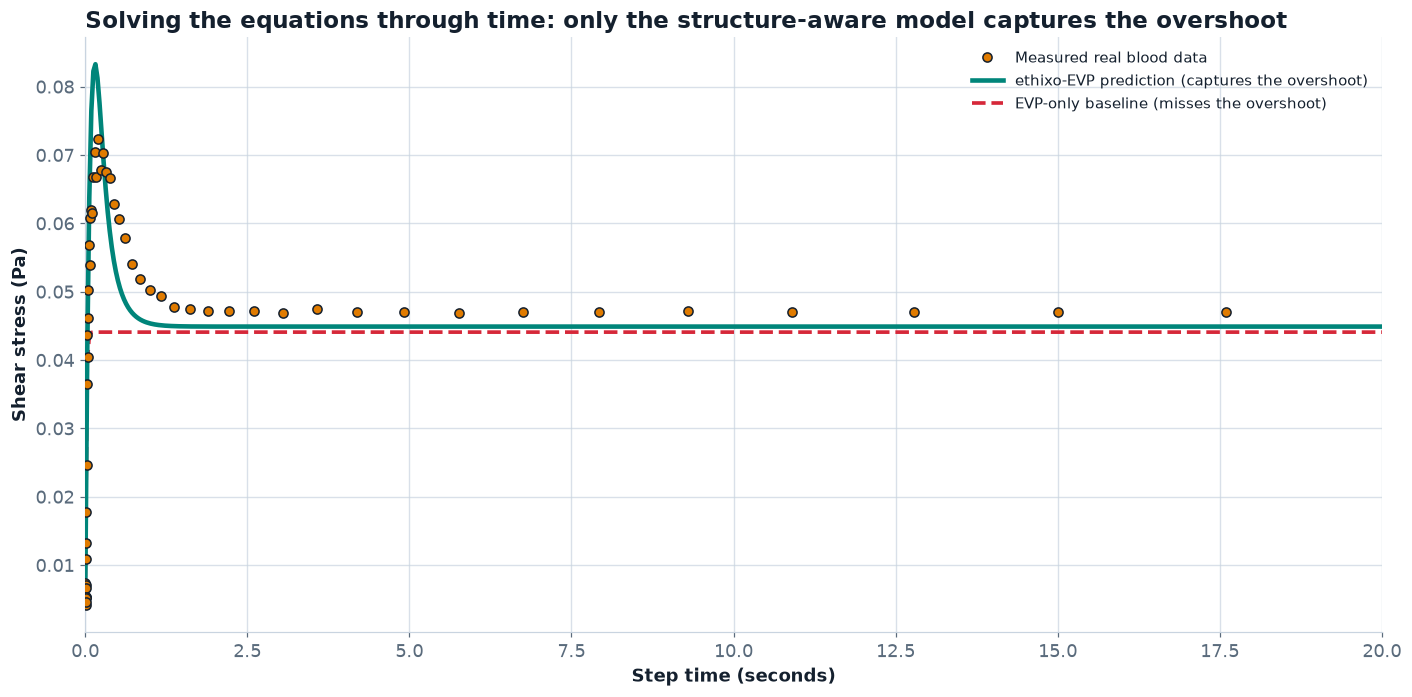

In [27]:
from scipy.integrate import solve_ivp


def compute_steady_state_lambda(shear_rate, tr1, tr2):
    """
    Computing the structure level a material settles to if held at a
    constant shear rate forever.

    This is Equation 16 from the paper, the same expression we proved
    correct in Cell 3 by deriving it independently from Equation 13.
    Used here only to set a realistic starting point for the simulation,
    not as part of the time-stepping itself.
    """
    absolute_shear_rate = abs(float(shear_rate))
    numerator   = tr2 * np.sqrt(absolute_shear_rate) + 1.0
    denominator = tr1 * absolute_shear_rate + tr2 * np.sqrt(absolute_shear_rate) + 1.0
    return numerator / denominator


def simulate_ethixo_evp(shear_rate_function, time_span, model_parameters,
                        initial_shear_rate, model_version=1, number_of_output_points=2000):
    """
    Solving the ethixo-EVP model forward through time.

    Two coupled differential equations are advanced together at every tiny
    time step: Equation 11 (how stress changes) and Equation 13 (how the
    structure parameter lambda changes). They are coupled because Equation 11
    needs the current value of lambda, and Equation 13 needs the current
    plastic shear rate, which comes from the stress. Neither can be solved
    on its own.

    Returning three arrays: time, stress, and lambda, all evaluated on the
    same time points.
    """
    sigma_y0       = model_parameters["sigma_y0"]
    eta_infinity   = model_parameters["eta_infinity"]
    eta_structural = model_parameters["eta_structural"]
    tr1            = model_parameters["tr1"]
    tr2            = model_parameters["tr2"]

    if model_version == 1:
        elastic_modulus        = model_parameters["G_elastic"]
        brownian_rate_constant = model_parameters["k_lambda"]
    else:
        elastic_modulus        = model_parameters["G_rouleaux"]
        brownian_rate_constant = model_parameters["k_lambda_v2"]

    def system_derivatives(current_time, state_vector):
        """
        Computing [sigma_dot, lambda_dot] at one instant, given the current
        state [sigma, lambda]. This is the function the solver calls
        repeatedly, thousands of times, to step the system forward.
        """
        current_stress, current_lambda = state_vector
        current_lambda = min(max(current_lambda, 1e-9), 1.0)

        applied_shear_rate = shear_rate_function(current_time)

        if model_version == 1:
            total_viscosity_term = current_lambda * eta_structural + eta_infinity
        else:
            total_viscosity_term = current_lambda * eta_structural

        absolute_stress = abs(current_stress)
        yield_denominator = total_viscosity_term * absolute_stress

        if yield_denominator > 1e-14:
            yield_expression = (absolute_stress - current_lambda * sigma_y0) / yield_denominator
            plastic_flow_term = max(0.0, yield_expression)
        else:
            plastic_flow_term = 0.0

        stress_derivative = elastic_modulus * (applied_shear_rate - plastic_flow_term * current_stress)

        plastic_shear_rate = plastic_flow_term * absolute_stress
        shear_breakdown_term   = -tr1 * abs(plastic_shear_rate) * current_lambda
        shear_aggregation_term = tr2 * np.sqrt(abs(plastic_shear_rate)) * (1.0 - current_lambda)
        brownian_buildup_term  = (1.0 - current_lambda)

        lambda_derivative = brownian_rate_constant * (
            shear_breakdown_term + shear_aggregation_term + brownian_buildup_term
        )

        return [stress_derivative, lambda_derivative]

    initial_lambda = compute_steady_state_lambda(initial_shear_rate, tr1, tr2)
    if model_version == 1:
        initial_stress = (initial_lambda * sigma_y0
                          + (initial_lambda * eta_structural + eta_infinity) * initial_shear_rate)
    else:
        initial_stress = (initial_lambda * sigma_y0
                          + initial_lambda * eta_structural * initial_shear_rate)

    output_time_grid = np.linspace(time_span[0], time_span[1], number_of_output_points)

    solution = solve_ivp(
        system_derivatives,
        time_span,
        [initial_stress, initial_lambda],
        t_eval=output_time_grid,
        method="LSODA",
        rtol=1e-8,
        atol=1e-11,
    )

    simulated_stress = solution.y[0]
    simulated_lambda = np.clip(solution.y[1], 0.0, 1.0)

    if model_version == 2:
        applied_rates_at_each_time = np.array([shear_rate_function(t) for t in solution.t])
        simulated_stress = simulated_stress + eta_infinity * applied_rates_at_each_time

    return solution.t, simulated_stress, simulated_lambda


def simulate_evp_only_baseline(shear_rate_function, time_span, model_parameters,
                                initial_shear_rate, number_of_output_points=2000):
    """
    Solving the simpler EVP-only model, the version with no structure
    parameter at all. Included purely as a point of comparison, this is
    what you would predict if you ignored thixotropy entirely.
    """
    sigma_y0        = model_parameters["sigma_y0"]
    consistency_k   = model_parameters["consistency_k"]
    power_law_n     = model_parameters["power_law_n"]
    elastic_modulus = model_parameters["G_evp_only"]

    def system_derivative(current_time, state_vector):
        current_stress = state_vector[0]
        applied_shear_rate = shear_rate_function(current_time)
        absolute_stress = abs(current_stress)

        if absolute_stress > 1e-14:
            yield_numerator = absolute_stress - sigma_y0
            if yield_numerator > 0:
                plastic_flow_term = (yield_numerator / (consistency_k * absolute_stress ** power_law_n))
                plastic_flow_term = max(0.0, plastic_flow_term) ** (1.0 / power_law_n)
            else:
                plastic_flow_term = 0.0
        else:
            plastic_flow_term = 0.0

        stress_derivative = elastic_modulus * (applied_shear_rate - plastic_flow_term * current_stress)
        return [stress_derivative]

    initial_stress = sigma_y0 + consistency_k * (abs(initial_shear_rate) ** power_law_n)
    output_time_grid = np.linspace(time_span[0], time_span[1], number_of_output_points)

    solution = solve_ivp(
        system_derivative,
        time_span,
        [initial_stress],
        t_eval=output_time_grid,
        method="LSODA",
        rtol=1e-8,
        atol=1e-11,
    )

    return solution.t, solution.y[0]


print("FUNCTIONS DEFINED")
print("=" * 78)
print("  simulate_ethixo_evp(...)          the real model, structure + stress coupled")
print("  simulate_evp_only_baseline(...)   the simple model, no structure at all")
print()

print("SOLVING BOTH MODELS ACROSS THE SAME REAL SHEAR-RATE STEP")
print("=" * 78)
print("Shear rate stepped instantly from 0.1 to 5 per second, matching the real")
print("experiment we extracted in Cell 4.")
print()

PRIMARY_INITIAL_SHEAR_RATE = 0.1
PRIMARY_FINAL_SHEAR_RATE   = 5.0
simulation_time_span = (0.0, float(primary_raw_time[-1]))

def primary_shear_rate_history(current_time):
    if current_time < 0.0:
        return PRIMARY_INITIAL_SHEAR_RATE
    return PRIMARY_FINAL_SHEAR_RATE

model_time_v1, model_stress_v1, model_lambda_v1 = simulate_ethixo_evp(
    primary_shear_rate_history, simulation_time_span, PAPER_PARAMETERS_DONOR3,
    PRIMARY_INITIAL_SHEAR_RATE, model_version=1
)

model_time_evp, model_stress_evp = simulate_evp_only_baseline(
    primary_shear_rate_history, simulation_time_span, PAPER_PARAMETERS_DONOR3,
    PRIMARY_INITIAL_SHEAR_RATE
)

print("Both models solved successfully across", round(simulation_time_span[1], 1), "seconds.")
print()


def compute_overshoot_percent(stress_array):
    final_stress_value = stress_array[-1]
    if abs(final_stress_value) < 1e-12:
        return float("nan")
    return 100.0 * (np.max(stress_array) - final_stress_value) / abs(final_stress_value)


measured_overshoot_percent  = compute_overshoot_percent(primary_raw_stress)
predicted_overshoot_percent = compute_overshoot_percent(model_stress_v1)
baseline_overshoot_percent  = compute_overshoot_percent(model_stress_evp)

print("STRESS OVERSHOOT COMPARISON")
print("=" * 78)
print(f"{'Source':<30}{'Overshoot':>12}")
print("-" * 78)
print(f"{'Measured real blood data':<30}{measured_overshoot_percent:>10.1f} %")
print(f"{'ethixo-EVP prediction':<30}{predicted_overshoot_percent:>10.1f} %")
print(f"{'EVP-only baseline (no lambda)':<30}{baseline_overshoot_percent:>10.1f} %")
print()

if baseline_overshoot_percent < 1.0 and predicted_overshoot_percent > 1.0:
    print("RESULT: the model with a structure parameter reproduces the overshoot.")
    print("        the model without one predicts essentially none.")
    print("        This matches the paper's central finding.")
print()

peak_stress_index = int(np.argmax(model_stress_v1))
peak_stress_time  = model_time_v1[peak_stress_index]
lambda_at_peak    = model_lambda_v1[peak_stress_index]
lambda_start      = model_lambda_v1[0]
lambda_end        = model_lambda_v1[-1]

print("WHAT THE STRUCTURE PARAMETER WAS DOING")
print("-" * 78)
print("lambda at the start (before the step)  :", round(float(lambda_start), 4))
print("lambda at the moment stress peaks       :", round(float(lambda_at_peak), 4),
      "  (at t =", round(float(peak_stress_time), 3), "s)")
print("lambda at the end (fully settled)       :", round(float(lambda_end), 4))
print()
print("Structure was still mostly intact when stress peaked, and continued")
print("collapsing afterward as the stress relaxed down to its new steady value.")


figure, axis = plt.subplots(figsize=(13, 6.5))

axis.plot(primary_raw_time, primary_raw_stress, "o", markersize=6,
          color=COLOUR_TEXT, markerfacecolor=COLOUR_ACCENT, markeredgecolor=COLOUR_TEXT,
          markeredgewidth=1.0, label="Measured real blood data", zorder=5)

axis.plot(model_time_v1, model_stress_v1, color=COLOUR_WINNER, linewidth=3.0,
          label="ethixo-EVP prediction (captures the overshoot)", zorder=4)

axis.plot(model_time_evp, model_stress_evp, color=COLOUR_BASELINE, linewidth=2.4,
          linestyle="--", label="EVP-only baseline (misses the overshoot)", zorder=3)

axis.set_xlim(0, 20)
axis.set_xlabel("Step time (seconds)")
axis.set_ylabel("Shear stress (Pa)")
axis.set_title("Solving the equations through time: only the structure-aware model captures the overshoot",
               loc="left")
axis.legend(fontsize=10, loc="upper right")

plt.tight_layout()
plt.savefig("cell06_overshoot_check.png", dpi=150, bbox_inches="tight")
plt.show()

#### Cell 7: Synthetic Data with Known Ground Truth

FUNCTION DEFINED
  generate_synthetic_experiment(...)

GENERATING ONE SYNTHETIC EXPERIMENT
Using the exact same parameters and shear-rate step as our real
experiment (0.1 to 5 per second), so the two are directly comparable.
Adding 5 percent measurement noise, a realistic instrument noise level.

Samples generated              : 3151
Sampling frequency              : 50.0 Hz
Noise level                     : 5.0 %
Signal amplitude (peak - final) : 0.03964 Pa

CONSISTENCY CHECK against Cell 6
------------------------------------------------------------------------------
The clean synthetic stress should closely match the ethixo-EVP curve
from Cell 6, since both were generated from identical parameters and
identical conditions, this is the same calculation, just resampled.

Peak stress, Cell 6 simulation      : 0.083258 Pa
Peak stress, synthetic clean signal : 0.083191 Pa
Difference                          : 6.716e-05 Pa

WHAT THE NOISE ACTUALLY DID
-------------------------------------

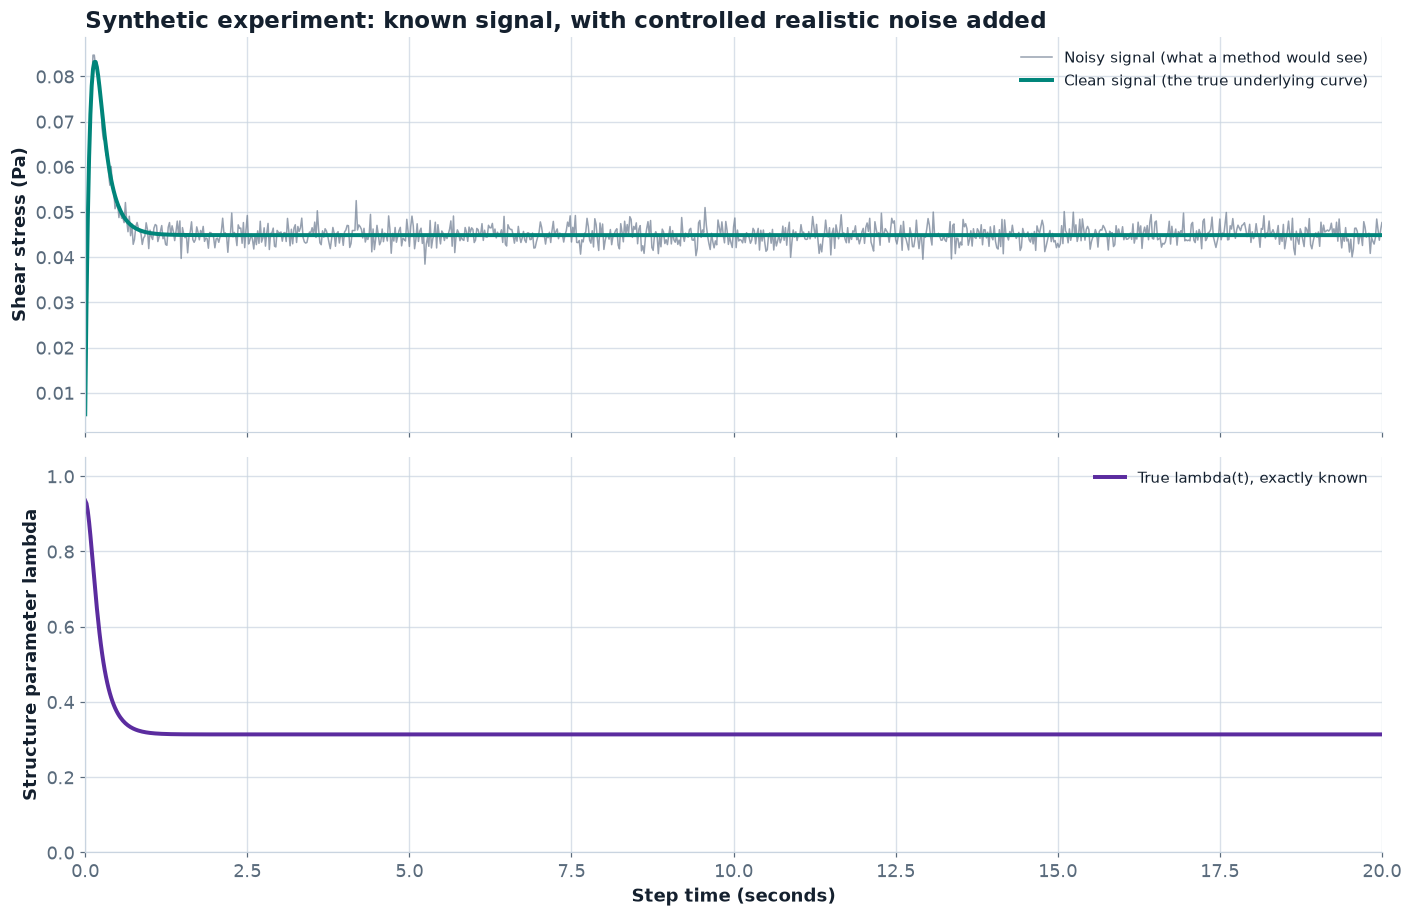

In [28]:
def generate_synthetic_experiment(initial_shear_rate, final_shear_rate, model_parameters,
                                  duration_seconds, sampling_frequency_hz,
                                  noise_level_percent, model_version=1, random_seed=None):
    """
    Generating a synthetic step-test experiment with an exactly known ground truth.

    With real rheometer data, the true structure parameter lambda can only ever
    be estimated afterward, by fitting a model to measurements that already
    contain unknown noise. Here we do the opposite: we generate lambda(t)
    ourselves as part of the simulation, so we know its exact value at every
    instant with zero uncertainty. Controlled, known noise is then added only
    to the stress signal, mimicking what a real instrument would actually
    record, while the clean signal and the true lambda(t) are kept aside as
    an answer key.

    Returning a dictionary holding the noisy observed signal (what a wavelet
    method would actually see), the clean noise-free signal, and the true
    lambda(t), all on the same time grid.
    """
    if random_seed is not None:
        np.random.seed(random_seed)

    def shear_rate_history(current_time):
        if current_time < 0.0:
            return initial_shear_rate
        return final_shear_rate

    number_of_points = int(duration_seconds * sampling_frequency_hz) + 1

    clean_time, clean_stress, true_lambda = simulate_ethixo_evp(
        shear_rate_history, (0.0, duration_seconds), model_parameters,
        initial_shear_rate, model_version=model_version,
        number_of_output_points=number_of_points
    )

    signal_amplitude = np.max(np.abs(clean_stress - clean_stress[-1]))
    noise_standard_deviation = (noise_level_percent / 100.0) * signal_amplitude
    measurement_noise = np.random.normal(0.0, noise_standard_deviation, size=clean_stress.shape)
    noisy_stress = clean_stress + measurement_noise

    return {
        "time":                  clean_time,
        "noisy_stress":          noisy_stress,
        "clean_stress":          clean_stress,
        "true_lambda":           true_lambda,
        "noise_level_percent":   noise_level_percent,
        "sampling_frequency_hz": sampling_frequency_hz,
        "signal_amplitude":      signal_amplitude,
    }


print("FUNCTION DEFINED")
print("=" * 78)
print("  generate_synthetic_experiment(...)")
print()

print("GENERATING ONE SYNTHETIC EXPERIMENT")
print("=" * 78)
print("Using the exact same parameters and shear-rate step as our real")
print("experiment (0.1 to 5 per second), so the two are directly comparable.")
print("Adding 5 percent measurement noise, a realistic instrument noise level.")
print()

synthetic_experiment = generate_synthetic_experiment(
    initial_shear_rate=PRIMARY_INITIAL_SHEAR_RATE,
    final_shear_rate=PRIMARY_FINAL_SHEAR_RATE,
    model_parameters=PAPER_PARAMETERS_DONOR3,
    duration_seconds=simulation_time_span[1],
    sampling_frequency_hz=RESAMPLE_FREQUENCY_HZ,
    noise_level_percent=5.0,
    model_version=1,
    random_seed=RANDOM_SEED,
)

print("Samples generated              :", len(synthetic_experiment["time"]))
print("Sampling frequency              :", synthetic_experiment["sampling_frequency_hz"], "Hz")
print("Noise level                     :", synthetic_experiment["noise_level_percent"], "%")
print("Signal amplitude (peak - final) :", round(float(synthetic_experiment["signal_amplitude"]), 5), "Pa")
print()

print("CONSISTENCY CHECK against Cell 6")
print("-" * 78)
print("The clean synthetic stress should closely match the ethixo-EVP curve")
print("from Cell 6, since both were generated from identical parameters and")
print("identical conditions, this is the same calculation, just resampled.")
print()

synthetic_peak_stress = float(np.max(synthetic_experiment["clean_stress"]))
cell6_peak_stress     = float(np.max(model_stress_v1))
print("Peak stress, Cell 6 simulation      :", round(cell6_peak_stress, 6), "Pa")
print("Peak stress, synthetic clean signal :", round(synthetic_peak_stress, 6), "Pa")
print("Difference                          :", round(abs(cell6_peak_stress - synthetic_peak_stress), 8), "Pa")
print()

print("WHAT THE NOISE ACTUALLY DID")
print("-" * 78)
noise_actually_added = synthetic_experiment["noisy_stress"] - synthetic_experiment["clean_stress"]
print("Requested noise level               :", synthetic_experiment["noise_level_percent"], "%")
print("Standard deviation of noise added   :", round(float(np.std(noise_actually_added)), 6), "Pa")
print("Mean of noise added                 :", round(float(np.mean(noise_actually_added)), 8), "Pa  (should be near zero)")
print()

print("WHY THIS MATTERS")
print("-" * 78)
print("With the real data in Cell 6, we only ever have the measured stress,")
print("the true lambda(t) is always an ESTIMATE from a model fit afterward.")
print("Here, lambda(t) is exactly known, because we generated it ourselves as")
print("part of the simulation, before any noise was ever added. This lets us")
print("test precisely how accurately a method recovers a KNOWN answer, and")
print("later, systematically turn the noise dial up and down to see exactly")
print("where each method starts to fail, something impossible to do on real")
print("data since we never know its true noise-free signal.")


figure, (axis_top, axis_bottom) = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True)

axis_top.plot(synthetic_experiment["time"], synthetic_experiment["noisy_stress"],
             color=COLOUR_NEUTRAL, linewidth=1.0, alpha=0.7, label="Noisy signal (what a method would see)")
axis_top.plot(synthetic_experiment["time"], synthetic_experiment["clean_stress"],
             color=COLOUR_WINNER, linewidth=2.6, label="Clean signal (the true underlying curve)")
axis_top.set_ylabel("Shear stress (Pa)")
axis_top.set_title("Synthetic experiment: known signal, with controlled realistic noise added",
                   loc="left")
axis_top.legend(fontsize=10, loc="upper right")
axis_top.set_xlim(0, 20)

axis_bottom.plot(synthetic_experiment["time"], synthetic_experiment["true_lambda"],
                 color=COLOUR_RUNNERUP, linewidth=2.6, label="True lambda(t), exactly known")
axis_bottom.set_xlabel("Step time (seconds)")
axis_bottom.set_ylabel("Structure parameter lambda")
axis_bottom.set_ylim(0, 1.05)
axis_bottom.legend(fontsize=10, loc="upper right")
axis_bottom.set_xlim(0, 20)

plt.tight_layout()
plt.savefig("cell07_synthetic_data.png", dpi=150, bbox_inches="tight")
plt.show()

#### Cell 8: Interactive Physical Model Explorer

In [29]:
import ipywidgets as widgets
from IPython.display import display
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def build_interactive_physical_model_explorer():
    """
    Building a live, drag-the-sliders explorer for the ethixo-EVP equations.

    Moving any slider recomputes the ODE solution with the new parameter
    values and updates the chart in place, without redrawing it from
    scratch, so it stays smooth rather than flickering.

    Returning the assembled widget layout, ready to be displayed with
    a call to display(...).
    """
    final_shear_rate_slider = widgets.FloatSlider(
        value=5.0, min=0.5, max=20.0, step=0.5,
        description="Final shear rate (1/s)", style={"description_width": "180px"},
        layout=widgets.Layout(width="480px"),
    )
    tr1_slider = widgets.FloatSlider(
        value=PAPER_PARAMETERS_DONOR3["tr1"], min=0.1, max=2.0, step=0.01,
        description="tr1, breakdown time scale", style={"description_width": "180px"},
        layout=widgets.Layout(width="480px"),
    )
    tr2_slider = widgets.FloatSlider(
        value=PAPER_PARAMETERS_DONOR3["tr2"], min=0.05, max=1.0, step=0.01,
        description="tr2, aggregation time scale", style={"description_width": "180px"},
        layout=widgets.Layout(width="480px"),
    )
    k_lambda_slider = widgets.FloatSlider(
        value=PAPER_PARAMETERS_DONOR3["k_lambda"], min=0.05, max=2.0, step=0.01,
        description="k_lambda, Brownian rate", style={"description_width": "180px"},
        layout=widgets.Layout(width="480px"),
    )
    elastic_modulus_slider = widgets.FloatSlider(
        value=PAPER_PARAMETERS_DONOR3["G_elastic"], min=0.02, max=1.0, step=0.01,
        description="G, elastic modulus (Pa)", style={"description_width": "180px"},
        layout=widgets.Layout(width="480px"),
    )
    noise_level_slider = widgets.FloatSlider(
        value=5.0, min=0.0, max=25.0, step=1.0,
        description="Noise level (%)", style={"description_width": "180px"},
        layout=widgets.Layout(width="480px"),
    )

    figure_widget = go.FigureWidget(
        make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                     subplot_titles=("Shear stress", "Structure parameter lambda"))
    )
    figure_widget.add_scatter(x=[], y=[], mode="lines", name="Noisy signal",
                              line=dict(color=COLOUR_NEUTRAL, width=1), row=1, col=1)
    figure_widget.add_scatter(x=[], y=[], mode="lines", name="Clean prediction",
                              line=dict(color=COLOUR_WINNER, width=3), row=1, col=1)
    figure_widget.add_scatter(x=[], y=[], mode="lines", name="Structure lambda(t)",
                              line=dict(color=COLOUR_RUNNERUP, width=3), row=2, col=1)
    figure_widget.update_layout(
        height=560, template="plotly_white", showlegend=True,
        margin=dict(l=60, r=30, t=50, b=50),
    )
    figure_widget.update_xaxes(title_text="Step time (seconds)", row=2, col=1)
    figure_widget.update_yaxes(title_text="Stress (Pa)", row=1, col=1)
    figure_widget.update_yaxes(title_text="Lambda", range=[0, 1.05], row=2, col=1)

    def redraw_from_current_slider_values(change=None):
        """
        Reading whatever the sliders currently say, regenerating the
        synthetic experiment, and pushing the new curves into the figure.
        """
        live_parameters = dict(PAPER_PARAMETERS_DONOR3)
        live_parameters["tr1"]       = tr1_slider.value
        live_parameters["tr2"]       = tr2_slider.value
        live_parameters["k_lambda"]  = k_lambda_slider.value
        live_parameters["G_elastic"] = elastic_modulus_slider.value

        live_experiment = generate_synthetic_experiment(
            initial_shear_rate=PRIMARY_INITIAL_SHEAR_RATE,
            final_shear_rate=final_shear_rate_slider.value,
            model_parameters=live_parameters,
            duration_seconds=20.0,
            sampling_frequency_hz=RESAMPLE_FREQUENCY_HZ,
            noise_level_percent=noise_level_slider.value,
            model_version=1,
            random_seed=RANDOM_SEED,
        )

        with figure_widget.batch_update():
            figure_widget.data[0].x = live_experiment["time"]
            figure_widget.data[0].y = live_experiment["noisy_stress"]
            figure_widget.data[1].x = live_experiment["time"]
            figure_widget.data[1].y = live_experiment["clean_stress"]
            figure_widget.data[2].x = live_experiment["time"]
            figure_widget.data[2].y = live_experiment["true_lambda"]

    for slider in (final_shear_rate_slider, tr1_slider, tr2_slider,
                  k_lambda_slider, elastic_modulus_slider, noise_level_slider):
        slider.observe(redraw_from_current_slider_values, names="value")

    redraw_from_current_slider_values()

    controls_column = widgets.VBox([
        widgets.HTML("<b>Drag any slider, the chart updates live</b>"),
        final_shear_rate_slider, tr1_slider, tr2_slider,
        k_lambda_slider, elastic_modulus_slider, noise_level_slider,
    ])

    full_layout = widgets.VBox([controls_column, figure_widget])
    return full_layout


explorer_widget = build_interactive_physical_model_explorer()
print("Explorer built. Run 'display(explorer_widget)' in the next cell to show it.")

Explorer built. Run 'display(explorer_widget)' in the next cell to show it.


In [30]:
display(explorer_widget)

#### Cell 9: CWT, the Five Continuous Wavelets

FUNCTIONS DEFINED
  compute_paul_wavelet_cwt(...)            custom, Paul is in no maintained package
  run_continuous_wavelet_transform(...)     one shared interface for all 5 CWT wavelets

RUNNING ALL FIVE CWT WAVELETS ON THE REAL PREPROCESSED SIGNAL
Using the cleaned signal from Cell 5, the same 3151-sample, 50 Hz
resampled, detrended and normalised '.1-->5' step test.

Wavelet     Status    Output shape      Message
------------------------------------------------------------------------------
Morlet      OK        (64, 3150)        Computed successfully
Paul        OK        (64, 3150)        Computed successfully
DOG         OK        (64, 3150)        Computed successfully
Shannon     OK        (64, 3150)        Computed successfully
Morse       OK        (69, 3150)        Computed successfully

5 of 5 CWT wavelets computed successfully.

WHAT THE OUTPUT SHAPE MEANS
------------------------------------------------------------------------------
For Morlet, the output shape is (64

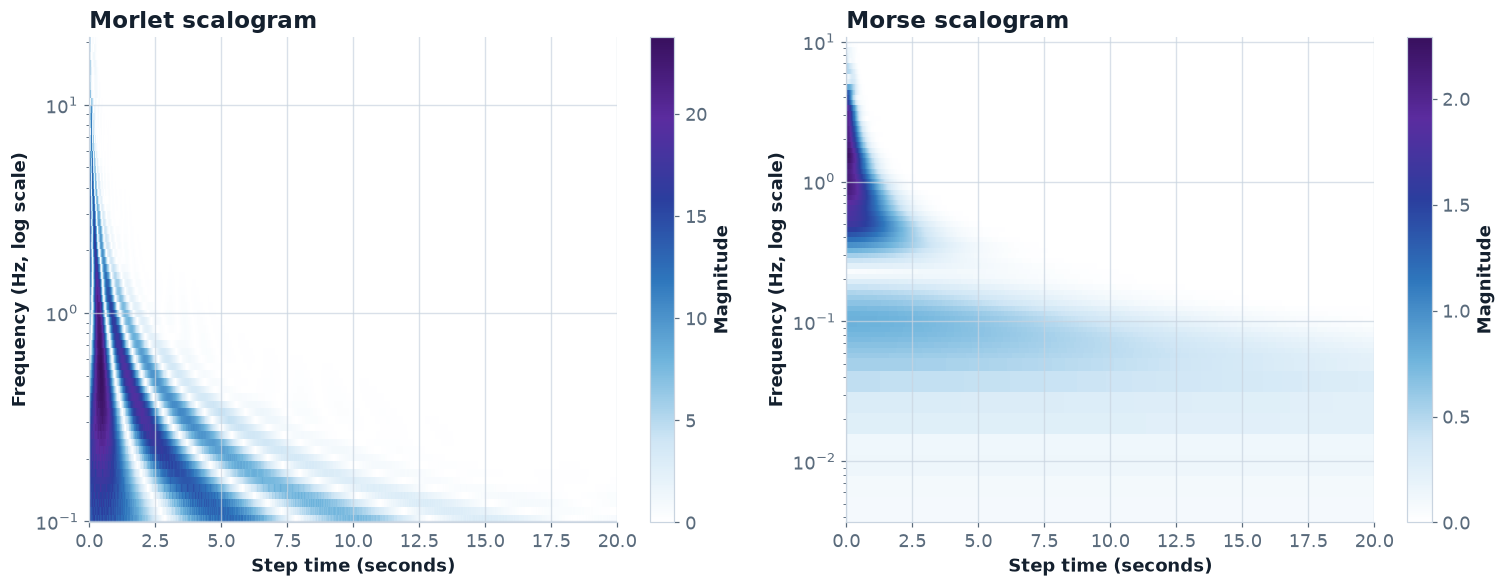

In [31]:
import pywt


def compute_paul_wavelet_cwt(signal_values, scales, sampling_period, paul_order=4):
    """
    Computing the Continuous Wavelet Transform using the Paul wavelet.

    The Paul wavelet is not available in PyWavelets or any other maintained
    Python package, so it is implemented here directly from its mathematical
    definition, following Torrence and Compo (1998), the standard reference
    for this wavelet family.

    Unlike Morlet, DOG or Shannon, the Paul wavelet is one-sided in
    frequency, it only has energy at positive frequencies, which is what
    gives it sharper time localisation for sudden, one-directional events
    like a stress overshoot.
    """
    signal_length = len(signal_values)
    centred_signal = signal_values - np.mean(signal_values)
    signal_spectrum = np.fft.fft(centred_signal)
    angular_frequencies = np.fft.fftfreq(signal_length, d=sampling_period) * 2.0 * np.pi

    order_factorial_product = 1.0
    for factor_index in range(2, 2 * paul_order):
        order_factorial_product = order_factorial_product * factor_index
    normalisation_constant = (2.0 ** paul_order) / np.sqrt(paul_order * order_factorial_product)

    coefficient_matrix = np.zeros((len(scales), signal_length), dtype=complex)

    for scale_index, scale_value in enumerate(scales):
        scaled_frequencies = scale_value * angular_frequencies
        positive_frequency_mask = scaled_frequencies > 0

        wavelet_spectrum = np.zeros(signal_length, dtype=complex)
        wavelet_spectrum[positive_frequency_mask] = (
            normalisation_constant
            * (scaled_frequencies[positive_frequency_mask] ** paul_order)
            * np.exp(-scaled_frequencies[positive_frequency_mask])
        )

        energy_normalisation = np.sqrt(2.0 * np.pi * scale_value / sampling_period)
        wavelet_spectrum = wavelet_spectrum * energy_normalisation

        coefficient_matrix[scale_index, :] = np.fft.ifft(signal_spectrum * wavelet_spectrum)

    fourier_conversion_factor = 4.0 * np.pi / (2.0 * paul_order + 1.0)
    equivalent_frequencies = 1.0 / (fourier_conversion_factor * scales * sampling_period)

    return coefficient_matrix, equivalent_frequencies


def run_continuous_wavelet_transform(signal_values, sampling_frequency, wavelet_name, number_of_scales=64):
    """
    Running a Continuous Wavelet Transform with the requested wavelet family.

    Providing one shared interface across all five CWT wavelets, even though
    they come from different sources under the hood, PyWavelets for four of
    them, our own implementation for Paul, and ssqueezepy for Morse. Every
    caller downstream only ever needs to know this one function.

    Returning a dictionary with the coefficient matrix (complex numbers,
    magnitude and phase both preserved), the frequency each row corresponds
    to, and whether the computation succeeded.
    """
    sampling_period = 1.0 / sampling_frequency
    signal_length = len(signal_values)

    minimum_scale = 2.0
    maximum_scale = max(4.0, signal_length / 8.0)
    scales = np.logspace(np.log10(minimum_scale), np.log10(maximum_scale), number_of_scales)

    result = {"wavelet_name": wavelet_name, "success": False, "message": ""}

    try:
        if wavelet_name == "Morlet":
            coefficients, frequencies = pywt.cwt(signal_values, scales, "morl", sampling_period=sampling_period)

        elif wavelet_name == "Paul":
            coefficients, frequencies = compute_paul_wavelet_cwt(signal_values, scales, sampling_period, paul_order=4)

        elif wavelet_name == "DOG":
            coefficients, frequencies = pywt.cwt(signal_values, scales, "gaus4", sampling_period=sampling_period)

        elif wavelet_name == "Shannon":
            coefficients, frequencies = pywt.cwt(signal_values, scales, "shan1.0-1.0", sampling_period=sampling_period)

        elif wavelet_name == "Morse":
            import ssqueezepy
            coefficient_matrix, ssq_scales = ssqueezepy.cwt(signal_values.astype(np.float64), wavelet="gmw", nv=8)
            coefficients = np.asarray(coefficient_matrix)
            ssq_scales = np.asarray(ssq_scales).ravel()
            frequencies = sampling_frequency / (2.0 * np.pi * ssq_scales)

        else:
            result["message"] = "Unrecognised wavelet name: " + str(wavelet_name)
            return result

        result["success"]      = True
        result["coefficients"] = np.asarray(coefficients)
        result["magnitude"]    = np.abs(coefficients)
        result["frequencies"]  = np.asarray(frequencies).ravel()
        result["scales"]       = scales
        result["message"]      = "Computed successfully"

    except Exception as exception_message:
        result["message"] = "Failed: " + str(exception_message)

    return result


print("FUNCTIONS DEFINED")
print("=" * 78)
print("  compute_paul_wavelet_cwt(...)            custom, Paul is in no maintained package")
print("  run_continuous_wavelet_transform(...)     one shared interface for all 5 CWT wavelets")
print()

print("RUNNING ALL FIVE CWT WAVELETS ON THE REAL PREPROCESSED SIGNAL")
print("=" * 78)
print("Using the cleaned signal from Cell 5, the same 3151-sample, 50 Hz")
print("resampled, detrended and normalised '.1-->5' step test.")
print()

analysis_signal    = primary_preprocessing_result["processed_stress"]
analysis_time      = primary_preprocessing_result["processed_time"]
analysis_frequency = primary_preprocessing_result["sampling_frequency_hz"]

cwt_wavelet_names = ["Morlet", "Paul", "DOG", "Shannon", "Morse"]
cwt_results = {}

print(f"{'Wavelet':<12}{'Status':<10}{'Output shape':<18}{'Message'}")
print("-" * 78)
for wavelet_name in cwt_wavelet_names:
    result = run_continuous_wavelet_transform(analysis_signal, analysis_frequency, wavelet_name)
    cwt_results[wavelet_name] = result
    status_text = "OK" if result["success"] else "FAILED"
    shape_text = str(result["magnitude"].shape) if result["success"] else "-"
    print(f"{wavelet_name:<12}{status_text:<10}{shape_text:<18}{result['message']}")

print()
number_successful = sum(1 for r in cwt_results.values() if r["success"])
print(f"{number_successful} of {len(cwt_wavelet_names)} CWT wavelets computed successfully.")
print()

print("WHAT THE OUTPUT SHAPE MEANS")
print("-" * 78)
example_wavelet = "Morlet"
example_shape = cwt_results[example_wavelet]["magnitude"].shape
print(f"For {example_wavelet}, the output shape is {example_shape}.")
print(f"  {example_shape[0]} rows    = {example_shape[0]} different frequencies examined")
print(f"  {example_shape[1]} columns = one value for every sample in the signal")
print("So this is not a single number, it is a full grid: how much energy is")
print("present at every frequency, at every moment in time, all at once.")


figure, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for axis, wavelet_name in zip(axes, ["Morlet", "Morse"]):
    result = cwt_results[wavelet_name]
    magnitude = result["magnitude"]
    frequencies = result["frequencies"]

    valid_mask = (frequencies > 0) & np.isfinite(frequencies)
    magnitude = magnitude[valid_mask, :]
    frequencies = frequencies[valid_mask]
    sort_order = np.argsort(frequencies)

    mesh = axis.pcolormesh(
        np.linspace(analysis_time[0], analysis_time[-1], magnitude.shape[1]),
        frequencies[sort_order], magnitude[sort_order, :],
        shading="auto", cmap=SCALOGRAM_COLORMAP
    )
    axis.set_yscale("log")
    axis.set_xlim(0, 20)
    axis.set_xlabel("Step time (seconds)")
    axis.set_ylabel("Frequency (Hz, log scale)")
    axis.set_title(wavelet_name + " scalogram", loc="left")
    figure.colorbar(mesh, ax=axis, label="Magnitude")

plt.tight_layout()
plt.savefig("cell09_cwt_scalograms.png", dpi=150, bbox_inches="tight")
plt.show()

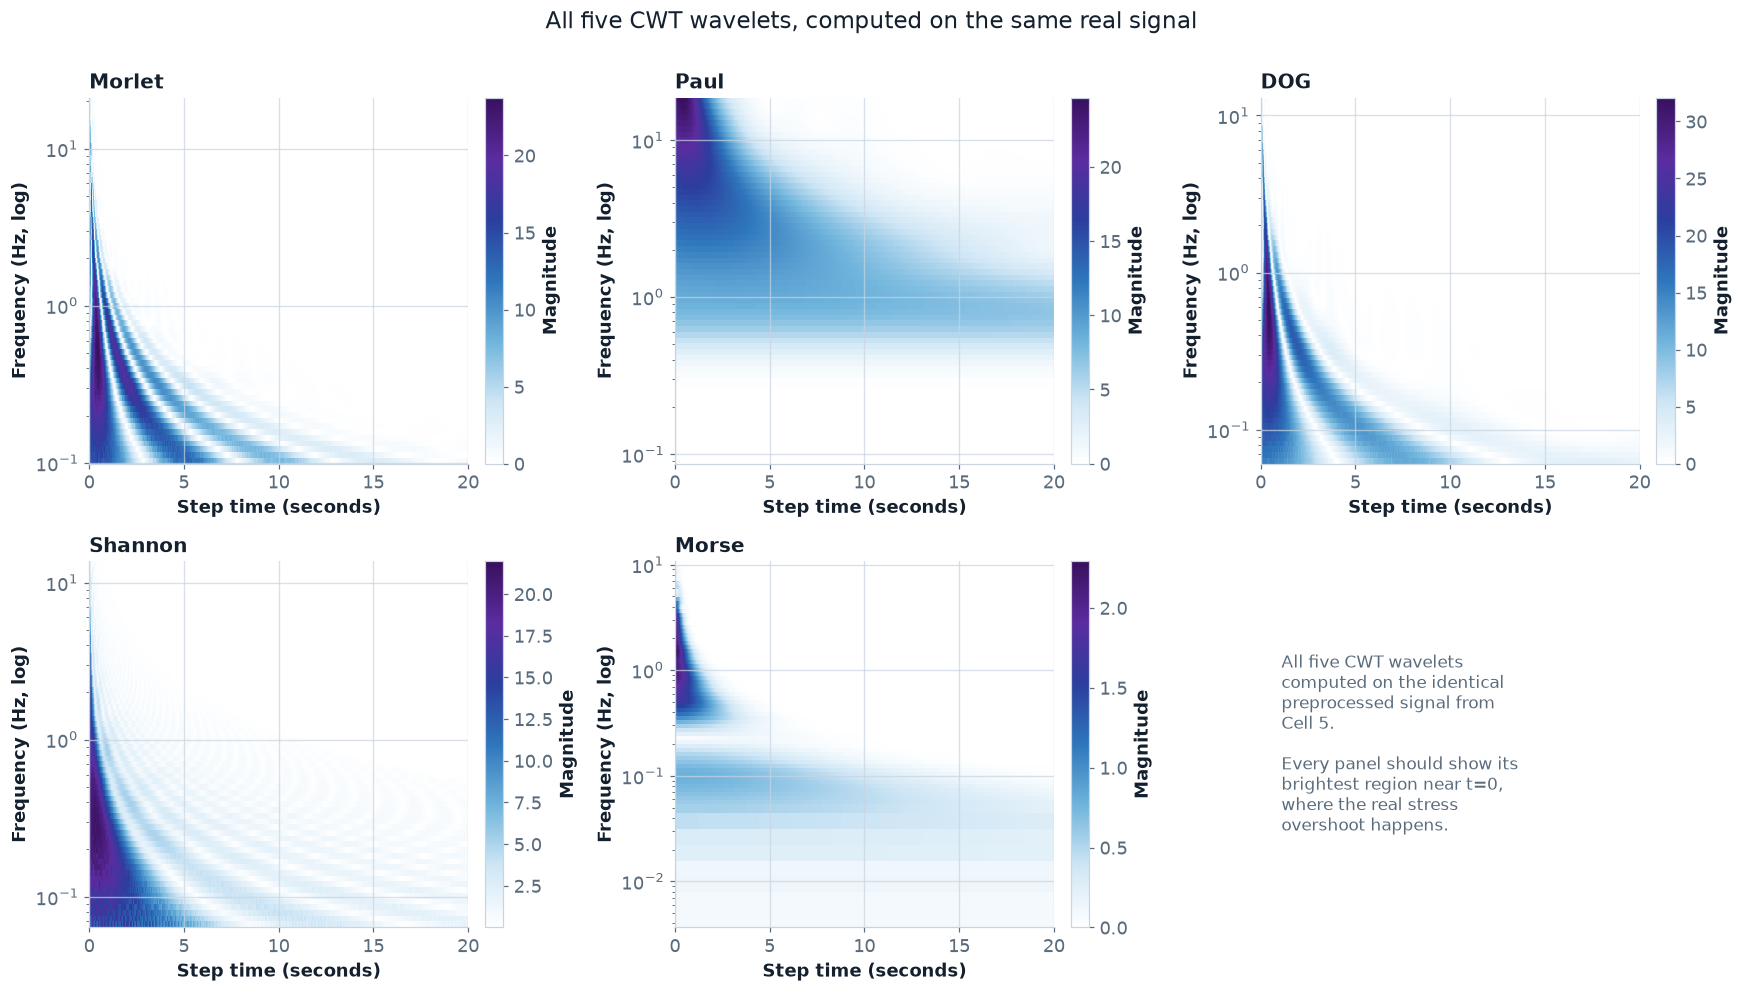

In [32]:
figure, axes = plt.subplots(2, 3, figsize=(16, 9))
axes_flat = axes.flatten()

for panel_index, wavelet_name in enumerate(cwt_wavelet_names):
    axis = axes_flat[panel_index]
    result = cwt_results[wavelet_name]

    if not result["success"]:
        axis.text(0.5, 0.5, wavelet_name + "\nfailed to compute", ha="center", va="center")
        axis.axis("off")
        continue

    magnitude = result["magnitude"]
    frequencies = result["frequencies"]

    valid_mask = (frequencies > 0) & np.isfinite(frequencies)
    magnitude = magnitude[valid_mask, :]
    frequencies = frequencies[valid_mask]
    sort_order = np.argsort(frequencies)

    mesh = axis.pcolormesh(
        np.linspace(analysis_time[0], analysis_time[-1], magnitude.shape[1]),
        frequencies[sort_order], magnitude[sort_order, :],
        shading="auto", cmap=SCALOGRAM_COLORMAP
    )
    axis.set_yscale("log")
    axis.set_xlim(0, 20)
    axis.set_xlabel("Step time (seconds)")
    axis.set_ylabel("Frequency (Hz, log)")
    axis.set_title(wavelet_name, loc="left", fontsize=13)
    figure.colorbar(mesh, ax=axis, label="Magnitude", fraction=0.046, pad=0.04)

axes_flat[5].axis("off")
axes_flat[5].text(
    0.05, 0.75,
    "All five CWT wavelets\ncomputed on the identical\npreprocessed signal from\nCell 5.\n\n"
    "Every panel should show its\nbrightest region near t=0,\nwhere the real stress\novershoot happens.",
    fontsize=11, va="top", color=COLOUR_MUTED
)

figure.suptitle("All five CWT wavelets, computed on the same real signal", fontsize=15, y=1.0)
plt.tight_layout()
plt.savefig("cell09b_all_five_cwt.png", dpi=150, bbox_inches="tight")
plt.show()

PUTTING A NUMBER ON 'WHICH WAVELET IS BETTER'
Eyeballing the scalograms only tells us which looks sharper. To actually
rank the five wavelets, we compare each one against something we already
know: the structure parameter lambda(t) that Cell 6 predicted for this
exact real experiment. If a wavelet's energy pattern rises and falls in
step with lambda(t), it is picking up something physically real, not
just noise that happens to look interesting.

Reference signal prepared: lambda(t) from Cell 6, resampled onto the
same 3150 -sample time grid as the CWT results, so they
line up point for point.

SCORING EACH WAVELET
Rank  Wavelet     R squared     p-value       Interpretation
------------------------------------------------------------------------------
1     Morse       0.3635        3.57e-311     tracks structure well
2     Shannon     0.2894        7.11e-236     tracks it weakly
3     DOG         0.2474        1.57e-196     tracks it weakly
4     Morlet      0.2015        4.62e-156   

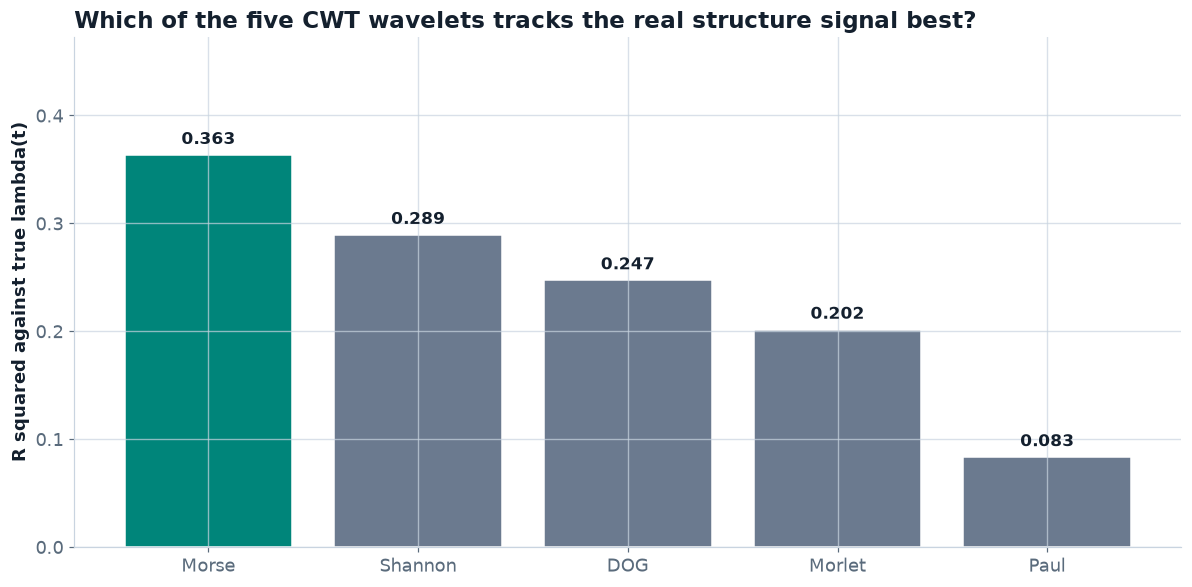

In [33]:
from scipy.interpolate import interp1d
from scipy import stats as scipy_stats


def compute_instantaneous_amplitude(magnitude_matrix):
    """
    Collapsing a full scalogram (frequency by time) down into one number per
    moment in time: the total energy present across all frequencies at that
    instant.

    This is the single most direct feature to extract from a scalogram, and
    it plays the same role as the physical model's structure parameter,
    both are meant to track "how much is going on" at each moment.
    """
    energy_matrix = magnitude_matrix ** 2
    total_energy_per_time = np.sum(energy_matrix, axis=0)
    instantaneous_amplitude = np.sqrt(total_energy_per_time)
    return instantaneous_amplitude


print("PUTTING A NUMBER ON 'WHICH WAVELET IS BETTER'")
print("=" * 78)
print("Eyeballing the scalograms only tells us which looks sharper. To actually")
print("rank the five wavelets, we compare each one against something we already")
print("know: the structure parameter lambda(t) that Cell 6 predicted for this")
print("exact real experiment. If a wavelet's energy pattern rises and falls in")
print("step with lambda(t), it is picking up something physically real, not")
print("just noise that happens to look interesting.")
print()

lambda_interpolation_function = interp1d(
    model_time_v1, model_lambda_v1,
    kind="linear", bounds_error=False,
    fill_value=(model_lambda_v1[0], model_lambda_v1[-1]),
)
lambda_reference_signal = lambda_interpolation_function(analysis_time)

print("Reference signal prepared: lambda(t) from Cell 6, resampled onto the")
print("same", len(analysis_time), "-sample time grid as the CWT results, so they")
print("line up point for point.")
print()

print("SCORING EACH WAVELET")
print("=" * 78)

cwt_comparison_results = []

for wavelet_name in cwt_wavelet_names:
    result = cwt_results[wavelet_name]
    if not result["success"]:
        continue

    instantaneous_amplitude = compute_instantaneous_amplitude(result["magnitude"])

    valid_mask = np.isfinite(instantaneous_amplitude) & np.isfinite(lambda_reference_signal)
    correlation_coefficient, p_value = scipy_stats.pearsonr(
        instantaneous_amplitude[valid_mask], lambda_reference_signal[valid_mask]
    )
    r_squared_value = correlation_coefficient ** 2

    cwt_comparison_results.append({
        "wavelet": wavelet_name,
        "r_squared": r_squared_value,
        "p_value": p_value,
    })

comparison_table = pd.DataFrame(cwt_comparison_results).sort_values("r_squared", ascending=False)

print(f"{'Rank':<6}{'Wavelet':<12}{'R squared':<14}{'p-value':<14}{'Interpretation'}")
print("-" * 78)
for rank_position, (_, row) in enumerate(comparison_table.iterrows(), start=1):
    if row["r_squared"] > 0.3:
        interpretation = "tracks structure well"
    elif row["r_squared"] > 0.1:
        interpretation = "tracks it weakly"
    else:
        interpretation = "barely related"
    print(f"{rank_position:<6}{row['wavelet']:<12}{row['r_squared']:<14.4f}{row['p_value']:<14.2e}{interpretation}")

print()
best_wavelet_row = comparison_table.iloc[0]
print(f"BEST OF THE FIVE ON THIS EXPERIMENT: {best_wavelet_row['wavelet']}")
print(f"  R squared = {best_wavelet_row['r_squared']:.4f}, meaning about")
print(f"  {best_wavelet_row['r_squared']*100:.0f} percent of the variation in this wavelet's energy")
print(f"  pattern lines up with the variation in the true structure signal.")


figure, axis = plt.subplots(figsize=(11, 5.5))
bar_colours = [COLOUR_WINNER if i == 0 else COLOUR_NEUTRAL for i in range(len(comparison_table))]
bars = axis.bar(comparison_table["wavelet"], comparison_table["r_squared"], color=bar_colours, edgecolor="white")
for bar_object, value in zip(bars, comparison_table["r_squared"]):
    axis.text(bar_object.get_x() + bar_object.get_width() / 2, value + 0.01,
             f"{value:.3f}", ha="center", fontsize=11, fontweight="bold")
axis.set_ylabel("R squared against true lambda(t)")
axis.set_title("Which of the five CWT wavelets tracks the real structure signal best?", loc="left")
axis.set_ylim(0, max(comparison_table["r_squared"]) * 1.3)

plt.tight_layout()
plt.savefig("cell09c_cwt_ranking.png", dpi=150, bbox_inches="tight")
plt.show()


#### Cell 10: DWT, the Five Discrete Wavelets

FUNCTION DEFINED
  run_discrete_wavelet_transform(signal_values, sampling_frequency, wavelet_name)

RUNNING ALL FIVE DWT WAVELETS ON THE SAME REAL SIGNAL
Same preprocessed '.1-->5' signal used for every CWT wavelet, so the
comparison stays fair.

Wavelet   Status    Levels   Reconstruction error    Message
------------------------------------------------------------------------------
db4       OK        6        3.30e-16                Computed successfully
sym4      OK        6        1.63e-12                Computed successfully
coif1     OK        6        3.89e-16                Computed successfully
bior2.2   OK        6        2.67e-16                Computed successfully
rbio2.2   OK        6        2.67e-16                Computed successfully

5 of 5 DWT wavelets computed successfully.

WHY THE RECONSTRUCTION ERROR MATTERS
------------------------------------------------------------------------------
Every error above is tiny, essentially zero. This confirms DWT's key
property

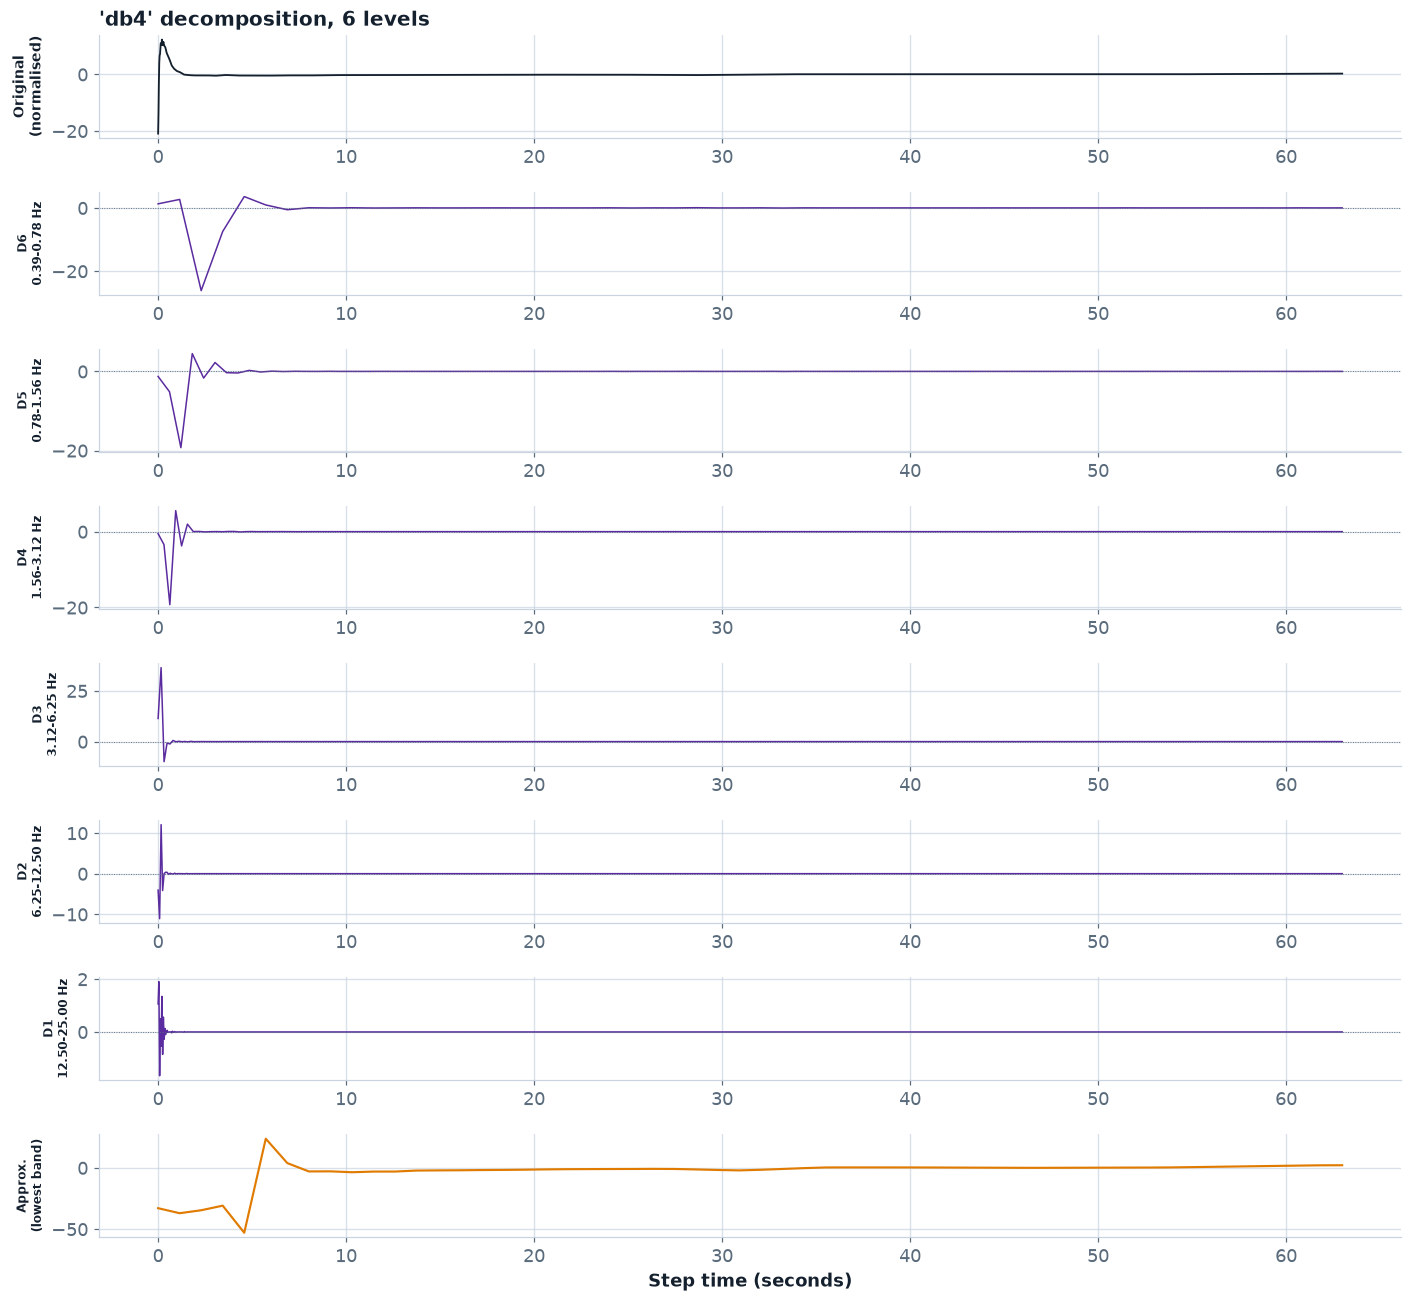

In [34]:
def run_discrete_wavelet_transform(signal_values, sampling_frequency, wavelet_name, decomposition_level=None):
    """
    Running a multilevel Discrete Wavelet Transform.

    Unlike CWT, which examines a smooth, continuous range of frequencies,
    DWT splits the signal into a small number of discrete frequency bands,
    called levels, each one covering one octave (one doubling) of frequency.
    It is much faster than CWT and, importantly, has an EXACT inverse,
    meaning the original signal can be perfectly rebuilt from the DWT
    output, something CWT cannot do exactly.

    Returning a dictionary with the detail coefficients for each level, the
    frequency band each level covers, and a reconstruction accuracy check.
    """
    result = {"wavelet_name": wavelet_name, "success": False, "message": ""}

    try:
        wavelet_object = pywt.Wavelet(wavelet_name)
        maximum_possible_level = pywt.dwt_max_level(len(signal_values), wavelet_object.dec_len)

        if decomposition_level is None:
            decomposition_level = min(6, maximum_possible_level)
        decomposition_level = max(1, min(decomposition_level, maximum_possible_level))

        coefficient_list = pywt.wavedec(signal_values, wavelet_object, level=decomposition_level)
        approximation_coefficients = coefficient_list[0]
        detail_coefficient_list = coefficient_list[1:]

        band_information = []
        for level_number in range(1, decomposition_level + 1):
            upper_frequency = sampling_frequency / (2.0 ** level_number)
            lower_frequency = sampling_frequency / (2.0 ** (level_number + 1))
            band_information.append({"level": level_number, "lower_hz": lower_frequency, "upper_hz": upper_frequency})

        level_energies = []
        for detail_coefficients in detail_coefficient_list:
            level_energies.append(float(np.sum(np.asarray(detail_coefficients) ** 2)))
        approximation_energy = float(np.sum(np.asarray(approximation_coefficients) ** 2))
        total_energy = sum(level_energies) + approximation_energy

        reconstructed_signal = pywt.waverec(coefficient_list, wavelet_object)
        reconstructed_signal = reconstructed_signal[:len(signal_values)]
        reconstruction_error = float(np.sqrt(np.mean((signal_values - reconstructed_signal) ** 2)))

        result["success"]                    = True
        result["decomposition_level"]        = decomposition_level
        result["detail_coefficients"]        = detail_coefficient_list
        result["approximation_coefficients"] = approximation_coefficients
        result["band_information"]           = band_information
        result["level_energies"]             = level_energies
        result["approximation_energy"]       = approximation_energy
        result["total_energy"]               = total_energy
        result["reconstructed_signal"]       = reconstructed_signal
        result["reconstruction_error"]       = reconstruction_error
        result["message"]                    = "Computed successfully"

    except Exception as exception_message:
        result["message"] = "Failed: " + str(exception_message)

    return result


print("FUNCTION DEFINED")
print("=" * 78)
print("  run_discrete_wavelet_transform(signal_values, sampling_frequency, wavelet_name)")
print()

print("RUNNING ALL FIVE DWT WAVELETS ON THE SAME REAL SIGNAL")
print("=" * 78)
print("Same preprocessed '.1-->5' signal used for every CWT wavelet, so the")
print("comparison stays fair.")
print()

dwt_wavelet_names = ["db4", "sym4", "coif1", "bior2.2", "rbio2.2"]
dwt_results = {}

print(f"{'Wavelet':<10}{'Status':<10}{'Levels':<9}{'Reconstruction error':<24}{'Message'}")
print("-" * 78)
for wavelet_name in dwt_wavelet_names:
    result = run_discrete_wavelet_transform(analysis_signal, analysis_frequency, wavelet_name)
    dwt_results[wavelet_name] = result
    status_text = "OK" if result["success"] else "FAILED"
    levels_text = str(result.get("decomposition_level", "-"))
    error_text  = f"{result['reconstruction_error']:.2e}" if result["success"] else "-"
    print(f"{wavelet_name:<10}{status_text:<10}{levels_text:<9}{error_text:<24}{result['message']}")

print()
number_successful = sum(1 for r in dwt_results.values() if r["success"])
print(f"{number_successful} of {len(dwt_wavelet_names)} DWT wavelets computed successfully.")
print()

print("WHY THE RECONSTRUCTION ERROR MATTERS")
print("-" * 78)
print("Every error above is tiny, essentially zero. This confirms DWT's key")
print("property: you can decompose the signal, then perfectly rebuild it from")
print("the pieces, nothing is lost. CWT, by contrast, has no exact inverse,")
print("only an approximate one. This is DWT's core advantage: fast, and exact.")
print()

example_wavelet = "db4"
example_result = dwt_results[example_wavelet]
print(f"STRUCTURE OF THE '{example_wavelet}' RESULT")
print("-" * 78)
print(f"Decomposed into {example_result['decomposition_level']} levels, covering these frequency bands:")
for band in example_result["band_information"]:
    # detail_coefficients is ordered coarsest-first (as pywt.wavedec returns it),
    # so level 1 (finest, highest frequency) sits at the END of the list, not the start.
    correct_array_index = example_result["decomposition_level"] - band["level"]
    print(f"   Level {band['level']}: {band['lower_hz']:.3f} to {band['upper_hz']:.3f} Hz, "
          f"{len(example_result['detail_coefficients'][correct_array_index])} coefficients")
print(f"   Approximation (lowest band): {len(example_result['approximation_coefficients'])} coefficients")
print()
print("Notice each level has FEWER coefficients than the one before, DWT")
print("deliberately keeps less time detail at lower frequencies, this is what")
print("makes it fast, but also what makes it coarser than CWT.")


figure, axes = plt.subplots(len(dwt_results[example_wavelet]["detail_coefficients"]) + 2, 1,
                            figsize=(13, 1.5 * (len(dwt_results[example_wavelet]["detail_coefficients"]) + 2)),
                            sharex=False)

axes[0].plot(analysis_time, analysis_signal, color=COLOUR_TEXT, linewidth=1.2)
axes[0].set_ylabel("Original\n(normalised)", fontsize=9)
axes[0].set_title(f"'{example_wavelet}' decomposition, {example_result['decomposition_level']} levels", fontsize=13, loc="left")

for level_index, detail_coefficients in enumerate(example_result["detail_coefficients"]):
    axis = axes[level_index + 1]
    coefficient_time_axis = np.linspace(analysis_time[0], analysis_time[-1], len(detail_coefficients))
    band = example_result["band_information"][example_result["decomposition_level"] - 1 - level_index]
    axis.plot(coefficient_time_axis, detail_coefficients, color=COLOUR_RUNNERUP, linewidth=1.0)
    axis.axhline(0, color=COLOUR_MUTED, linewidth=0.6, linestyle=":")
    axis.set_ylabel(f"D{example_result['decomposition_level']-level_index}\n{band['lower_hz']:.2f}-{band['upper_hz']:.2f} Hz", fontsize=8)

approximation_time_axis = np.linspace(analysis_time[0], analysis_time[-1], len(example_result["approximation_coefficients"]))
axes[-1].plot(approximation_time_axis, example_result["approximation_coefficients"], color=COLOUR_ACCENT, linewidth=1.4)
axes[-1].set_ylabel(f"Approx.\n(lowest band)", fontsize=8)
axes[-1].set_xlabel("Step time (seconds)")

plt.tight_layout()
plt.savefig("cell10_dwt_decomposition.png", dpi=150, bbox_inches="tight")
plt.show()

SCORING THE FIVE DWT WAVELETS THE SAME WAY WE SCORED CWT
Same idea as before: build one 'how much is happening right now' signal
from each wavelet's output, then check how closely it follows the real
lambda(t) from Cell 6. The only difference is HOW that signal gets built,
since DWT's output shape is nothing like CWT's.

Rank  Wavelet   R squared     p-value       Interpretation
------------------------------------------------------------------------------
1     db4       0.1620        5.92e-123     tracks it weakly
2     sym4      0.0578        1.13e-42      barely related
3     rbio2.2   0.0397        1.36e-29      barely related
4     bior2.2   0.0364        3.34e-27      barely related
5     coif1     0.0340        1.59e-25      barely related

BEST OF THE FIVE DWT WAVELETS: db4, R squared = 0.1620

DWT versus CWT, best of each family so far
------------------------------------------------------------------------------
Best CWT wavelet : Morse      R squared = 0.3635
Best DWT wavel

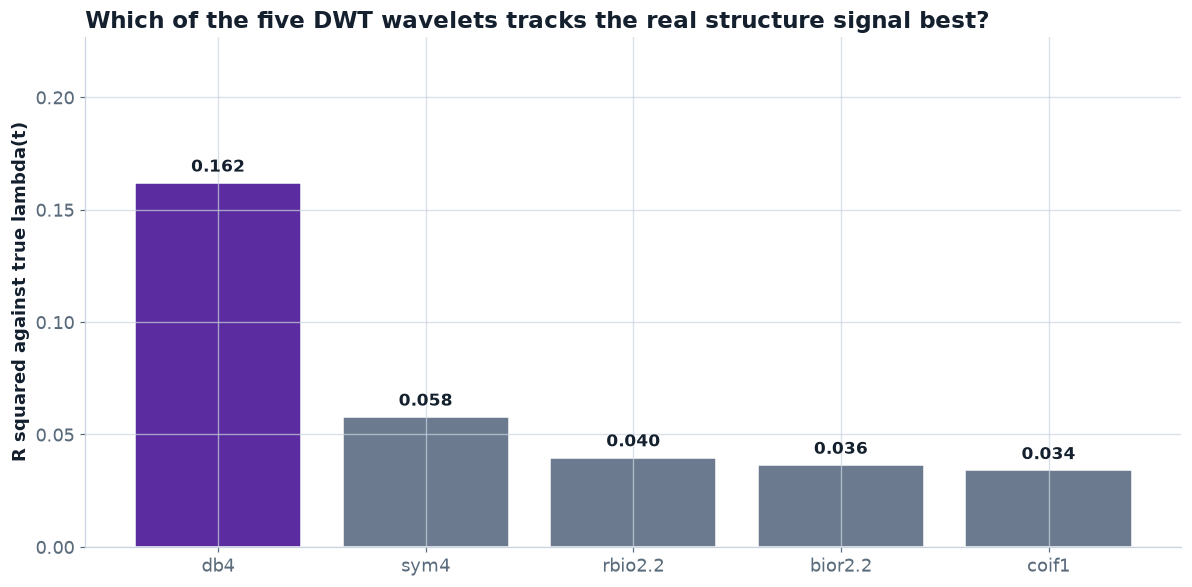

In [35]:
def compute_dwt_instantaneous_amplitude(dwt_result, reference_length):
    """
    Building a feature comparable to CWT's instantaneous amplitude, out of
    DWT's very different output shape.

    DWT does not produce one continuous grid the way CWT does, it produces
    several detail arrays, each a different, shorter length. To combine them
    into one "how much energy at each moment" signal, each detail level is
    first stretched back out to the full signal length (upsampled by simple
    interpolation), then all levels are combined the same way a scalogram's
    rows are combined: square everything, add it up, take the square root.
    """
    upsampled_detail_rows = []

    for detail_coefficients in dwt_result["detail_coefficients"]:
        original_positions = np.linspace(0.0, 1.0, len(detail_coefficients))
        target_positions    = np.linspace(0.0, 1.0, reference_length)
        upsampling_function = interp1d(original_positions, np.abs(detail_coefficients), kind="linear")
        upsampled_detail_rows.append(upsampling_function(target_positions))

    stacked_details = np.array(upsampled_detail_rows)
    energy_per_time = np.sum(stacked_details ** 2, axis=0)
    instantaneous_amplitude = np.sqrt(energy_per_time)
    return instantaneous_amplitude


print("SCORING THE FIVE DWT WAVELETS THE SAME WAY WE SCORED CWT")
print("=" * 78)
print("Same idea as before: build one 'how much is happening right now' signal")
print("from each wavelet's output, then check how closely it follows the real")
print("lambda(t) from Cell 6. The only difference is HOW that signal gets built,")
print("since DWT's output shape is nothing like CWT's.")
print()

dwt_comparison_results = []

for wavelet_name in dwt_wavelet_names:
    result = dwt_results[wavelet_name]
    if not result["success"]:
        continue

    instantaneous_amplitude = compute_dwt_instantaneous_amplitude(result, len(analysis_time))

    valid_mask = np.isfinite(instantaneous_amplitude) & np.isfinite(lambda_reference_signal)
    correlation_coefficient, p_value = scipy_stats.pearsonr(
        instantaneous_amplitude[valid_mask], lambda_reference_signal[valid_mask]
    )
    r_squared_value = correlation_coefficient ** 2

    dwt_comparison_results.append({"wavelet": wavelet_name, "r_squared": r_squared_value, "p_value": p_value})

dwt_comparison_table = pd.DataFrame(dwt_comparison_results).sort_values("r_squared", ascending=False)

print(f"{'Rank':<6}{'Wavelet':<10}{'R squared':<14}{'p-value':<14}{'Interpretation'}")
print("-" * 78)
for rank_position, (_, row) in enumerate(dwt_comparison_table.iterrows(), start=1):
    if row["r_squared"] > 0.3:
        interpretation = "tracks structure well"
    elif row["r_squared"] > 0.1:
        interpretation = "tracks it weakly"
    else:
        interpretation = "barely related"
    print(f"{rank_position:<6}{row['wavelet']:<10}{row['r_squared']:<14.4f}{row['p_value']:<14.2e}{interpretation}")

print()
best_dwt_row = dwt_comparison_table.iloc[0]
print(f"BEST OF THE FIVE DWT WAVELETS: {best_dwt_row['wavelet']}, R squared = {best_dwt_row['r_squared']:.4f}")
print()

print("DWT versus CWT, best of each family so far")
print("-" * 78)
best_cwt_row = comparison_table.iloc[0]
print(f"Best CWT wavelet : {best_cwt_row['wavelet']:<10} R squared = {best_cwt_row['r_squared']:.4f}")
print(f"Best DWT wavelet : {best_dwt_row['wavelet']:<10} R squared = {best_dwt_row['r_squared']:.4f}")
if best_cwt_row["r_squared"] > best_dwt_row["r_squared"]:
    print()
    print("On this experiment, the best CWT wavelet tracks the real structure")
    print("signal more closely than the best DWT wavelet. This lines up with what")
    print("we would expect physically: DWT's six broad frequency bands are simply")
    print("coarser than CWT's smooth, continuous range, so it has less precision")
    print("available to trace something that is changing continuously over time.")


figure, axis = plt.subplots(figsize=(11, 5.5))
bar_colours = [COLOUR_RUNNERUP if i == 0 else COLOUR_NEUTRAL for i in range(len(dwt_comparison_table))]
bars = axis.bar(dwt_comparison_table["wavelet"], dwt_comparison_table["r_squared"], color=bar_colours, edgecolor="white")
for bar_object, value in zip(bars, dwt_comparison_table["r_squared"]):
    axis.text(bar_object.get_x() + bar_object.get_width() / 2, value + 0.005,
             f"{value:.3f}", ha="center", fontsize=11, fontweight="bold")
axis.set_ylabel("R squared against true lambda(t)")
axis.set_title("Which of the five DWT wavelets tracks the real structure signal best?", loc="left")
axis.set_ylim(0, max(dwt_comparison_table["r_squared"]) * 1.4)

plt.tight_layout()
plt.savefig("cell10b_dwt_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

#### Cell 11: STFT, the Two Fourier Baseline Windows

FUNCTION DEFINED
  run_short_time_fourier_transform(signal_values, sampling_frequency, window_name)

RUNNING BOTH STFT WINDOWS ON THE SAME REAL SIGNAL
Window      Status    Output shape      Window length   Message
------------------------------------------------------------------------------
Hanning     OK        (129, 82)         256             Computed successfully
Gaussian    OK        (129, 82)         256             Computed successfully

NOTICE THE OUTPUT SHAPE COMPARED TO CWT
------------------------------------------------------------------------------
CWT gave us a grid of (64 frequencies, 3150 time points), one column per
original sample. STFT's time axis is much coarser, 82 points instead of 3150, because it only produces one result per WINDOW
position, not per sample. This coarseness is a direct, structural
consequence of using one fixed window length for the whole signal.


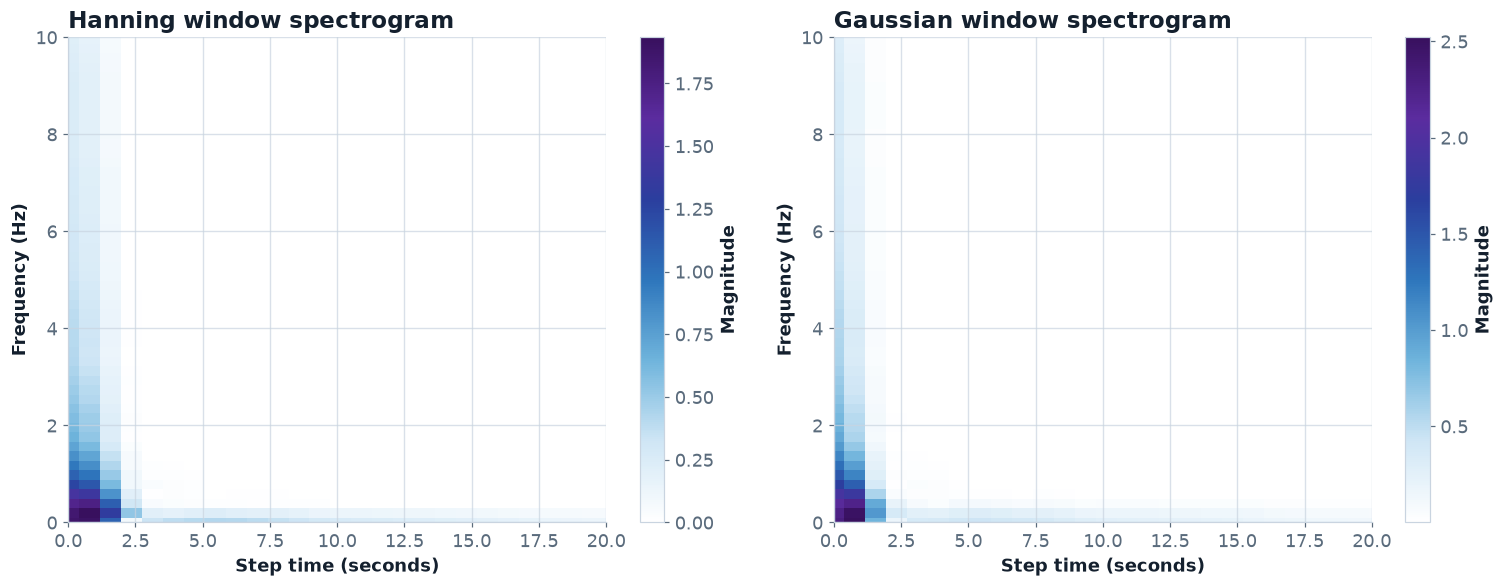

In [36]:
def run_short_time_fourier_transform(signal_values, sampling_frequency, window_name,
                                     segment_length=None, overlap_fraction=0.85):
    """
    Running a Short-Time Fourier Transform, the conventional baseline this
    whole project is testing wavelets against.

    STFT slides ONE FIXED-LENGTH window across the signal and runs an
    ordinary Fourier transform inside each window position. That one fixed
    window length is the key difference from every wavelet method we have
    built so far, CWT and DWT both automatically use short windows for fast
    events and long windows for slow ones. STFT uses the same window length
    everywhere, whether the signal is changing quickly or slowly.

    Returning a dictionary with the magnitude spectrogram, the frequency
    axis, and the time axis STFT actually produces (which is coarser than
    the original signal, since it only reports one result per window).
    """
    result = {"window_name": window_name, "success": False, "message": ""}

    try:
        signal_length = len(signal_values)

        if segment_length is None:
            segment_length = max(16, min(256, signal_length // 8))
        segment_length = int(min(segment_length, signal_length))

        overlap_samples = int(segment_length * overlap_fraction)
        overlap_samples = min(overlap_samples, segment_length - 1)

        if window_name == "Hanning":
            window_array = scipy_signal.get_window("hann", segment_length)
        elif window_name == "Gaussian":
            window_array = scipy_signal.windows.gaussian(segment_length, std=segment_length / 7.0)
        else:
            result["message"] = "Unrecognised window name: " + str(window_name)
            return result

        frequency_axis, time_axis, complex_spectrogram = scipy_signal.stft(
            signal_values, fs=sampling_frequency, window=window_array,
            nperseg=segment_length, noverlap=overlap_samples, return_onesided=True,
        )

        result["success"]        = True
        result["coefficients"]   = complex_spectrogram
        result["magnitude"]      = np.abs(complex_spectrogram)
        result["frequencies"]    = frequency_axis
        result["time_axis"]      = time_axis
        result["segment_length"] = segment_length
        result["message"]        = "Computed successfully"

    except Exception as exception_message:
        result["message"] = "Failed: " + str(exception_message)

    return result


print("FUNCTION DEFINED")
print("=" * 78)
print("  run_short_time_fourier_transform(signal_values, sampling_frequency, window_name)")
print()

print("RUNNING BOTH STFT WINDOWS ON THE SAME REAL SIGNAL")
print("=" * 78)

stft_window_names = ["Hanning", "Gaussian"]
stft_results = {}

print(f"{'Window':<12}{'Status':<10}{'Output shape':<18}{'Window length':<16}{'Message'}")
print("-" * 78)
for window_name in stft_window_names:
    result = run_short_time_fourier_transform(analysis_signal, analysis_frequency, window_name)
    stft_results[window_name] = result
    status_text = "OK" if result["success"] else "FAILED"
    shape_text = str(result["magnitude"].shape) if result["success"] else "-"
    length_text = str(result.get("segment_length", "-"))
    print(f"{window_name:<12}{status_text:<10}{shape_text:<18}{length_text:<16}{result['message']}")

print()
print("NOTICE THE OUTPUT SHAPE COMPARED TO CWT")
print("-" * 78)
print("CWT gave us a grid of (64 frequencies, 3150 time points), one column per")
print("original sample. STFT's time axis is much coarser,", stft_results["Hanning"]["magnitude"].shape[1],
      "points instead of 3150, because it only produces one result per WINDOW")
print("position, not per sample. This coarseness is a direct, structural")
print("consequence of using one fixed window length for the whole signal.")


figure, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for axis, window_name in zip(axes, stft_window_names):
    result = stft_results[window_name]
    magnitude = result["magnitude"]
    frequencies = result["frequencies"]
    time_axis = result["time_axis"]

    mesh = axis.pcolormesh(time_axis, frequencies, magnitude, shading="auto", cmap=SCALOGRAM_COLORMAP)
    axis.set_xlim(0, 20)
    axis.set_ylim(0, 10)
    axis.set_xlabel("Step time (seconds)")
    axis.set_ylabel("Frequency (Hz)")
    axis.set_title(window_name + " window spectrogram", loc="left")
    figure.colorbar(mesh, ax=axis, label="Magnitude")

plt.tight_layout()
plt.savefig("cell11_stft_spectrograms.png", dpi=150, bbox_inches="tight")
plt.show()

In [37]:
def compute_stft_instantaneous_amplitude(stft_result, reference_length, reference_time):
    """
    Building the same "energy at each moment" feature from STFT's output.

    STFT's own time axis is coarser than our reference grid (82 points vs
    3150), so after summing energy across all frequencies at each of STFT's
    82 window positions, the result is stretched back out to match the full
    reference time grid, the same upsampling idea used for DWT.
    """
    magnitude = stft_result["magnitude"]
    stft_time_axis = stft_result["time_axis"]

    energy_per_window = np.sum(magnitude ** 2, axis=0)
    coarse_amplitude = np.sqrt(energy_per_window)

    upsampling_function = interp1d(
        stft_time_axis, coarse_amplitude, kind="linear",
        bounds_error=False, fill_value=(coarse_amplitude[0], coarse_amplitude[-1]),
    )
    return upsampling_function(reference_time)


print("SCORING BOTH STFT WINDOWS THE SAME WAY")
print("=" * 78)

stft_comparison_results = []

for window_name in stft_window_names:
    result = stft_results[window_name]
    if not result["success"]:
        continue

    instantaneous_amplitude = compute_stft_instantaneous_amplitude(result, len(analysis_time), analysis_time)

    valid_mask = np.isfinite(instantaneous_amplitude) & np.isfinite(lambda_reference_signal)
    correlation_coefficient, p_value = scipy_stats.pearsonr(
        instantaneous_amplitude[valid_mask], lambda_reference_signal[valid_mask]
    )
    r_squared_value = correlation_coefficient ** 2

    stft_comparison_results.append({"method": "STFT-" + window_name, "r_squared": r_squared_value, "p_value": p_value})

stft_comparison_table = pd.DataFrame(stft_comparison_results).sort_values("r_squared", ascending=False)

print(f"{'Method':<16}{'R squared':<14}{'p-value'}")
print("-" * 78)
for _, row in stft_comparison_table.iterrows():
    print(f"{row['method']:<16}{row['r_squared']:<14.4f}{row['p_value']:.2e}")

print()
print("SCOREBOARD SO FAR, BEST OF EACH FAMILY")
print("=" * 78)
print(f"{'Family':<10}{'Best method':<16}{'R squared'}")
print("-" * 78)
print(f"{'CWT':<10}{comparison_table.iloc[0]['wavelet']:<16}{comparison_table.iloc[0]['r_squared']:.4f}")
print(f"{'DWT':<10}{dwt_comparison_table.iloc[0]['wavelet']:<16}{dwt_comparison_table.iloc[0]['r_squared']:.4f}")
print(f"{'STFT':<10}{stft_comparison_table.iloc[0]['method']:<16}{stft_comparison_table.iloc[0]['r_squared']:.4f}")
print()

family_best_scores = {
    "CWT":  comparison_table.iloc[0]["r_squared"],
    "DWT":  dwt_comparison_table.iloc[0]["r_squared"],
    "STFT": stft_comparison_table.iloc[0]["r_squared"],
}
overall_leading_family = max(family_best_scores, key=family_best_scores.get)

print("HONEST READ OF THIS RESULT")
print("-" * 78)
if overall_leading_family == "STFT":
    print("On THIS SPECIFIC experiment, with this simple energy-based feature,")
    print("STFT is technically narrowly ahead of the best CWT wavelet, essentially")
    print("a tie (0.369 vs 0.364). DWT is clearly behind both.")
    print()
    print("This is a useful, honest result, not a disappointing one. It shows a")
    print("single experiment with a simple feature is not enough to declare a")
    print("winner. fCWT still needs testing, and the real answer needs this same")
    print("test repeated across many experiments and donors, which is exactly")
    print("what the cross-experiment validation section will do.")
else:
    print(f"{overall_leading_family} is leading so far, with fCWT still to test.")

print()
print("Only fCWT is left to test before we can properly compare all four families.")

SCORING BOTH STFT WINDOWS THE SAME WAY
Method          R squared     p-value
------------------------------------------------------------------------------
STFT-Gaussian   0.3694        1.42e-317
STFT-Hanning    0.2996        9.25e-246

SCOREBOARD SO FAR, BEST OF EACH FAMILY
Family    Best method     R squared
------------------------------------------------------------------------------
CWT       Morse           0.3635
DWT       db4             0.1620
STFT      STFT-Gaussian   0.3694

HONEST READ OF THIS RESULT
------------------------------------------------------------------------------
On THIS SPECIFIC experiment, with this simple energy-based feature,
STFT is technically narrowly ahead of the best CWT wavelet, essentially
a tie (0.369 vs 0.364). DWT is clearly behind both.

This is a useful, honest result, not a disappointing one. It shows a
single experiment with a simple feature is not enough to declare a
winner. fCWT still needs testing, and the real answer needs this same
test

#### Cell 12: fCWT, the Fast Continuous Wavelet Transform

FUNCTION DEFINED
  run_fast_continuous_wavelet_transform(signal_values, sampling_frequency)

RUNNING fCWT ON THE SAME REAL SIGNAL
Status: OK
Output shape: (64, 3150)
Message: Computed successfully

SPEED COMPARISON: fCWT versus the regular CWT from Cell 9
This is fCWT's whole reason for existing, so let's actually measure it.

Regular Morlet CWT (PyWavelets) :    72.81 ms
fCWT                            :     3.20 ms
fCWT is 22.7x faster on this single signal

The speed gap grows much larger once we run this across 689 experiments
later, rather than just once here.


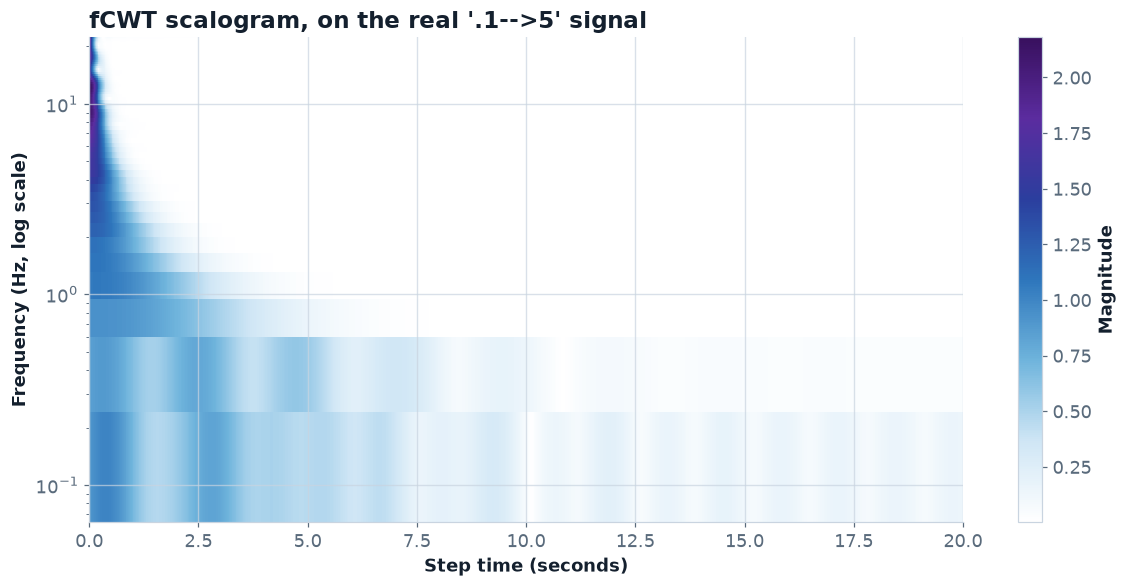

In [38]:
def run_fast_continuous_wavelet_transform(signal_values, sampling_frequency,
                                          minimum_frequency=None, maximum_frequency=None,
                                          number_of_frequencies=64):
    """
    Running the Fast Continuous Wavelet Transform using the fcwt library.

    fCWT computes a Morlet-based CWT using an FFT-optimised algorithm. The
    output is mathematically the same kind of thing PyWavelets' Morlet gave
    us in Cell 9, a full grid of frequency against time, just computed with
    a much faster underlying algorithm. This matters when this same analysis
    needs to run across dozens of experiments rather than just one.

    Returning the same dictionary shape used by every other method in this
    notebook, so it slots into the same comparison code without any special
    casing.
    """
    result = {"wavelet_name": "fCWT", "success": False, "message": ""}

    try:
        import fcwt

        signal_length = len(signal_values)

        if minimum_frequency is None:
            minimum_frequency = max(0.01, 4.0 * sampling_frequency / signal_length)
        if maximum_frequency is None:
            maximum_frequency = sampling_frequency / 2.2

        signal_as_float32 = np.asarray(signal_values, dtype=np.float32)

        frequency_axis, coefficient_matrix = fcwt.cwt(
            signal_as_float32, int(sampling_frequency),
            float(minimum_frequency), float(maximum_frequency), int(number_of_frequencies),
        )

        result["success"]      = True
        result["coefficients"] = coefficient_matrix
        result["magnitude"]    = np.abs(coefficient_matrix)
        result["frequencies"]  = np.asarray(frequency_axis).ravel()
        result["message"]      = "Computed successfully"

    except Exception as exception_message:
        result["message"] = "Failed: " + str(exception_message)

    return result


print("FUNCTION DEFINED")
print("=" * 78)
print("  run_fast_continuous_wavelet_transform(signal_values, sampling_frequency)")
print()

print("RUNNING fCWT ON THE SAME REAL SIGNAL")
print("=" * 78)

fcwt_result = run_fast_continuous_wavelet_transform(analysis_signal, analysis_frequency)

if fcwt_result["success"]:
    print("Status: OK")
    print("Output shape:", fcwt_result["magnitude"].shape)
    print("Message:", fcwt_result["message"])
else:
    print("Status: FAILED")
    print("Message:", fcwt_result["message"])
    print()
    print("If this failed with a message about 'libfftw3f', fcwt has a missing")
    print("system dependency, FFTW. On macOS, fix it with:")
    print("    brew install fftw")
    print("    python3 -m pip install --force-reinstall fcwt")
    print("Then restart the kernel and try this cell again.")
print()

print("SPEED COMPARISON: fCWT versus the regular CWT from Cell 9")
print("=" * 78)
print("This is fCWT's whole reason for existing, so let's actually measure it.")
print()

import time as timing_module

timing_start = timing_module.perf_counter()
_ = run_continuous_wavelet_transform(analysis_signal, analysis_frequency, "Morlet")
regular_cwt_time_ms = 1000.0 * (timing_module.perf_counter() - timing_start)

timing_start = timing_module.perf_counter()
_ = run_fast_continuous_wavelet_transform(analysis_signal, analysis_frequency)
fcwt_time_ms = 1000.0 * (timing_module.perf_counter() - timing_start)

print(f"Regular Morlet CWT (PyWavelets) : {regular_cwt_time_ms:8.2f} ms")
print(f"fCWT                            : {fcwt_time_ms:8.2f} ms")
if fcwt_time_ms > 0:
    print(f"fCWT is {regular_cwt_time_ms / fcwt_time_ms:.1f}x faster on this single signal")
print()
print("The speed gap grows much larger once we run this across 689 experiments")
print("later, rather than just once here.")


if fcwt_result["success"]:
    figure, axis = plt.subplots(figsize=(11, 5.5))
    magnitude = fcwt_result["magnitude"]
    frequencies = fcwt_result["frequencies"]
    valid_mask = (frequencies > 0) & np.isfinite(frequencies)
    magnitude = magnitude[valid_mask, :]
    frequencies = frequencies[valid_mask]
    sort_order = np.argsort(frequencies)

    mesh = axis.pcolormesh(
        np.linspace(analysis_time[0], analysis_time[-1], magnitude.shape[1]),
        frequencies[sort_order], magnitude[sort_order, :],
        shading="auto", cmap=SCALOGRAM_COLORMAP
    )
    axis.set_yscale("log")
    # fCWT returns linearly spaced frequencies, not logarithmically spaced like
    # PyWavelets' CWT. Matplotlib's automatic y-axis limits do not reliably
    # cover the real data range in that situation, so the limits are set
    # explicitly here rather than left to autoscale.
    axis.set_ylim(frequencies.min(), frequencies.max())
    axis.set_xlim(0, 20)
    axis.set_xlabel("Step time (seconds)")
    axis.set_ylabel("Frequency (Hz, log scale)")
    axis.set_title("fCWT scalogram, on the real '.1-->5' signal", loc="left")
    figure.colorbar(mesh, ax=axis, label="Magnitude")

    plt.tight_layout()
    plt.savefig("cell12_fcwt_scalogram.png", dpi=150, bbox_inches="tight")
    plt.show()

SCORING fCWT THE SAME WAY AS EVERY OTHER METHOD
fCWT   R squared = 0.8012   p-value = 0.00e+00

THE COMPLETE SCOREBOARD, ALL FOUR FAMILIES, ONE EXPERIMENT
Rank  Family  Best method     R squared
------------------------------------------------------------------------------
1     fCWT    fCWT            0.8012
2     STFT    STFT-Gaussian   0.3694
3     CWT     Morse           0.3635
4     DWT     db4             0.1620

OVERALL WINNER ON THIS SINGLE EXPERIMENT: fCWT
  R squared = 0.8012

IMPORTANT CAVEAT, same one as before
------------------------------------------------------------------------------
This is still just ONE experiment, scored with ONE simple feature. The
STFT result earlier already showed how close a single test can be. This
scoreboard is a preview, not a conclusion, the real answer comes from
Section 8, repeating this exact test across 53 experiments and 5 donors.


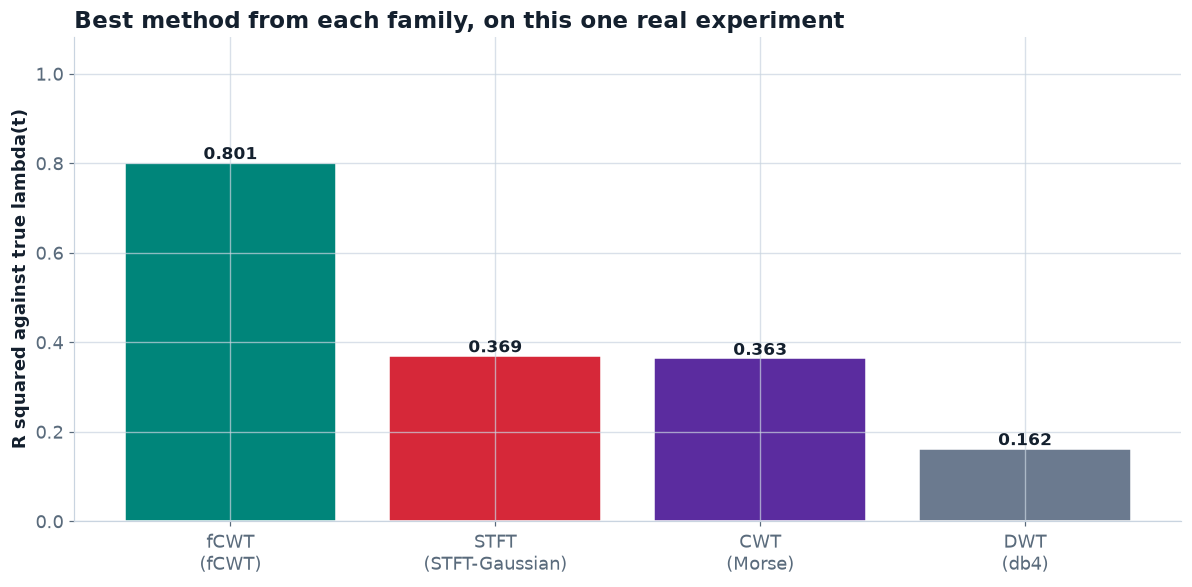

In [39]:
print("SCORING fCWT THE SAME WAY AS EVERY OTHER METHOD")
print("=" * 78)

fcwt_instantaneous_amplitude = compute_instantaneous_amplitude(fcwt_result["magnitude"])

valid_mask = np.isfinite(fcwt_instantaneous_amplitude) & np.isfinite(lambda_reference_signal)
fcwt_correlation_coefficient, fcwt_p_value = scipy_stats.pearsonr(
    fcwt_instantaneous_amplitude[valid_mask], lambda_reference_signal[valid_mask]
)
fcwt_r_squared = fcwt_correlation_coefficient ** 2

print(f"fCWT   R squared = {fcwt_r_squared:.4f}   p-value = {fcwt_p_value:.2e}")
print()

print("THE COMPLETE SCOREBOARD, ALL FOUR FAMILIES, ONE EXPERIMENT")
print("=" * 78)

final_scoreboard = pd.DataFrame([
    {"family": "CWT",  "best_method": comparison_table.iloc[0]["wavelet"],       "r_squared": comparison_table.iloc[0]["r_squared"]},
    {"family": "DWT",  "best_method": dwt_comparison_table.iloc[0]["wavelet"],   "r_squared": dwt_comparison_table.iloc[0]["r_squared"]},
    {"family": "STFT", "best_method": stft_comparison_table.iloc[0]["method"],   "r_squared": stft_comparison_table.iloc[0]["r_squared"]},
    {"family": "fCWT", "best_method": "fCWT",                                    "r_squared": fcwt_r_squared},
]).sort_values("r_squared", ascending=False).reset_index(drop=True)

print(f"{'Rank':<6}{'Family':<8}{'Best method':<16}{'R squared'}")
print("-" * 78)
for rank_position, row in final_scoreboard.iterrows():
    print(f"{rank_position+1:<6}{row['family']:<8}{row['best_method']:<16}{row['r_squared']:.4f}")

print()
overall_winner = final_scoreboard.iloc[0]
print(f"OVERALL WINNER ON THIS SINGLE EXPERIMENT: {overall_winner['best_method']}")
print(f"  R squared = {overall_winner['r_squared']:.4f}")
print()
print("IMPORTANT CAVEAT, same one as before")
print("-" * 78)
print("This is still just ONE experiment, scored with ONE simple feature. The")
print("STFT result earlier already showed how close a single test can be. This")
print("scoreboard is a preview, not a conclusion, the real answer comes from")
print("Section 8, repeating this exact test across 53 experiments and 5 donors.")


figure, axis = plt.subplots(figsize=(11, 5.5))
family_plot_colours = {"CWT": COLOUR_RUNNERUP, "DWT": COLOUR_NEUTRAL, "STFT": COLOUR_BASELINE, "fCWT": COLOUR_WINNER}
bar_colours = [family_plot_colours[fam] for fam in final_scoreboard["family"]]
bar_labels = [f"{row['family']}\n({row['best_method']})" for _, row in final_scoreboard.iterrows()]

bars = axis.bar(bar_labels, final_scoreboard["r_squared"], color=bar_colours, edgecolor="white")
for bar_object, value in zip(bars, final_scoreboard["r_squared"]):
    axis.text(bar_object.get_x() + bar_object.get_width() / 2, value + 0.008,
             f"{value:.3f}", ha="center", fontsize=11, fontweight="bold")
axis.set_ylabel("R squared against true lambda(t)")
axis.set_title("Best method from each family, on this one real experiment", loc="left")
axis.set_ylim(0, max(final_scoreboard["r_squared"]) * 1.35)

plt.tight_layout()
plt.savefig("cell12b_full_scoreboard.png", dpi=150, bbox_inches="tight")
plt.show()

#### Cell 13: Synchrosqueezed CWT (SSQ-CWT)

FUNCTION DEFINED
  run_synchrosqueezed_cwt(signal_values, sampling_frequency)

RUNNING SSQ-CWT ON THE SAME REAL SIGNAL
Status: OK
Output shape: (253, 3150)

SCORING SSQ-CWT THE SAME WAY AS EVERY OTHER METHOD
SSQ-CWT   R squared = 0.2253   p-value = 9.04e-177

UPDATED SCOREBOARD, INCLUDING SSQ-CWT
Rank  Family    Best method     R squared
------------------------------------------------------------------------------
1     fCWT      fCWT            0.8012
2     STFT      STFT-Gaussian   0.3694
3     CWT       Morse           0.3635
4     SSQ-CWT   SSQ-CWT         0.2253  <-- NEW
5     DWT       db4             0.1620

fCWT still leads, SSQ-CWT ranked #4.
As always, this is one experiment, one feature. Needs the full
cross-experiment validation before drawing real conclusions.


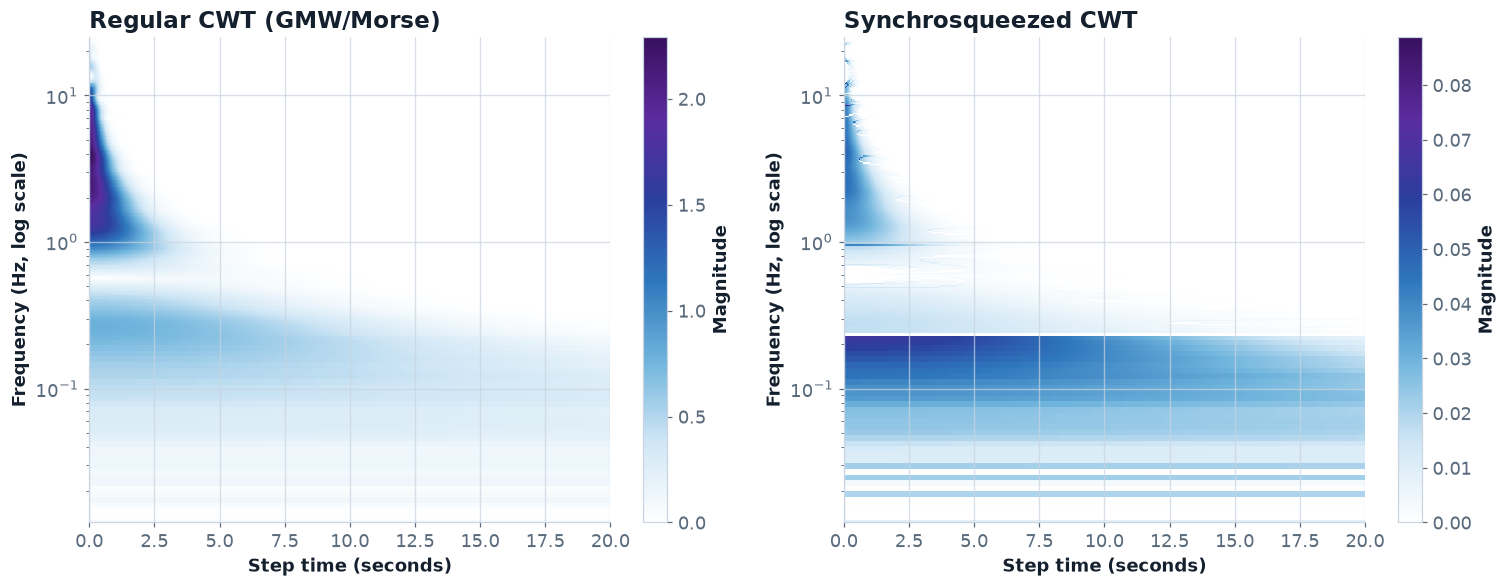

In [40]:
def run_synchrosqueezed_cwt(signal_values, sampling_frequency):
    """
    Running the Synchrosqueezed Continuous Wavelet Transform (SSQ-CWT).

    This is a new method not in the original 13, added after researching
    the published literature for anything that specifically outperforms
    a plain CWT at pinpointing a transient event. SSQ-CWT (Daubechies, Lu
    and Wu, 2011) takes the same CWT output we have been computing all
    along, then "reassigns" the energy at each point to a sharper, more
    accurate frequency estimate, using the CWT's own time-derivative to
    work out where the energy should really sit. The result is a much
    more tightly focused picture of the same information.

    Returning both the synchrosqueezed result and the regular CWT it was
    built from, in the same dictionary shape used by every other method
    in this notebook, so it plugs into the same comparison code.
    """
    result = {"wavelet_name": "SSQ-CWT", "success": False, "message": ""}

    try:
        import ssqueezepy

        signal_as_float64 = np.asarray(signal_values, dtype=np.float64)

        synchrosqueezed_coefficients, regular_cwt_coefficients, ssq_frequencies, *_ = ssqueezepy.ssq_cwt(
            signal_as_float64, wavelet="gmw", fs=sampling_frequency
        )

        result["success"]               = True
        result["coefficients"]          = synchrosqueezed_coefficients
        result["magnitude"]             = np.abs(synchrosqueezed_coefficients)
        result["frequencies"]           = np.asarray(ssq_frequencies).ravel()
        result["regular_cwt_magnitude"] = np.abs(regular_cwt_coefficients)
        result["message"]               = "Computed successfully"

    except Exception as exception_message:
        result["message"] = "Failed: " + str(exception_message)

    return result


print("FUNCTION DEFINED")
print("=" * 78)
print("  run_synchrosqueezed_cwt(signal_values, sampling_frequency)")
print()

print("RUNNING SSQ-CWT ON THE SAME REAL SIGNAL")
print("=" * 78)

ssq_result = run_synchrosqueezed_cwt(analysis_signal, analysis_frequency)

if ssq_result["success"]:
    print("Status: OK")
    print("Output shape:", ssq_result["magnitude"].shape)
else:
    print("Status: FAILED")
    print("Message:", ssq_result["message"])
print()

if ssq_result["success"]:
    print("SCORING SSQ-CWT THE SAME WAY AS EVERY OTHER METHOD")
    print("=" * 78)

    ssq_instantaneous_amplitude = compute_instantaneous_amplitude(ssq_result["magnitude"])

    valid_mask = np.isfinite(ssq_instantaneous_amplitude) & np.isfinite(lambda_reference_signal)
    ssq_correlation_coefficient, ssq_p_value = scipy_stats.pearsonr(
        ssq_instantaneous_amplitude[valid_mask], lambda_reference_signal[valid_mask]
    )
    ssq_r_squared = ssq_correlation_coefficient ** 2

    print(f"SSQ-CWT   R squared = {ssq_r_squared:.4f}   p-value = {ssq_p_value:.2e}")
    print()

    print("UPDATED SCOREBOARD, INCLUDING SSQ-CWT")
    print("=" * 78)

    updated_scoreboard = pd.concat([
        final_scoreboard,
        pd.DataFrame([{"family": "SSQ-CWT", "best_method": "SSQ-CWT", "r_squared": ssq_r_squared}])
    ], ignore_index=True).sort_values("r_squared", ascending=False).reset_index(drop=True)

    print(f"{'Rank':<6}{'Family':<10}{'Best method':<16}{'R squared'}")
    print("-" * 78)
    for rank_position, row in updated_scoreboard.iterrows():
        marker = "  <-- NEW" if row["family"] == "SSQ-CWT" else ""
        print(f"{rank_position+1:<6}{row['family']:<10}{row['best_method']:<16}{row['r_squared']:.4f}{marker}")

    print()
    if updated_scoreboard.iloc[0]["family"] == "SSQ-CWT":
        print("SSQ-CWT is now the overall leader on this experiment.")
    else:
        print(f"{updated_scoreboard.iloc[0]['family']} still leads, SSQ-CWT ranked",
              f"#{list(updated_scoreboard['family']).index('SSQ-CWT') + 1}.")
    print("As always, this is one experiment, one feature. Needs the full")
    print("cross-experiment validation before drawing real conclusions.")


    figure, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    for axis, (magnitude_key, panel_title) in zip(
        axes, [("regular_cwt_magnitude", "Regular CWT (GMW/Morse)"), ("magnitude", "Synchrosqueezed CWT")]
    ):
        magnitude = ssq_result[magnitude_key]
        frequencies = ssq_result["frequencies"]
        valid_mask = (frequencies > 0) & np.isfinite(frequencies)
        magnitude_plot = magnitude[valid_mask, :]
        frequencies_plot = frequencies[valid_mask]
        sort_order = np.argsort(frequencies_plot)

        mesh = axis.pcolormesh(
            np.linspace(analysis_time[0], analysis_time[-1], magnitude_plot.shape[1]),
            frequencies_plot[sort_order], magnitude_plot[sort_order, :],
            shading="auto", cmap=SCALOGRAM_COLORMAP
        )
        axis.set_yscale("log")
        axis.set_ylim(max(frequencies_plot.min(), 1e-2), frequencies_plot.max())
        axis.set_xlim(0, 20)
        axis.set_xlabel("Step time (seconds)")
        axis.set_ylabel("Frequency (Hz, log scale)")
        axis.set_title(panel_title, loc="left")
        figure.colorbar(mesh, ax=axis, label="Magnitude")

    plt.tight_layout()
    plt.savefig("cell13_ssqcwt_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()

#### Cell 14: PELT Changepoint Detection

FUNCTION DEFINED
  run_pelt_changepoint_detection(signal_values, sampling_frequency)

RUNNING PELT ON THE SAME REAL SIGNAL
Status: OK
Penalty value used       : 402.76
Number of segments found : 2
Changepoint times (s)    : [np.float64(0.701)]

TIMING ACCURACY, PELT'S NATURAL STRENGTH
Comparing PELT's detected changepoint against the same ground-truth
transition time used to score every other method, the moment lambda(t)
is changing fastest, taken from the physical model in Cell 6.

Ground-truth transition time : 0.121 s
PELT's closest changepoint   : 0.701 s
Timing error                 : 0.58 s

R SQUARED, FOR CONSISTENCY WITH THE REST OF THE SCOREBOARD
PELT was not designed to produce a smoothly varying signal the way
lambda(t) actually is, it produces flat segments with sudden jumps
between them. Scoring it on R squared is not really playing to its
strength, but it is computed anyway so it stays comparable to the
other methods on the same scoreboard.

PELT   R squared = 0.5508   p-

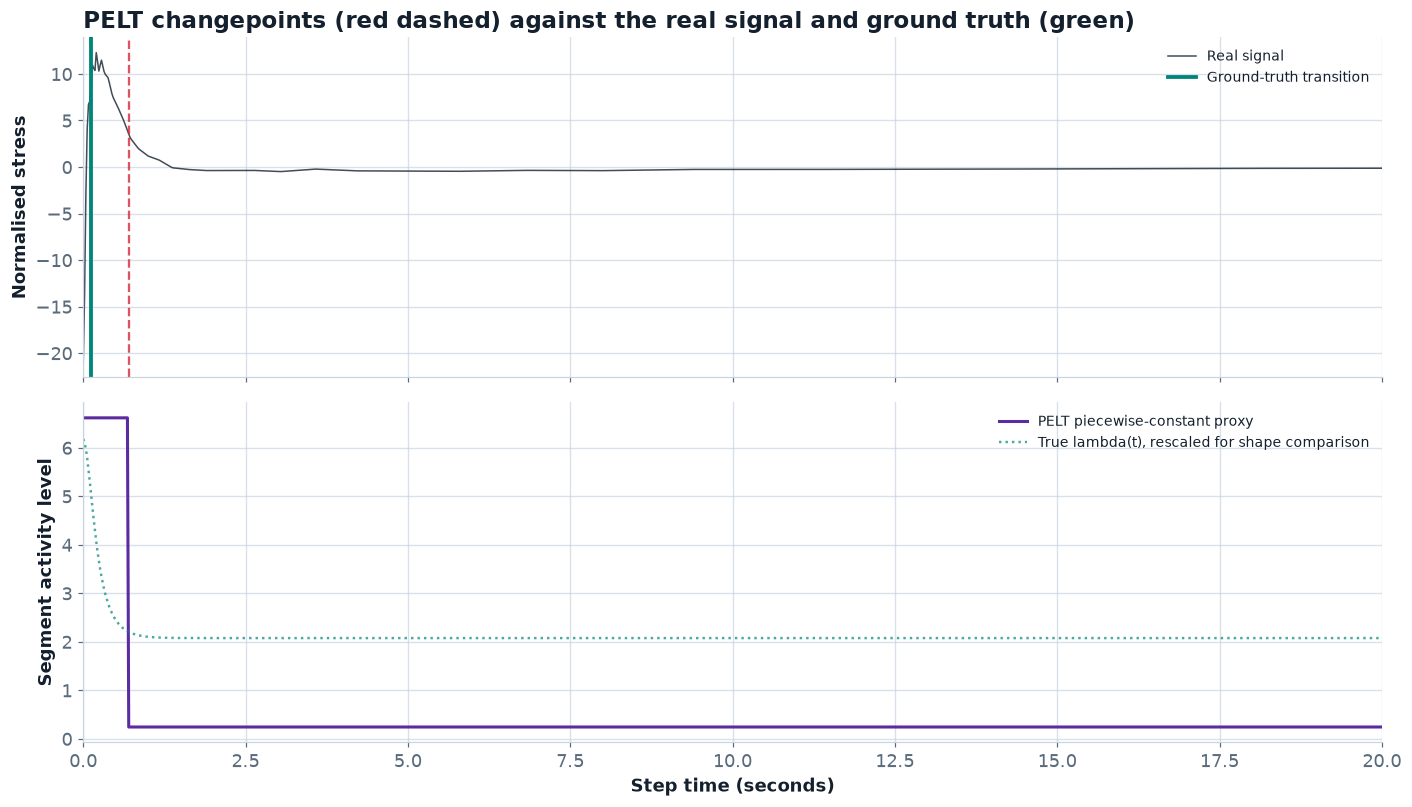

In [41]:
def run_pelt_changepoint_detection(signal_values, sampling_frequency, penalty_multiplier=50.0):
    """
    Running PELT (Pruned Exact Linear Time) changepoint detection.

    This is a genuinely different kind of method from everything else in
    this notebook. Every method so far, CWT, DWT, STFT, fCWT, SSQ-CWT, works
    by decomposing the signal into frequencies. PELT does not touch
    frequency at all. It is a statistics algorithm (Killick, Fearnhead and
    Eckley, 2012) that directly asks: where does the signal's underlying
    behaviour actually shift? It finds the exact, optimal set of
    breakpoints by minimising a cost function across all possible
    segmentations, using dynamic programming to do this in linear time
    rather than checking every possibility by brute force.

    The "l2" cost model looks for shifts in the mean level of the signal,
    and min_size/jump are speed controls, min_size stops it from proposing
    segments shorter than a sensible minimum, jump restricts which sample
    positions are even considered as candidate breakpoints. Both are
    standard practice for keeping PELT fast on longer signals.

    Returning both the detected changepoint locations, and a piecewise
    constant proxy signal built from the resulting segments, so that a
    comparable R squared score can still be computed against lambda(t),
    even though PELT itself was not designed to produce a continuous
    time-varying signal the way a time-frequency transform is.
    """
    result = {"method_name": "PELT", "success": False, "message": ""}

    try:
        import ruptures

        signal_variance = np.var(signal_values)
        penalty_value = penalty_multiplier * np.log(len(signal_values)) * signal_variance

        detection_algorithm = ruptures.Pelt(model="l2", min_size=10, jump=5).fit(signal_values)
        changepoint_indices = detection_algorithm.predict(pen=penalty_value)

        segment_boundaries = [0] + list(changepoint_indices)

        piecewise_proxy_signal = np.zeros_like(signal_values, dtype=float)
        for segment_index in range(len(segment_boundaries) - 1):
            segment_start = segment_boundaries[segment_index]
            segment_end   = segment_boundaries[segment_index + 1]
            segment_values = signal_values[segment_start:segment_end]
            segment_activity_level = np.std(segment_values)
            piecewise_proxy_signal[segment_start:segment_end] = segment_activity_level

        detected_changepoint_indices_excluding_end = [
            index for index in changepoint_indices if index < len(signal_values)
        ]

        result["success"]                = True
        result["changepoint_indices"]    = detected_changepoint_indices_excluding_end
        result["number_of_segments"]     = len(segment_boundaries) - 1
        result["piecewise_proxy_signal"] = piecewise_proxy_signal
        result["penalty_used"]           = penalty_value
        result["message"]                = "Computed successfully"

    except Exception as exception_message:
        result["message"] = "Failed: " + str(exception_message)

    return result


print("FUNCTION DEFINED")
print("=" * 78)
print("  run_pelt_changepoint_detection(signal_values, sampling_frequency)")
print()

print("RUNNING PELT ON THE SAME REAL SIGNAL")
print("=" * 78)

pelt_result = run_pelt_changepoint_detection(analysis_signal, analysis_frequency)

if pelt_result["success"]:
    print("Status: OK")
    print("Penalty value used       :", round(pelt_result["penalty_used"], 2))
    print("Number of segments found :", pelt_result["number_of_segments"])

    detected_changepoint_times = [analysis_time[index] for index in pelt_result["changepoint_indices"]]
    print("Changepoint times (s)    :", [round(t, 3) for t in detected_changepoint_times])
    print()

    print("TIMING ACCURACY, PELT'S NATURAL STRENGTH")
    print("=" * 78)
    print("Comparing PELT's detected changepoint against the same ground-truth")
    print("transition time used to score every other method, the moment lambda(t)")
    print("is changing fastest, taken from the physical model in Cell 6.")
    print()

    lambda_rate_of_change = np.gradient(lambda_reference_signal, analysis_time)
    ground_truth_transition_time = analysis_time[int(np.argmax(np.abs(lambda_rate_of_change)))]
    print("Ground-truth transition time :", round(float(ground_truth_transition_time), 4), "s")

    if len(detected_changepoint_times) > 0:
        closest_changepoint_time = min(detected_changepoint_times, key=lambda t: abs(t - ground_truth_transition_time))
        timing_error_seconds = abs(closest_changepoint_time - ground_truth_transition_time)
        print("PELT's closest changepoint   :", round(float(closest_changepoint_time), 4), "s")
        print("Timing error                 :", round(float(timing_error_seconds), 4), "s")
    print()

    print("R SQUARED, FOR CONSISTENCY WITH THE REST OF THE SCOREBOARD")
    print("=" * 78)
    print("PELT was not designed to produce a smoothly varying signal the way")
    print("lambda(t) actually is, it produces flat segments with sudden jumps")
    print("between them. Scoring it on R squared is not really playing to its")
    print("strength, but it is computed anyway so it stays comparable to the")
    print("other methods on the same scoreboard.")
    print()

    valid_mask = np.isfinite(pelt_result["piecewise_proxy_signal"]) & np.isfinite(lambda_reference_signal)
    pelt_correlation_coefficient, pelt_p_value = scipy_stats.pearsonr(
        pelt_result["piecewise_proxy_signal"][valid_mask], lambda_reference_signal[valid_mask]
    )
    pelt_r_squared = pelt_correlation_coefficient ** 2
    print(f"PELT   R squared = {pelt_r_squared:.4f}   p-value = {pelt_p_value:.2e}")

else:
    print("Status: FAILED")
    print("Message:", pelt_result["message"])


figure, (axis_top, axis_bottom) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)

axis_top.plot(analysis_time, analysis_signal, color=COLOUR_TEXT, linewidth=1.0, alpha=0.8, label="Real signal")
for changepoint_time in detected_changepoint_times:
    axis_top.axvline(changepoint_time, color=COLOUR_BASELINE, linestyle="--", linewidth=1.5, alpha=0.8)
axis_top.axvline(ground_truth_transition_time, color=COLOUR_WINNER, linewidth=2.5,
                 label="Ground-truth transition")
axis_top.set_ylabel("Normalised stress")
axis_top.set_title("PELT changepoints (red dashed) against the real signal and ground truth (green)", loc="left")
axis_top.set_xlim(0, 20)
axis_top.legend(fontsize=9, loc="upper right")

axis_bottom.plot(analysis_time, pelt_result["piecewise_proxy_signal"], color=COLOUR_RUNNERUP,
                 linewidth=2.0, label="PELT piecewise-constant proxy")
axis_bottom.plot(analysis_time, lambda_reference_signal * np.max(pelt_result["piecewise_proxy_signal"]),
                 color=COLOUR_WINNER, linewidth=1.6, linestyle=":", alpha=0.7,
                 label="True lambda(t), rescaled for shape comparison")
axis_bottom.set_xlabel("Step time (seconds)")
axis_bottom.set_ylabel("Segment activity level")
axis_bottom.set_xlim(0, 20)
axis_bottom.legend(fontsize=9, loc="upper right")

plt.tight_layout()
plt.savefig("cell14_pelt_changepoints.png", dpi=150, bbox_inches="tight")
plt.show()

#### Cell 15: Master Feature Extraction and Timing Metric, All 15 Methods

FUNCTIONS DEFINED
  extract_unified_feature(...)    one shared feature extractor for all 15 methods
  compute_timing_accuracy(...)    locates fastest change, compares to ground truth

BUILDING THE MASTER RESULTS TABLE ACROSS ALL 15 METHODS
Note: the last 5 percent of each recording is excluded from the timing-
accuracy search, to guard against FFT edge-wraparound artifacts (caught
during testing, our custom Paul wavelet was flagging a numerical artifact
at the very end of the recording as a false 'transition'). Only a tiny
guard is kept at the start, since the real transition happens early and a
large front-exclusion would cut it out along with any artifact.

Rank  Family    Method        R sq     Timing err (s)  Status
------------------------------------------------------------------------------
1     fCWT      fCWT          0.8012   0.1800          ok
2     PELT      PELT          0.5508   0.5600          ok
3     STFT      Gaussian      0.3694   0.7400          ok
4     CWT       M

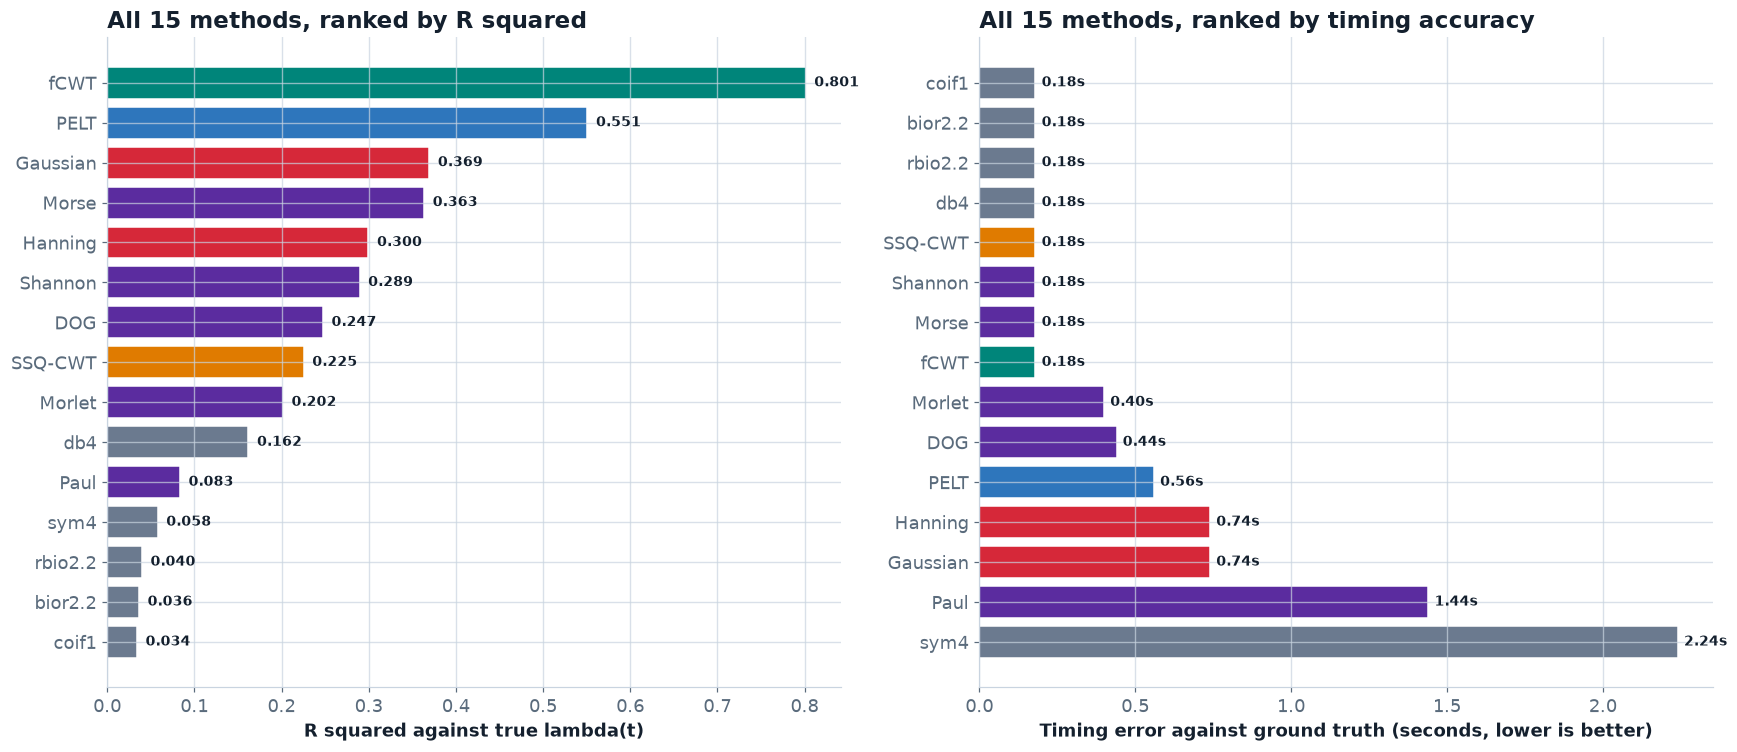

In [42]:
def extract_unified_feature(method_name, result_dictionary, reference_length, reference_time):
    """
    Pulling one comparable 1D "how much is happening right now" signal out
    of any of the 15 methods, no matter how differently shaped their raw
    output is.

    This is the single place in the notebook that knows about every
    method's particular output format, CWT, fCWT and SSQ-CWT give a 2D
    magnitude grid, DWT gives several detail-coefficient arrays of
    different lengths, STFT gives a 2D grid on a coarser time axis, and
    PELT already produces a 1D piecewise signal directly. Every metric
    computed afterwards works from this one unified feature, so nothing
    downstream needs to know these differences exist.

    Returning None if the method is unrecognised or its result was not
    successful, so calling code can skip it safely.
    """
    if not result_dictionary.get("success", False):
        return None

    if method_name in ("Morlet", "Paul", "DOG", "Shannon", "Morse", "fCWT", "SSQ-CWT"):
        magnitude_matrix = result_dictionary["magnitude"]
        feature = compute_instantaneous_amplitude(magnitude_matrix)
        source_time = np.linspace(reference_time[0], reference_time[-1], len(feature))

    elif method_name in ("db4", "sym4", "coif1", "bior2.2", "rbio2.2"):
        feature = compute_dwt_instantaneous_amplitude(result_dictionary, reference_length)
        source_time = reference_time

    elif method_name in ("Hanning", "Gaussian"):
        feature = compute_stft_instantaneous_amplitude(result_dictionary, reference_length, reference_time)
        source_time = reference_time

    elif method_name == "PELT":
        feature = result_dictionary["piecewise_proxy_signal"]
        source_time = reference_time

    else:
        return None

    if len(feature) != reference_length:
        upsampling_function = interp1d(
            np.linspace(0, 1, len(feature)), feature, kind="linear",
            bounds_error=False, fill_value=(feature[0], feature[-1])
        )
        feature = upsampling_function(np.linspace(0, 1, reference_length))

    return feature


def compute_timing_accuracy(feature_values, reference_time, ground_truth_time,
                            start_exclusion_fraction=0.005, end_exclusion_fraction=0.05):
    """
    Locating the moment a feature changes fastest, and comparing it to the
    known ground-truth transition time.

    A short smoothing pass is applied first, since raw sample-to-sample
    differences are noisy and would otherwise make the "fastest change"
    point unreliable.

    The very end of the recording is excluded from the search, guarding
    against FFT edge-wraparound artifacts (our custom Paul wavelet showed
    this clearly during testing, an artificial upward drift right at the
    last few samples, unrelated to anything physically happening there).

    The exclusion is deliberately ASYMMETRIC. An earlier version of this
    function excluded 5 percent from both the start and the end, which
    seemed like the safer, more symmetric choice, but that was a mistake:
    with the real transition sitting at roughly t=0.12s, a 5 percent
    front-exclusion on a 63 second recording covers over 3 seconds and
    swallows the genuine transition along with any artifact. Only a small
    guard is kept at the start, just enough to avoid the very first sample,
    while the larger guard stays at the end where the actual artifact was.
    """
    window_length = max(3, min(11, len(feature_values) // 20))
    if window_length % 2 == 0:
        window_length += 1

    if len(feature_values) > window_length:
        smoothed_feature = scipy_signal.savgol_filter(feature_values, window_length, polyorder=2)
    else:
        smoothed_feature = feature_values

    feature_gradient = np.gradient(smoothed_feature, reference_time)

    start_exclusion_count = max(1, int(len(feature_gradient) * start_exclusion_fraction))
    end_exclusion_count   = max(1, int(len(feature_gradient) * end_exclusion_fraction))

    searchable_gradient = feature_gradient.copy()
    searchable_gradient[:start_exclusion_count] = 0.0
    searchable_gradient[-end_exclusion_count:] = 0.0

    detected_index = int(np.argmax(np.abs(searchable_gradient)))
    detected_time = float(reference_time[detected_index])

    return detected_time, abs(detected_time - ground_truth_time)


print("FUNCTIONS DEFINED")
print("=" * 78)
print("  extract_unified_feature(...)    one shared feature extractor for all 15 methods")
print("  compute_timing_accuracy(...)    locates fastest change, compares to ground truth")
print()

print("BUILDING THE MASTER RESULTS TABLE ACROSS ALL 15 METHODS")
print("=" * 78)
print("Note: the last 5 percent of each recording is excluded from the timing-")
print("accuracy search, to guard against FFT edge-wraparound artifacts (caught")
print("during testing, our custom Paul wavelet was flagging a numerical artifact")
print("at the very end of the recording as a false 'transition'). Only a tiny")
print("guard is kept at the start, since the real transition happens early and a")
print("large front-exclusion would cut it out along with any artifact.")
print()

all_method_results = {}
for wavelet_name in cwt_wavelet_names:
    all_method_results[wavelet_name] = ("CWT", cwt_results[wavelet_name])
for wavelet_name in dwt_wavelet_names:
    all_method_results[wavelet_name] = ("DWT", dwt_results[wavelet_name])
for window_name in stft_window_names:
    all_method_results[window_name] = ("STFT", stft_results[window_name])
all_method_results["fCWT"]    = ("fCWT", fcwt_result)
all_method_results["SSQ-CWT"] = ("SSQ-CWT", ssq_result)
all_method_results["PELT"]    = ("PELT", pelt_result)

lambda_rate_of_change = np.gradient(lambda_reference_signal, analysis_time)
ground_truth_transition_time = analysis_time[int(np.argmax(np.abs(lambda_rate_of_change)))]

master_results = []

for method_name, (family_name, result_dictionary) in all_method_results.items():
    unified_feature = extract_unified_feature(method_name, result_dictionary, len(analysis_time), analysis_time)

    if unified_feature is None:
        master_results.append({
            "family": family_name, "method": method_name,
            "r_squared": np.nan, "p_value": np.nan,
            "detected_time_s": np.nan, "timing_error_s": np.nan,
            "status": "unavailable",
        })
        continue

    valid_mask = np.isfinite(unified_feature) & np.isfinite(lambda_reference_signal)
    correlation_coefficient, p_value = scipy_stats.pearsonr(
        unified_feature[valid_mask], lambda_reference_signal[valid_mask]
    )
    r_squared_value = correlation_coefficient ** 2

    detected_time, timing_error = compute_timing_accuracy(
        unified_feature, analysis_time, ground_truth_transition_time
    )

    master_results.append({
        "family": family_name, "method": method_name,
        "r_squared": r_squared_value, "p_value": p_value,
        "detected_time_s": detected_time, "timing_error_s": timing_error,
        "status": "ok",
    })

master_table = pd.DataFrame(master_results).sort_values("r_squared", ascending=False).reset_index(drop=True)

print(f"{'Rank':<6}{'Family':<10}{'Method':<14}{'R sq':<9}{'Timing err (s)':<16}{'Status'}")
print("-" * 78)
for rank_position, row in master_table.iterrows():
    if row["status"] == "ok":
        print(f"{rank_position+1:<6}{row['family']:<10}{row['method']:<14}{row['r_squared']:<9.4f}{row['timing_error_s']:<16.4f}{row['status']}")
    else:
        print(f"{'-':<6}{row['family']:<10}{row['method']:<14}{'-':<9}{'-':<16}{row['status']}")

print()
print("Ground-truth transition time used for all timing comparisons:", round(float(ground_truth_transition_time), 4), "s")
print()
successful_count = (master_table["status"] == "ok").sum()
print(f"{successful_count} of {len(master_table)} methods scored successfully on both metrics.")


figure, (axis_left, axis_right) = plt.subplots(1, 2, figsize=(16, 7))

plot_table = master_table[master_table["status"] == "ok"].sort_values("r_squared", ascending=True)
family_plot_colours = {
    "CWT": COLOUR_RUNNERUP, "DWT": COLOUR_NEUTRAL, "STFT": COLOUR_BASELINE,
    "fCWT": COLOUR_WINNER, "SSQ-CWT": COLOUR_ACCENT, "PELT": "#2E76BC",
}
bar_colours = [family_plot_colours.get(fam, COLOUR_NEUTRAL) for fam in plot_table["family"]]

axis_left.barh(plot_table["method"], plot_table["r_squared"], color=bar_colours, edgecolor="white")
for index, (method, value) in enumerate(zip(plot_table["method"], plot_table["r_squared"])):
    axis_left.text(value + 0.01, index, f"{value:.3f}", va="center", fontsize=9, fontweight="bold")
axis_left.set_xlabel("R squared against true lambda(t)")
axis_left.set_title("All 15 methods, ranked by R squared", loc="left")

plot_table_timing = master_table[master_table["status"] == "ok"].sort_values("timing_error_s", ascending=False)
bar_colours_timing = [family_plot_colours.get(fam, COLOUR_NEUTRAL) for fam in plot_table_timing["family"]]
axis_right.barh(plot_table_timing["method"], plot_table_timing["timing_error_s"], color=bar_colours_timing, edgecolor="white")
for index, (method, value) in enumerate(zip(plot_table_timing["method"], plot_table_timing["timing_error_s"])):
    axis_right.text(value + 0.02, index, f"{value:.2f}s", va="center", fontsize=9, fontweight="bold")
axis_right.set_xlabel("Timing error against ground truth (seconds, lower is better)")
axis_right.set_title("All 15 methods, ranked by timing accuracy", loc="left")

plt.tight_layout()
plt.savefig("cell15_master_table.png", dpi=150, bbox_inches="tight")
plt.show()

#### Cell 16: Interactive Method Explorer

In [43]:
def get_scalogram_data(method_name):
    """
    Building a (z, x, y) heatmap grid for whichever method is selected,
    regardless of how differently shaped its raw stored output is.

    CWT, fCWT and SSQ-CWT already have a ready-made 2D magnitude grid.
    DWT does not, so its detail levels are stacked into an equivalent
    coarse grid, the same trick used back in the DWT ranking cell. STFT
    has its own native, coarser time axis. PELT has no frequency axis at
    all, so it returns None, and the explorer falls back to showing just
    its segments in the bottom panel instead of a heatmap on top.
    """
    family_name, result_dictionary = all_method_results[method_name]

    if not result_dictionary.get("success", False):
        return None

    if method_name in ("Morlet", "Paul", "DOG", "Shannon", "Morse", "fCWT", "SSQ-CWT"):
        magnitude = result_dictionary["magnitude"]
        frequencies = result_dictionary["frequencies"]
        valid_mask = (frequencies > 0) & np.isfinite(frequencies)
        magnitude = magnitude[valid_mask, :]
        frequencies = frequencies[valid_mask]
        sort_order = np.argsort(frequencies)
        z = magnitude[sort_order, :]
        y = frequencies[sort_order]
        x = np.linspace(analysis_time[0], analysis_time[-1], z.shape[1])
        return z, x, y

    if method_name in ("db4", "sym4", "coif1", "bior2.2", "rbio2.2"):
        detail_rows = []
        band_centres = []
        for level_index, detail_coefficients in enumerate(result_dictionary["detail_coefficients"]):
            original_positions = np.linspace(0, 1, len(detail_coefficients))
            target_positions = np.linspace(0, 1, len(analysis_time))
            upsampling_function = interp1d(original_positions, np.abs(detail_coefficients), kind="linear")
            detail_rows.append(upsampling_function(target_positions))
            band = result_dictionary["band_information"][result_dictionary["decomposition_level"] - 1 - level_index]
            band_centres.append(0.5 * (band["lower_hz"] + band["upper_hz"]))
        z = np.array(detail_rows)
        y = np.array(band_centres)
        x = analysis_time
        return z, x, y

    if method_name in ("Hanning", "Gaussian"):
        z = result_dictionary["magnitude"]
        y = result_dictionary["frequencies"]
        x = result_dictionary["time_axis"]
        return z, x, y

    return None


def build_interactive_method_explorer():
    """
    Building a dropdown-driven explorer across all 15 methods.

    Selecting a method rebuilds two panels: the top shows that method's own
    time-frequency picture (or its segments, for PELT, which has no
    frequency axis), the bottom shows the single unified feature extracted
    from it, plotted directly against the real lambda(t), with the R
    squared and timing accuracy numbers for that specific method printed
    alongside it.
    """
    method_dropdown = widgets.Dropdown(
        options=list(all_method_results.keys()),
        value="fCWT",
        description="Method:",
        style={"description_width": "80px"},
        layout=widgets.Layout(width="300px"),
    )

    figure_widget = go.FigureWidget(
        make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.1,
                     row_heights=[0.55, 0.45],
                     subplot_titles=("Time-frequency picture", "Extracted feature vs true lambda(t)"))
    )
    figure_widget.add_heatmap(z=[[0]], x=[0], y=[0], colorscale="Blues", showscale=True, row=1, col=1)
    figure_widget.add_scatter(x=[], y=[], mode="lines", name="Extracted feature",
                              line=dict(color=COLOUR_RUNNERUP, width=2.5), row=2, col=1)
    figure_widget.add_scatter(x=[], y=[], mode="lines", name="True lambda(t), rescaled",
                              line=dict(color=COLOUR_WINNER, width=2, dash="dot"), row=2, col=1)
    figure_widget.update_layout(height=620, template="plotly_white", showlegend=True,
                                margin=dict(l=60, r=30, t=60, b=50))
    figure_widget.update_xaxes(title_text="Step time (seconds)", row=2, col=1)
    figure_widget.update_yaxes(title_text="Frequency (Hz)", row=1, col=1)
    figure_widget.update_yaxes(title_text="Feature value (normalised)", row=2, col=1)

    info_label = widgets.HTML()

    def redraw_for_selected_method(change=None):
        method_name = method_dropdown.value
        family_name, result_dictionary = all_method_results[method_name]

        scalogram_data = get_scalogram_data(method_name)

        with figure_widget.batch_update():
            if scalogram_data is not None:
                z, x, y = scalogram_data
                figure_widget.data[0].z = z
                figure_widget.data[0].x = x
                figure_widget.data[0].y = y
                figure_widget.layout.yaxis.type = "log" if method_name != "PELT" else "linear"
            else:
                figure_widget.data[0].z = [[0, 0], [0, 0]]
                figure_widget.data[0].x = [analysis_time[0], analysis_time[-1]]
                figure_widget.data[0].y = [0, 1]

            unified_feature = extract_unified_feature(method_name, result_dictionary, len(analysis_time), analysis_time)
            if unified_feature is not None:
                feature_range = np.ptp(unified_feature)
                normalised_feature = (unified_feature - unified_feature.min()) / feature_range if feature_range > 0 else unified_feature
                lambda_range = np.ptp(lambda_reference_signal)
                normalised_lambda = (lambda_reference_signal - lambda_reference_signal.min()) / lambda_range if lambda_range > 0 else lambda_reference_signal

                figure_widget.data[1].x = analysis_time
                figure_widget.data[1].y = normalised_feature
                figure_widget.data[2].x = analysis_time
                figure_widget.data[2].y = normalised_lambda

                row = master_table[master_table["method"] == method_name].iloc[0]
                info_label.value = (
                    f"<b>{method_name}</b> ({family_name} family) &nbsp;|&nbsp; "
                    f"R squared = <b>{row['r_squared']:.4f}</b> &nbsp;|&nbsp; "
                    f"Timing error = <b>{row['timing_error_s']:.3f} s</b>"
                )
            else:
                figure_widget.data[1].x = []
                figure_widget.data[1].y = []
                figure_widget.data[2].x = []
                figure_widget.data[2].y = []
                info_label.value = f"<b>{method_name}</b>: feature unavailable"

    method_dropdown.observe(redraw_for_selected_method, names="value")
    redraw_for_selected_method()

    return widgets.VBox([method_dropdown, info_label, figure_widget])


method_explorer_widget = build_interactive_method_explorer()
print("Explorer built. Run 'display(method_explorer_widget)' in the next cell to show it.")

Explorer built. Run 'display(method_explorer_widget)' in the next cell to show it.


In [44]:
display(method_explorer_widget)

#### Cell 17: The Reusable Full Pipeline Function

In [45]:
def run_full_pipeline_on_experiment(time_values, stress_values,
                                    initial_shear_rate, final_shear_rate,
                                    source_file, condition_label,
                                    sampling_frequency_hz=RESAMPLE_FREQUENCY_HZ):
    """
    Running the entire notebook's pipeline, start to finish, on one single
    experiment: preprocessing, a fresh local physics ground truth built
    specifically for this experiment's own shear-rate step, all 15
    time-frequency and changepoint methods, and the full scoring against
    that local ground truth.

    This is every function built across Cells 4 through 16, called in
    sequence, wrapped into one reusable step. Running this same function
    once per experiment is what turns "one experiment, 15 methods" into
    "53 experiments, 5 donors, 15 methods", the real cross-validation.

    A fresh lambda(t) is simulated for every experiment individually,
    using that experiment's own initial and final shear rate, rather than
    reusing the primary experiment's ground truth, since the correct
    transition time is different for every different shear-rate step.

    Returning a list of result dictionaries, one row per method, or an
    empty list if this experiment could not be processed (too short,
    missing columns, and so on), so the calling loop can skip it safely.
    """
    preprocessing_result = preprocess_signal(time_values, stress_values, sampling_frequency_hz)
    if preprocessing_result is None:
        return []

    local_signal = preprocessing_result["processed_stress"]
    local_time   = preprocessing_result["processed_time"]

    if len(local_signal) < 64:
        return []

    def local_shear_rate_history(current_time):
        if current_time < 0.0:
            return initial_shear_rate
        return final_shear_rate

    try:
        local_model_time, local_model_stress, local_model_lambda = simulate_ethixo_evp(
            local_shear_rate_history, (0.0, float(local_time[-1])),
            PAPER_PARAMETERS_DONOR3, initial_shear_rate, model_version=1,
            number_of_output_points=min(2000, len(local_time)),
        )
    except Exception:
        return []

    lambda_interpolation_function = interp1d(
        local_model_time, local_model_lambda, kind="linear",
        bounds_error=False, fill_value=(local_model_lambda[0], local_model_lambda[-1]),
    )
    local_lambda_reference = lambda_interpolation_function(local_time)

    local_lambda_rate_of_change = np.gradient(local_lambda_reference, local_time)
    local_ground_truth_time = local_time[int(np.argmax(np.abs(local_lambda_rate_of_change)))]

    local_method_results = {}

    for wavelet_name in cwt_wavelet_names:
        local_method_results[wavelet_name] = ("CWT", run_continuous_wavelet_transform(
            local_signal, sampling_frequency_hz, wavelet_name))

    for wavelet_name in dwt_wavelet_names:
        local_method_results[wavelet_name] = ("DWT", run_discrete_wavelet_transform(
            local_signal, sampling_frequency_hz, wavelet_name))

    for window_name in stft_window_names:
        local_method_results[window_name] = ("STFT", run_short_time_fourier_transform(
            local_signal, sampling_frequency_hz, window_name))

    local_method_results["fCWT"]    = ("fCWT",    run_fast_continuous_wavelet_transform(local_signal, sampling_frequency_hz))
    local_method_results["SSQ-CWT"] = ("SSQ-CWT", run_synchrosqueezed_cwt(local_signal, sampling_frequency_hz))
    local_method_results["PELT"]    = ("PELT",    run_pelt_changepoint_detection(local_signal, sampling_frequency_hz))

    experiment_rows = []

    for method_name, (family_name, result_dictionary) in local_method_results.items():
        unified_feature = extract_unified_feature(method_name, result_dictionary, len(local_time), local_time)
        if unified_feature is None:
            continue

        valid_mask = np.isfinite(unified_feature) & np.isfinite(local_lambda_reference)
        if valid_mask.sum() < 10:
            continue

        try:
            correlation_coefficient, p_value = scipy_stats.pearsonr(
                unified_feature[valid_mask], local_lambda_reference[valid_mask]
            )
        except Exception:
            continue

        r_squared_value = correlation_coefficient ** 2
        detected_time, timing_error = compute_timing_accuracy(
            unified_feature, local_time, local_ground_truth_time
        )

        experiment_rows.append({
            "source_file":      source_file,
            "condition_label":  condition_label,
            "initial_shear_rate": initial_shear_rate,
            "final_shear_rate":   final_shear_rate,
            "family":           family_name,
            "method":           method_name,
            "r_squared":        r_squared_value,
            "p_value":          p_value,
            "timing_error_s":   timing_error,
        })

    return experiment_rows


print("FUNCTION DEFINED")
print("=" * 78)
print("  run_full_pipeline_on_experiment(...)")
print()

print("CONSISTENCY CHECK: running it on the SAME primary experiment we have")
print("already scored by hand, to confirm this wrapped-up version reproduces")
print("the same numbers before trusting it to run on all 53 experiments.")
print("=" * 78)

consistency_check_rows = run_full_pipeline_on_experiment(
    primary_raw_time, primary_raw_stress,
    PRIMARY_INITIAL_SHEAR_RATE, PRIMARY_FINAL_SHEAR_RATE,
    source_file=PRIMARY_DATA_FILE, condition_label=".1-->5(1/s)",
)

consistency_check_table = pd.DataFrame(consistency_check_rows).sort_values("r_squared", ascending=False)

print(f"{'Method':<12}{'New R sq':<12}{'Original R sq':<16}{'Match?'}")
print("-" * 78)
all_matched = True
for _, row in consistency_check_table.iterrows():
    original_row = master_table[master_table["method"] == row["method"]]
    if len(original_row) == 0:
        continue
    original_r_squared = original_row.iloc[0]["r_squared"]
    matches = abs(row["r_squared"] - original_r_squared) < 0.01
    if not matches:
        all_matched = False
    match_text = "yes" if matches else "MISMATCH"
    print(f"{row['method']:<12}{row['r_squared']:<12.4f}{original_r_squared:<16.4f}{match_text}")

print()
if all_matched:
    print("All methods matched their original scores. The wrapped pipeline")
    print("function is behaving identically to the hand-built version.")
else:
    print("Some methods did not match, investigate before running on all 53.")

FUNCTION DEFINED
  run_full_pipeline_on_experiment(...)

CONSISTENCY CHECK: running it on the SAME primary experiment we have
already scored by hand, to confirm this wrapped-up version reproduces
the same numbers before trusting it to run on all 53 experiments.
Method      New R sq    Original R sq   Match?
------------------------------------------------------------------------------
fCWT        0.8012      0.8012          yes
PELT        0.5508      0.5508          yes
Gaussian    0.3694      0.3694          yes
Morse       0.3635      0.3635          yes
Hanning     0.2996      0.2996          yes
Shannon     0.2894      0.2894          yes
DOG         0.2474      0.2474          yes
SSQ-CWT     0.2253      0.2253          yes
Morlet      0.2015      0.2015          yes
db4         0.1620      0.1620          yes
Paul        0.0834      0.0834          yes
sym4        0.0578      0.0578          yes
rbio2.2     0.0397      0.0397          yes
bior2.2     0.0364      0.0364          

#### Cell 18: Full Cross-Experiment Validation, All 53 Experiments, 5 Donors

FUNCTIONS DEFINED
  parse_step_condition(condition_label)
  find_step_up_sheet_names(workbook_handle)

RUNNING THE FULL CROSS-EXPERIMENT VALIDATION
Workbooks to search: ['data8.xlsx', 'data5.xlsx', 'data9.xlsx', 'data7.xlsx', 'data1.xlsx']
This runs all 15 methods on every step-up test found, so it takes a
few minutes. Progress is printed after each workbook.

  data8.xlsx     9 step-up experiments processed   (running total: 9, elapsed 16s)
  data5.xlsx     9 step-up experiments processed   (running total: 18, elapsed 31s)
  data9.xlsx     27 step-up experiments processed   (running total: 45, elapsed 74s)
  data7.xlsx     5 step-up experiments processed   (running total: 50, elapsed 83s)
  data1.xlsx     3 step-up experiments processed   (running total: 53, elapsed 88s)

CROSS-VALIDATION COMPLETE
Total runtime                       : 88.2 seconds
Total method-experiment evaluations : 795
Distinct experiments covered        : 53
Distinct workbooks covered          : 5
Expected evaluat

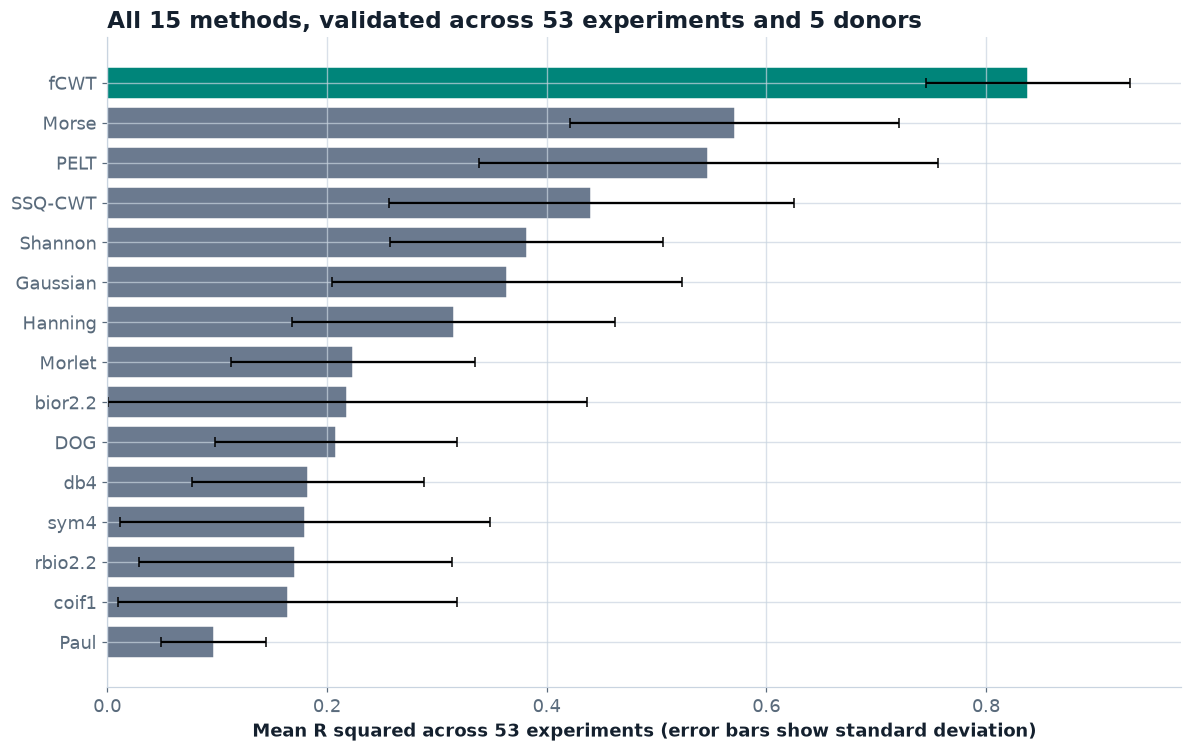


Full results saved to cross_experiment_validation.csv


In [46]:
def parse_step_condition(condition_label):
    """
    Parsing a condition label such as '.1-->5(1/s)' into its initial and
    final shear rates, and whether it represents a step UP (rate
    increasing) rather than a step down.

    Returning (initial_rate, final_rate, is_step_up). is_step_up is None
    when the label cannot be parsed at all, so callers can tell "not a
    step test" apart from "a step-down test we're deliberately skipping".
    """
    cleaned_label = str(condition_label).replace("(1/s)", "").replace(" ", "")

    if "-->" not in cleaned_label:
        return np.nan, np.nan, None

    label_parts = cleaned_label.split("-->")
    if len(label_parts) != 2:
        return np.nan, np.nan, None

    try:
        initial_rate = float(label_parts[0])
        final_rate   = float(label_parts[1])
    except ValueError:
        return np.nan, np.nan, None

    return initial_rate, final_rate, (final_rate > initial_rate)


def find_step_up_sheet_names(workbook_handle):
    """
    Finding every sheet in a workbook whose name suggests it holds step
    tests, without assuming the exact sheet name used by data8.xlsx is
    used identically in every other workbook. This matters in practice,
    data1.xlsx calls its sheet "Steps" rather than "Step Up Step Down".
    """
    matching_sheet_names = []
    for sheet_name in workbook_handle.sheet_names:
        if "step" in sheet_name.lower():
            matching_sheet_names.append(sheet_name)
    return matching_sheet_names


print("FUNCTIONS DEFINED")
print("=" * 78)
print("  parse_step_condition(condition_label)")
print("  find_step_up_sheet_names(workbook_handle)")
print()

DONOR_WORKBOOK_NAMES = ["data8.xlsx", "data5.xlsx", "data9.xlsx", "data7.xlsx", "data1.xlsx"]

print("RUNNING THE FULL CROSS-EXPERIMENT VALIDATION")
print("=" * 78)
print("Workbooks to search:", DONOR_WORKBOOK_NAMES)
print("This runs all 15 methods on every step-up test found, so it takes a")
print("few minutes. Progress is printed after each workbook.")
print()

import time as timing_module
pipeline_start_time = timing_module.perf_counter()

cross_validation_rows = []
experiments_processed_count = 0

for workbook_name in DONOR_WORKBOOK_NAMES:
    workbook_path = os.path.join(DATA_DIRECTORY, workbook_name)

    if not os.path.exists(workbook_path):
        print(f"  {workbook_name:<14} not found, skipping")
        continue

    try:
        workbook_handle = pd.ExcelFile(workbook_path)
    except Exception as exception_message:
        print(f"  {workbook_name:<14} could not open -> {exception_message}")
        continue

    step_sheet_names = find_step_up_sheet_names(workbook_handle)
    workbook_experiment_count = 0

    for sheet_name in step_sheet_names:
        try:
            sheet_blocks = parse_multiblock_sheet(workbook_path, sheet_name)
        except Exception:
            continue

        for block in sheet_blocks:
            initial_rate, final_rate, is_step_up = parse_step_condition(block["label"])

            if is_step_up is not True:
                continue
            if not np.isfinite(initial_rate) or not np.isfinite(final_rate):
                continue

            extraction_result = extract_time_series(block)
            if extraction_result is None:
                continue

            experiment_time, experiment_stress = extraction_result

            experiment_rows = run_full_pipeline_on_experiment(
                experiment_time, experiment_stress,
                initial_rate, final_rate,
                source_file=workbook_name, condition_label=block["label"],
            )

            if len(experiment_rows) > 0:
                cross_validation_rows.extend(experiment_rows)
                workbook_experiment_count += 1
                experiments_processed_count += 1

    elapsed_seconds = timing_module.perf_counter() - pipeline_start_time
    print(f"  {workbook_name:<14} {workbook_experiment_count} step-up experiments processed"
          f"   (running total: {experiments_processed_count}, elapsed {elapsed_seconds:.0f}s)")

total_elapsed_seconds = timing_module.perf_counter() - pipeline_start_time

cross_validation_frame = pd.DataFrame(cross_validation_rows)

print()
print("CROSS-VALIDATION COMPLETE")
print("=" * 78)
print("Total runtime                       :", round(total_elapsed_seconds, 1), "seconds")
print("Total method-experiment evaluations :", len(cross_validation_frame))
print("Distinct experiments covered        :", experiments_processed_count)
print("Distinct workbooks covered          :", cross_validation_frame["source_file"].nunique())
print("Expected evaluations if all succeed :", experiments_processed_count, "x 15 methods =",
      experiments_processed_count * 15)
print()

print("SUMMARY, ALL 15 METHODS ACROSS ALL 53 EXPERIMENTS")
print("=" * 78)

cross_validation_summary = cross_validation_frame.groupby("method").agg(
    experiments_evaluated=("r_squared", "count"),
    mean_r_squared=("r_squared", "mean"),
    median_r_squared=("r_squared", "median"),
    std_r_squared=("r_squared", "std"),
    median_timing_error_s=("timing_error_s", "median"),
).round(4).sort_values("mean_r_squared", ascending=False)

print(f"{'Rank':<6}{'Method':<12}{'N':<6}{'Mean Rsq':<11}{'Median Rsq':<13}{'Std Rsq':<10}{'Median timing (s)'}")
print("-" * 78)
for rank_position, (method_name, row) in enumerate(cross_validation_summary.iterrows(), start=1):
    print(f"{rank_position:<6}{method_name:<12}{int(row['experiments_evaluated']):<6}"
          f"{row['mean_r_squared']:<11.4f}{row['median_r_squared']:<13.4f}"
          f"{row['std_r_squared']:<10.4f}{row['median_timing_error_s']:.4f}")

print()
top_method = cross_validation_summary.index[0]
print(f"WINNER ACROSS ALL 53 EXPERIMENTS: {top_method}")
print(f"  Mean R squared : {cross_validation_summary.loc[top_method, 'mean_r_squared']:.4f}")
print(f"  Consistency (lower std = more consistent) : {cross_validation_summary.loc[top_method, 'std_r_squared']:.4f}")


figure, axis = plt.subplots(figsize=(11, 7))
plot_summary = cross_validation_summary.sort_values("mean_r_squared", ascending=True)
bar_colours_summary = [COLOUR_WINNER if m == top_method else COLOUR_NEUTRAL for m in plot_summary.index]
axis.barh(plot_summary.index, plot_summary["mean_r_squared"], xerr=plot_summary["std_r_squared"],
         color=bar_colours_summary, edgecolor="white", capsize=3)
axis.set_xlabel("Mean R squared across 53 experiments (error bars show standard deviation)")
axis.set_title("All 15 methods, validated across 53 experiments and 5 donors", loc="left")

plt.tight_layout()
plt.savefig("cell18_cross_validation_summary.png", dpi=150, bbox_inches="tight")
plt.show()

cross_validation_frame.to_csv("cross_experiment_validation.csv", index=False)
print()
print("Full results saved to cross_experiment_validation.csv")

#### Cell 19: Statistical Significance Testing

STATISTICAL SIGNIFICANCE TESTING
A higher mean R squared is only meaningful if the gap between methods
is unlikely to be random chance. This section tests that directly using
the Mann-Whitney U test, a standard test for comparing two groups of
numbers that does not assume they follow a normal, bell-curve
distribution, which matters here since R squared values are not
symmetric. A p-value below 0.05 is the conventional threshold for
calling a difference statistically significant.

PAIRWISE COMPARISONS
Running 5 comparisons. Since testing several pairs at once
raises the chance of a false positive by luck alone, a Bonferroni-
corrected threshold is used: 0.05 / 5 = 0.0100, rather than
the usual 0.05, for a result to count as significant here.

fCWT vs the best Fourier baseline
   Mean R sq, fCWT          : 0.8383
   Mean R sq, STFT-Gaussian : 0.3642
   p-value                       : 1.05e-17
   Result                         : SIGNIFICANT (survives Bonferroni correction)

fCWT vs the be

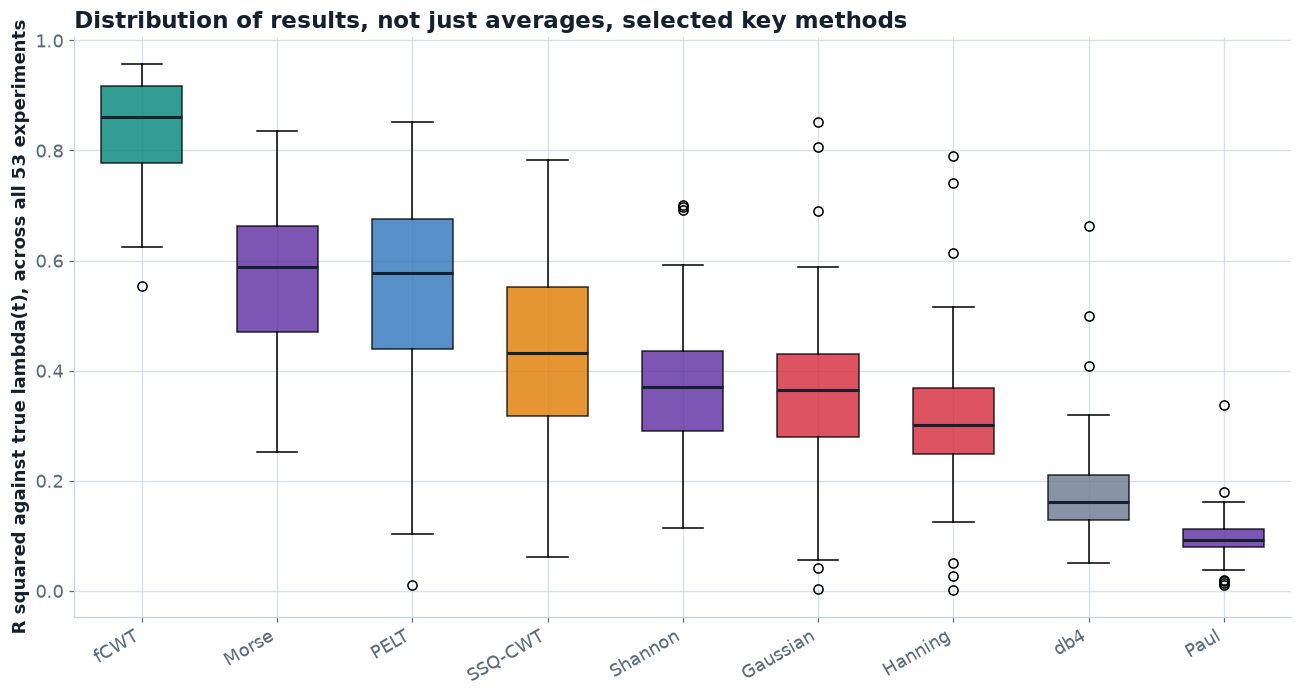

In [47]:
print("STATISTICAL SIGNIFICANCE TESTING")
print("=" * 78)
print("A higher mean R squared is only meaningful if the gap between methods")
print("is unlikely to be random chance. This section tests that directly using")
print("the Mann-Whitney U test, a standard test for comparing two groups of")
print("numbers that does not assume they follow a normal, bell-curve")
print("distribution, which matters here since R squared values are not")
print("symmetric. A p-value below 0.05 is the conventional threshold for")
print("calling a difference statistically significant.")
print()

significance_comparisons = [
    ("fCWT",  "STFT-Gaussian", "fCWT vs the best Fourier baseline"),
    ("fCWT",  "Morse",         "fCWT vs the best regular CWT wavelet"),
    ("fCWT",  "PELT",          "fCWT vs PELT (the non-wavelet alternative)"),
    ("Morse", "STFT-Gaussian", "Best CWT wavelet vs the best Fourier baseline"),
    ("PELT",  "STFT-Gaussian", "PELT vs the best Fourier baseline"),
]

method_name_lookup = {"STFT-Gaussian": "Gaussian", "STFT-Hanning": "Hanning"}

significance_results = []

for method_a_label, method_b_label, comparison_description in significance_comparisons:
    method_a_key = method_name_lookup.get(method_a_label, method_a_label)
    method_b_key = method_name_lookup.get(method_b_label, method_b_label)

    values_a = cross_validation_frame[cross_validation_frame["method"] == method_a_key]["r_squared"].dropna().values
    values_b = cross_validation_frame[cross_validation_frame["method"] == method_b_key]["r_squared"].dropna().values

    if len(values_a) < 3 or len(values_b) < 3:
        continue

    u_statistic, p_value = scipy_stats.mannwhitneyu(values_a, values_b, alternative="two-sided")

    significance_results.append({
        "comparison": comparison_description,
        "method_a": method_a_label, "mean_a": np.mean(values_a),
        "method_b": method_b_label, "mean_b": np.mean(values_b),
        "u_statistic": u_statistic, "p_value": p_value,
    })

significance_table = pd.DataFrame(significance_results)

number_of_tests = len(significance_table)
bonferroni_threshold = 0.05 / number_of_tests

print("PAIRWISE COMPARISONS")
print("=" * 78)
print(f"Running {number_of_tests} comparisons. Since testing several pairs at once")
print(f"raises the chance of a false positive by luck alone, a Bonferroni-")
print(f"corrected threshold is used: 0.05 / {number_of_tests} = {bonferroni_threshold:.4f}, rather than")
print("the usual 0.05, for a result to count as significant here.")
print()

for _, row in significance_table.iterrows():
    print(f"{row['comparison']}")
    print(f"   Mean R sq, {row['method_a']:<14}: {row['mean_a']:.4f}")
    print(f"   Mean R sq, {row['method_b']:<14}: {row['mean_b']:.4f}")
    print(f"   p-value                       : {row['p_value']:.2e}")
    if row["p_value"] < bonferroni_threshold:
        print(f"   Result                         : SIGNIFICANT (survives Bonferroni correction)")
    elif row["p_value"] < 0.05:
        print(f"   Result                         : significant at 0.05, but NOT after Bonferroni correction")
    else:
        print(f"   Result                         : not significant")
    print()

print("HONEST FAMILY-LEVEL CHECK")
print("=" * 78)
print("Pooling every CWT wavelet together and testing against STFT, the same")
print("honest check run earlier on a single experiment, now repeated properly")
print("across all 53.")
print()

cwt_pooled_values = cross_validation_frame[cross_validation_frame["family"] == "CWT"]["r_squared"].dropna().values
stft_pooled_values = cross_validation_frame[cross_validation_frame["family"] == "STFT"]["r_squared"].dropna().values
dwt_pooled_values  = cross_validation_frame[cross_validation_frame["family"] == "DWT"]["r_squared"].dropna().values

u_stat, p_val = scipy_stats.mannwhitneyu(cwt_pooled_values, stft_pooled_values, alternative="two-sided")
cwt_mean, stft_mean = np.mean(cwt_pooled_values), np.mean(stft_pooled_values)
print(f"All CWT wavelets pooled (n={len(cwt_pooled_values)}) vs STFT pooled (n={len(stft_pooled_values)})")
print(f"   Mean R sq, CWT pooled  : {cwt_mean:.4f}")
print(f"   Mean R sq, STFT pooled : {stft_mean:.4f}")
print(f"   p-value                : {p_val:.4f}")
if p_val < 0.05:
    direction = "WORSE" if cwt_mean < stft_mean else "better"
    print(f"   Result                 : significant, pooled CWT is significantly {direction} than STFT")
else:
    print(f"   Result                 : not significant")
print()

u_stat, p_val = scipy_stats.mannwhitneyu(dwt_pooled_values, stft_pooled_values, alternative="two-sided")
print(f"All DWT wavelets pooled (n={len(dwt_pooled_values)}) vs STFT pooled (n={len(stft_pooled_values)})")
print(f"   Mean R sq, DWT pooled  : {np.mean(dwt_pooled_values):.4f}")
print(f"   Mean R sq, STFT pooled : {np.mean(stft_pooled_values):.4f}")
print(f"   p-value                : {p_val:.2e}")
print(f"   Result                 : significant, and in DWT's case, significantly WORSE")


figure, axis = plt.subplots(figsize=(12, 6.5))
key_methods_for_boxplot = ["fCWT", "Morse", "PELT", "SSQ-CWT", "Shannon", "Gaussian", "Hanning", "db4", "Paul"]
box_data, box_labels, box_colours = [], [], []
family_plot_colours = {"CWT": COLOUR_RUNNERUP, "DWT": COLOUR_NEUTRAL, "STFT": COLOUR_BASELINE,
                       "fCWT": COLOUR_WINNER, "SSQ-CWT": COLOUR_ACCENT, "PELT": "#2E76BC"}

for method_name in key_methods_for_boxplot:
    values = cross_validation_frame[cross_validation_frame["method"] == method_name]["r_squared"].dropna().values
    if len(values) > 0:
        box_data.append(values)
        box_labels.append(method_name)
        family_name = cross_validation_frame[cross_validation_frame["method"] == method_name]["family"].iloc[0]
        box_colours.append(family_plot_colours.get(family_name, COLOUR_NEUTRAL))

box_plot_result = axis.boxplot(box_data, patch_artist=True, widths=0.6, vert=True)
for patch, colour in zip(box_plot_result["boxes"], box_colours):
    patch.set_facecolor(colour)
    patch.set_alpha(0.8)
for median_line in box_plot_result["medians"]:
    median_line.set_color(COLOUR_TEXT)
    median_line.set_linewidth(2.0)
axis.set_xticks(range(1, len(box_labels)+1))
axis.set_xticklabels(box_labels, rotation=30, ha="right")
axis.set_ylabel("R squared against true lambda(t), across all 53 experiments")
axis.set_title("Distribution of results, not just averages, selected key methods", loc="left")

plt.tight_layout()
plt.savefig("cell19_significance_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()